# 02 — Choix du modèle : ce qui est décidé, sur FD001

**Question du jury** : « Pourquoi ce modèle, ces variables et ces réglages ? »

Ce notebook rassemble, dans l'ordre où un lecteur se pose les questions, toutes les **décisions** prises sur FD001 : la cible, ce que voient les réseaux, les variables, les hyperparamètres des arbres et des réseaux, le diagnostic sur-apprentissage / sous-apprentissage, l'intérêt de données en plus. **Chaque section se termine par la décision et le chiffre qui la justifie** (règle 11 d'`AGENTS.md`, [`docs/protocole_evaluation.md`](../docs/protocole_evaluation.md)).

C'est une **réorganisation, pas une réécriture** ([`docs/plan_refonte_notebooks.md`](../docs/plan_refonte_notebooks.md), principe 0) : les cellules viennent des anciens notebooks (02, 03, 03b, 04b, 04c, 04d, 04e, 04f, 04g, 04h, 05) avec leur code, leurs commentaires et leurs explications ; seul le code recopié a été remplacé par l'appel à la fonction de `src/` qui fait la même chose. Les anciens notebooks restent consultables au tag `v1-avant-reorganisation`.

| Section | Décision | Vient de |
|---|---|---|
| 1. Mise en place | — | 03b (A.2), 05 (A.2) |
| 2. La cible | RUL plafonnée à 125 | 02 |
| 3. Les outils communs | features de base, score NASA, plis par moteur | 03 |
| 4. Ce que voient les réseaux | fenêtre, remplissage, `time_cycles` | 03b (A, B, C) |
| 5. Réseaux contre arbres | les réseaux valent leur coût | 03b (A.5, D) |
| 6. Les variables (ablation) | 31 variables, dont `ecartinit_20` | 04e |
| 7. L'écart à l'état initial sur les 5 modèles | `ecartinit_20` pour tous | 05 (F) |
| 8. Hyperparamètres des arbres | méthode Optuna et règle de décision | 04d |
| 9. Confirmation sur plis neufs, réglages finaux des arbres | `CONFIG_*_FINAL` | 04d, 04f, 04g |
| 10. Hyperparamètres des réseaux | ensemble de 5 LSTM (FD001 à FD004) | 04h, 03b (F.4) |
| 11. Biais / variance | variance modérée, plancher des features | 03 |
| 12. Plus de données ? | non prioritaire | 04c, 03b (D.5) |
| 13. L'alerte | régression + seuil, combien de cycles d'avance | 04b |
| 14. Décision finale | réglages retenus des 6 modèles | `src/config_modele.py`, `src/optimisation_reseaux.py` |

**À lire avant les chiffres : « uniquement les nouveaux modèles ».** La v2 du projet ne garde que les modèles retenus : arbres aux réglages finaux (`CONFIG_*_FINAL`) et réseaux du 04h (les 4 sous-jeux : FD001 et FD002 optimisés la nuit du 2026-11-07, FD003 et FD004 la nuit du 07 au 08 ; *mise à jour du 2026-11-08 : ce texte disait avant « FD001 et FD002 seulement »*). Plusieurs sections ci-dessous montrent pourtant un **ancien modèle** (XGBoost Phase 3 à 46 variables, réseaux du 03b à réglages fixés à l'avance) : c'est sur lui que la décision a été prise, au moment où elle l'a été. Ces sections sont signalées par **« Ce qui a fondé la décision (ancien modèle) »**. Les chiffres des modèles retenus, sous-jeu par sous-jeu, sont dans `notebooks/resultats/FD00X.ipynb`.

**Le test officiel ne sert à aucune décision dans ce notebook.** Il n'est lu que là où l'ancien notebook le lisait pour un repère déjà publié (XGBoost Phase 3, section 5 ; robustesse à la graine des réseaux du 03b, section 10).

**Exécution** : environ 30 minutes sur 4 cœurs (machine partagée), surtout les recherches Optuna des arbres (sections 8 et 9) et l'ablation (section 6), relancées ici. Les réseaux ne sont **jamais** réentraînés : leurs résultats sont relus dans `docs/resultats/04h/` (versionné) et dans `sorties/resultats/` (non versionné, produit par `scripts/entrainer_deep_learning.py` et `scripts/generer_predictions_arbres.py`).

## 1. Mise en place

Imports et réglages communs à tout le notebook. Trois contraintes techniques, déjà rencontrées dans les anciens notebooks :

- **xgboost avant torch** : si PyTorch est chargé avant xgboost dans le même processus, XGBoost plante ensuite dès qu'il calcule sur plusieurs cœurs (conflit entre deux copies de la bibliothèque OpenMP, constaté le 2026-11-04 ; explication en tête de `src/deep_learning.py` et en section 5 ci-dessous). Les modules du projet qui chargent xgboost sont donc importés en premier.
- **PyTorch sur 1 cœur** : ce notebook ne fait que de petites démonstrations avec PyTorch (aucun entraînement).
- **4 cœurs au plus pour les arbres** : la machine est partagée avec d'autres calculs. On a vérifié que XGBoost donne exactement les mêmes prédictions sur 1, 4 ou 15 cœurs (RMSE de validation croisée identique au dernier chiffre près) : ce réglage ne change aucun résultat, seulement la durée.

In [1]:
import sys
sys.path.insert(0, "..")  # le dossier parent de notebooks/ (racine du depot) devient importable : "from src ..." marche

import os
import warnings

# avertissement d'affichage de tqdm (barre de progression d'Optuna), sans effet sur les calculs : masque, pour ne pas
# publier dans les sorties un chemin de la machine qui a execute le notebook
warnings.filterwarnings("ignore", message="IProgress not found")

# Machine partagee : au plus 4 coeurs pour les modeles a arbres. La variable OMP_NUM_THREADS doit etre fixee
# AVANT d'importer xgboost (elle plafonne le nombre de coeurs de la bibliotheque OpenMP) ; on passe aussi
# n_jobs=NB_COEURS explicitement a chaque modele construit dans ce notebook.
NB_COEURS = 4
os.environ["OMP_NUM_THREADS"] = str(NB_COEURS)

# bibliotheques standard de Python
import copy  # deepcopy : copie independante d'un dictionnaire (l'original reste intact)
import json  # lecture des resultats enregistres par les scripts
import time  # chronometres

# calcul, tableaux, figures
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Ordre volontaire : les modules du projet qui chargent xgboost et lightgbm AVANT torch (voir ci-dessus)
from src.config_modele import (
    CONFIG_LIGHTGBM_FINAL,           # LightGBM, reglages finaux (Optuna, 04g)
    CONFIG_PHASE3,                   # XGBoost Phase 3 (46 variables, reglages fixes a la main)
    CONFIG_RANDOM_FOREST_FINAL,      # Random Forest, reglages finaux (Optuna, 04g)
    CONFIG_REFERENCE_NAIVE,          # baseline : predit toujours la moyenne
    CONFIG_XGBOOST_FINAL,            # XGBoost, reglages finaux (Optuna, 04f)
    construire_fabrique_depuis_config,
    decrire_config,
)
from src.evaluation import (
    calculer_plis,                   # les 5 plis de validation croisee par moteur
    comparer_apparie,                # test t apparie + test de Wilcoxon signe
    erreurs_par_moteur,              # RMSE moteur par moteur
    evaluer_en_validation_croisee,   # entraine et evalue un modele sur les 5 plis
    evaluer_sur_test,                # evalue un modele deja entraine sur le test officiel
    nb_surestimes,                   # nombre de predictions surestimees de plus d'un seuil
    rmse,                            # racine de l'erreur quadratique moyenne
    score_nasa,                      # score asymetrique NASA (13 / 10)
)
from src.features import preparer_test, preparer_train  # pipeline des Phases 1 a 3 (et option ecart_initial)
from src.deep_learning import (
    ECHELLE_CIBLE,
    LONGUEUR_FENETRE_DEFAUT,
    ajouter_time_cycles_echelle,
    compter_parametres,
    configurer_torch,
    construire_fenetres,
    creer_modele,
    lister_colonnes_entree,
    predire,
)
from src.sous_jeux import charger_sous_jeu

import torch  # apres les modules du projet (voir ci-dessus)

configurer_torch(1)  # PyTorch sur 1 coeur (src/deep_learning.py)


def config_sur_n_coeurs(config):
    """
    Renvoie une copie d'une configuration de src/config_modele.py, limitee a NB_COEURS coeurs.

    Le nombre de coeurs ne change pas les predictions (verifie pour XGBoost ; Random Forest et LightGBM
    sont deterministes a graine fixee), seulement la duree : la machine est partagee avec d'autres calculs.

    Parameters
    ----------
    config : dict
        Une configuration valide (CONFIG_PHASE3, CONFIG_XGBOOST_FINAL, ...). Elle n'est pas modifiee.

    Returns
    -------
    dict
        La copie, avec hyperparametres["n_jobs"] = NB_COEURS.
    """
    copie = copy.deepcopy(config)  # copie independante : la configuration du projet reste intacte
    copie["hyperparametres"]["n_jobs"] = NB_COEURS  # meme modele, sur 4 coeurs au plus
    return copie


DOSSIER_RESULTATS = os.path.join("..", "sorties", "resultats")  # resultats des scripts (non versionnes)
DOSSIER_04H = os.path.join("..", "docs", "resultats", "04h")    # resultats Optuna des reseaux (versionnes)
# resultats du 03b, execution du 2026-11-04 (versionnes ; README du dossier) : la meme que STATUS.md et evolution
DOSSIER_03B = os.path.join("..", "docs", "resultats", "03b")

pd.set_option("display.width", 220)  # tableaux affiches sur une ligne plus large
pd.set_option("display.max_columns", 40)  # toutes les colonnes affichees
debut_notebook = time.perf_counter()  # chronometre de l'execution complete du notebook
print(f"xgboost charge avant torch : {'xgboost' in sys.modules} ; torch {torch.__version__} sur "
      f"{torch.get_num_threads()} coeur ; arbres sur {NB_COEURS} coeurs au plus")

xgboost charge avant torch : True ; torch 2.15.0 sur 1 coeur ; arbres sur 4 coeurs au plus


## 2. La cible : RUL plafonnée à 125 cycles (Piecewise Linear RUL)

*Repris du notebook `02_target_engineering` (Phase 2).*

Objectif de cette section : construire la vraie cible d'entraînement, la RUL (Remaining Useful Life), à partir de `train_FD001.txt`, puis la plafonner à 125 cycles comme convenu dans le cahier des charges.

### 2.1 Chargement des données

On reprend les mêmes colonnes et la même fonction de chargement que dans le notebook de la Phase 1, pour rester cohérent avec le format du fichier brut NASA. Elles vivent dans `src/preprocessing.py` (`COLUMNS`, `load_fd001`) : on les importe au lieu de les recopier.

In [2]:
from src.preprocessing import COLUMNS, DATA_DIR, load_fd001  # 26 colonnes du fichier brut et chargement (Phase 1)

# Les 26 colonnes : unit_number, time_cycles, 3 reglages operationnels, puis les 21 capteurs bruts
# (ici on garde les 21 capteurs du fichier brut, y compris les 6 retires en Phase 1 : cette section ne
# calcule que la RUL a partir de unit_number/time_cycles, elle ne lit aucun capteur)
print(f"{len(COLUMNS)} colonnes : {COLUMNS[:5]} ... {COLUMNS[-1]}")

26 colonnes : ['unit_number', 'time_cycles', 'op_setting_1', 'op_setting_2', 'op_setting_3'] ... sensor_21


In [3]:
# Colonnes = schema du fichier brut (26 colonnes fixes, imposees par le format NASA) ;
# la Phase 2 ne lit aucun capteur, seulement unit_number et time_cycles (voir cellule precedente)
train = load_fd001("train")  # chargement du fichier d'entrainement FD001
train.shape  # verification rapide : on doit retrouver (20631, 26)

(20631, 26)

### 2.2 Calcul de la vraie RUL par cycle

Le fichier brut ne donne que le numero du cycle en cours (`time_cycles`), jamais directement
le nombre de cycles restants avant la panne. Mais dans `train_FD001.txt`, chaque moteur est suivi
**jusqu'a sa panne** : le dernier cycle enregistre pour un moteur correspond donc au moment de la panne.

La RUL a un cycle donne se calcule donc ainsi :

`RUL = dernier_cycle_du_moteur - cycle_actuel`

Exemple concret : si le moteur 1 a son dernier cycle enregistre a 200, alors au cycle 150,
sa RUL vaut 200 - 150 = 50 cycles restants.

In [4]:
# Ici, on cree une colonne vide qui recevra la RUL calculee pour chaque ligne
train["RUL"] = 0  # valeur provisoire, remplacee ligne par ligne juste apres

# On parcourt chaque moteur un par un
for moteur_id in train["unit_number"].unique():  # unique() donne la liste des identifiants de moteurs
    masque = train["unit_number"] == moteur_id  # Vrai sur les lignes de ce moteur, Faux sinon

    # Le dernier cycle enregistre pour ce moteur correspond a sa panne
    dernier_cycle = train.loc[masque, "time_cycles"].max()  # valeur maximale de time_cycles pour ce moteur

    # La RUL de chaque ligne de ce moteur est la distance a ce dernier cycle
    train.loc[masque, "RUL"] = dernier_cycle - train.loc[masque, "time_cycles"]

train[["unit_number", "time_cycles", "RUL"]].head()  # verification rapide sur les premieres lignes

,unit_number,time_cycles,RUL
0,1,1,191
1,1,2,190
2,1,3,189
3,1,4,188
4,1,5,187


### 2.3 Vérification : la RUL doit décroître jusqu'à 0 à la panne

Pour le moteur 1, on regarde les toutes dernières lignes : la RUL doit valoir exactement 0
sur la toute dernière ligne (le cycle de la panne), et augmenter en remontant dans le temps.

In [5]:
masque_moteur_1 = train["unit_number"] == 1  # on isole le moteur 1
train.loc[masque_moteur_1, ["time_cycles", "RUL"]].tail()  # les 5 dernieres lignes de ce moteur

,time_cycles,RUL
187,188,4
188,189,3
189,190,2
190,191,1
191,192,0


### 2.4 Plafonnement de la RUL à 125 cycles (Piecewise Linear RUL)

En tout début de vie, les capteurs d'un moteur varient à peine d'un cycle à l'autre — le signal ne montre
presque aucun signe de dégradation. Pourtant, la RUL brute peut y valoir 300, 280, 250... Demander au modèle
de distinguer une RUL de 300 d'une RUL de 280 à partir d'un signal quasiment plat est une tâche impossible :
il n'y a simplement pas assez d'information dans les capteurs à ce stade pour le justifier.

La solution retenue par la quasi-totalité des projets de la communauté (et par notre cahier des charges) :
**plafonner la RUL à 125 cycles**. Concrètement : tant que la RUL brute dépasse 125, on la remplace par 125 ;
en dessous de 125, on garde la RUL brute inchangée. La courbe résultante est plate au début (à 125),
puis décroît linéairement jusqu'à 0 à la panne — d'où le nom "Piecewise Linear RUL" (RUL linéaire par morceaux).

In [6]:
PLAFOND_RUL = 125  # plafond retenu, cf. cahier des charges section 3

# Ici, on cree la colonne RUL plafonnee, ligne par ligne
train["RUL_cappee"] = 0  # valeur provisoire

for index_ligne in train.index:  # on parcourt chaque ligne du tableau une par une
    rul_brute = train.loc[index_ligne, "RUL"]  # RUL brute de cette ligne

    if rul_brute > PLAFOND_RUL:  # si la RUL brute depasse le plafond
        train.loc[index_ligne, "RUL_cappee"] = PLAFOND_RUL  # on la remplace par le plafond
    else:  # sinon (RUL brute deja sous le plafond)
        train.loc[index_ligne, "RUL_cappee"] = rul_brute  # on la garde telle quelle

train[["unit_number", "time_cycles", "RUL", "RUL_cappee"]].head()  # verification rapide

,unit_number,time_cycles,RUL,RUL_cappee
0,1,1,191,125
1,1,2,190,125
2,1,3,189,125
3,1,4,188,125
4,1,5,187,125


### Preuve chiffrée : le signal est-il vraiment plus stable en début de vie ?

Un seul moteur ne prouve rien statistiquement — on refait le test sur 3 moteurs différents
(1, 50 et 100) plutôt que sur un seul, pour vérifier que le motif se reproduit.

Pour chaque moteur, on compare `sensor_11` sur la phase "début de vie" (RUL > 125) à la phase
"fin de vie" (RUL <= 125) : la moyenne et l'écart-type (la dispersion) des valeurs sur chaque phase.

In [7]:
# Liste des 3 moteurs a tester : un pris au debut, un au milieu, un a la fin de la liste des identifiants
# (un seul moteur ne suffirait pas a prouver un motif general, il faut le voir se repeter)
moteurs_a_tester = [1, 50, 100]
sensor_a_verifier = "sensor_11"  # capteur choisi pour la preuve (Ps30, deja etudie en Phase 1)

# On parcourt les 3 moteurs un par un, avec une boucle explicite (pas de comprehension)
for moteur_id in moteurs_a_tester:
    masque_moteur = train["unit_number"] == moteur_id  # Vrai sur les lignes de ce moteur, Faux sinon

    # Phase "debut de vie" : tous les cycles ou il reste plus de 125 vols (RUL brute > 125)
    masque_debut = masque_moteur & (train["RUL"] > PLAFOND_RUL)  # combine les deux conditions (ce moteur ET debut de vie)
    valeurs_debut = train.loc[masque_debut, sensor_a_verifier]  # les valeurs du capteur sur cette phase seulement

    # Phase "fin de vie" : tous les cycles ou il reste 125 vols ou moins (RUL brute <= 125)
    masque_fin = masque_moteur & (train["RUL"] <= PLAFOND_RUL)
    valeurs_fin = train.loc[masque_fin, sensor_a_verifier]

    # mean() = moyenne des valeurs sur la phase ; std() = ecart-type, la dispersion autour de cette moyenne
    ecart_moyenne = valeurs_fin.mean() - valeurs_debut.mean()  # de combien la moyenne a bouge entre les 2 phases
    ratio_dispersion = valeurs_fin.std() / valeurs_debut.std()  # combien de fois plus disperse en fin de vie

    # Affichage des resultats pour ce moteur, avant de passer au suivant
    print(f"Moteur {moteur_id} :")
    print(f"  debut de vie -> moyenne={valeurs_debut.mean():.3f}, ecart-type={valeurs_debut.std():.3f}")
    print(f"  fin de vie   -> moyenne={valeurs_fin.mean():.3f}, ecart-type={valeurs_fin.std():.3f}")
    print(f"  ecart de moyenne = {ecart_moyenne:+.3f}   dispersion x{ratio_dispersion:.2f} en fin de vie")
    print()  # ligne vide pour separer visuellement chaque moteur dans la sortie

Moteur 1 :
  debut de vie -> moyenne=47.299, ecart-type=0.121
  fin de vie   -> moyenne=47.627, ecart-type=0.256
  ecart de moyenne = +0.327   dispersion x2.12 en fin de vie

Moteur 50 :
  debut de vie -> moyenne=47.381, ecart-type=0.108
  fin de vie   -> moyenne=47.671, ecart-type=0.219
  ecart de moyenne = +0.289   dispersion x2.02 en fin de vie

Moteur 100 :
  debut de vie -> moyenne=47.401, ecart-type=0.089
  fin de vie   -> moyenne=47.713, ecart-type=0.238
  ecart de moyenne = +0.311   dispersion x2.66 en fin de vie



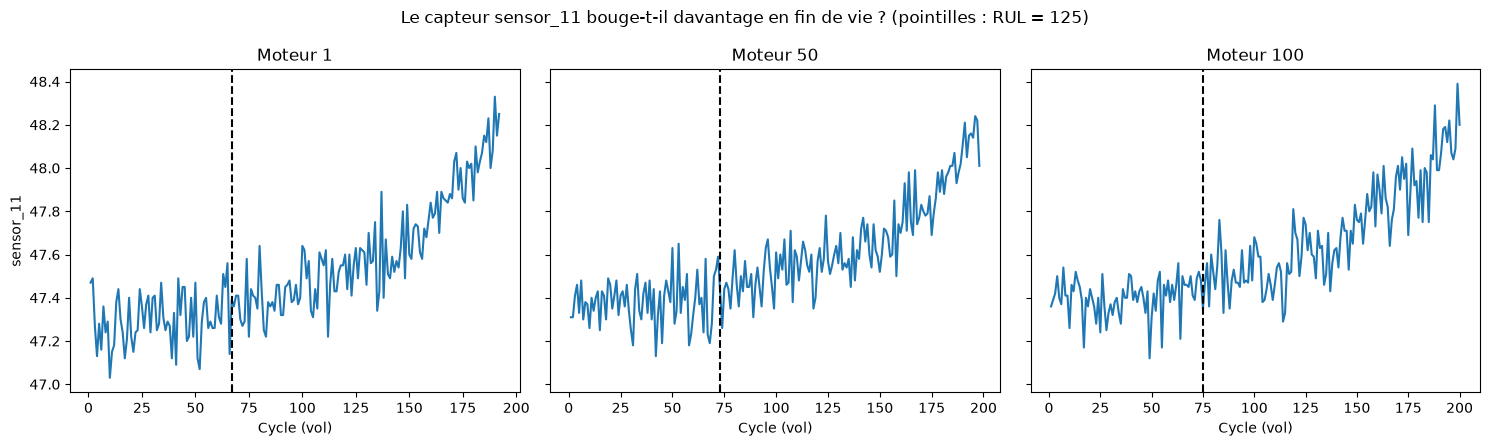

In [8]:
# Version graphique du meme test que la cellule precedente : un sous-graphique par moteur,
# pour voir a l'oeil ce qu'on vient de mesurer en chiffres (moyenne/ecart-type)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)  # 3 graphiques cote a cote, meme echelle verticale
# sharey=True : les 3 graphiques partagent la meme echelle sur l'axe vertical, pour pouvoir les comparer directement

# on parcourt les 3 moteurs avec enumerate() pour avoir a la fois la position (i = 0, 1, 2)
# et l'identifiant du moteur (moteur_id) ; i sert a choisir dans quel sous-graphique dessiner
for i, moteur_id in enumerate(moteurs_a_tester):
    masque_moteur = train["unit_number"] == moteur_id  # Vrai sur les lignes de ce moteur

    # on trace la courbe du capteur brut, cycle par cycle, dans le sous-graphique numero i
    axes[i].plot(
        train.loc[masque_moteur, "time_cycles"],   # axe horizontal : le numero du cycle
        train.loc[masque_moteur, sensor_a_verifier],  # axe vertical : la valeur du capteur
    )

    # meme logique que dans la cellule precedente : on retrouve le premier cycle ou la RUL passe sous 125
    masque_sous_plafond = masque_moteur & (train["RUL"] <= PLAFOND_RUL)
    premier_cycle_sous_plafond = train.loc[masque_sous_plafond, "time_cycles"].min()

    # ligne verticale en pointilles a cet endroit precis, pour separer visuellement les 2 phases
    axes[i].axvline(premier_cycle_sous_plafond, linestyle="--", color="black")
    axes[i].set_title(f"Moteur {moteur_id}")  # titre au-dessus de chaque sous-graphique
    axes[i].set_xlabel("Cycle (vol)")  # legende de l'axe horizontal, repetee sur les 3

axes[0].set_ylabel(sensor_a_verifier)  # une seule etiquette verticale, a gauche, partagee par les 3 graphiques
fig.suptitle(f"Le capteur {sensor_a_verifier} bouge-t-il davantage en fin de vie ? (pointilles : RUL = 125)")  # titre general = la question

plt.tight_layout()  # evite que les titres/legendes ne se chevauchent entre les 3 graphiques
plt.show()

### 2.5 Validation visuelle : RUL brute vs RUL plafonnée sur un moteur

C'est la validation attendue par le cahier des charges pour cette phase : une visualisation de la RUL brute
comparée à la RUL plafonnée sur un moteur, pour vérifier visuellement le plateau puis la décroissance linéaire.

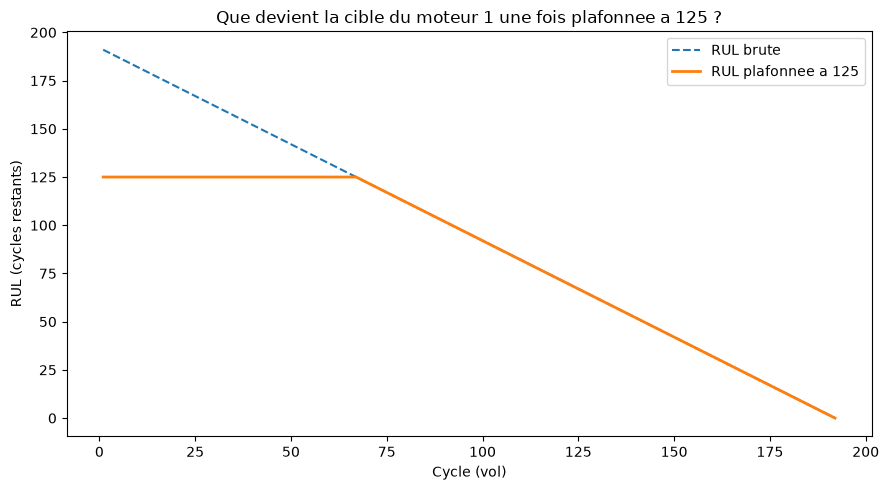

In [9]:
moteur_exemple = 1  # moteur choisi pour la visualisation finale de validation
masque_exemple = train["unit_number"] == moteur_exemple  # Vrai sur les lignes de ce moteur

fig, ax = plt.subplots(figsize=(9, 5))  # une seule figure, une seule paire d'axes

# 1ere courbe : la RUL brute (avant plafonnement), en pointilles pour bien la distinguer
ax.plot(
    train.loc[masque_exemple, "time_cycles"],  # axe horizontal : le cycle
    train.loc[masque_exemple, "RUL"],           # axe vertical : la RUL brute
    label="RUL brute",
    linestyle="--",
)
# 2eme courbe : la RUL plafonnee (apres application du plafond de 125), en trait plein et plus epais
ax.plot(
    train.loc[masque_exemple, "time_cycles"],
    train.loc[masque_exemple, "RUL_cappee"],
    label="RUL plafonnee a 125",
    linewidth=2,
)

ax.set_xlabel("Cycle (vol)")             # legende axe horizontal
ax.set_ylabel("RUL (cycles restants)")   # legende axe vertical
ax.set_title(f"Que devient la cible du moteur {moteur_exemple} une fois plafonnee a 125 ?")  # titre = la question
ax.legend()  # affiche la legende (RUL brute / RUL plafonnee) pour distinguer les 2 courbes

plt.tight_layout()  # evite que le titre/les legendes ne debordent de la figure
plt.show()

### Décision de la section 2

**Décision : la cible d'entraînement de tous les modèles est la RUL plafonnée à 125 cycles** (`PLAFOND_RUL = 125`, cahier des charges section 3).

**Chiffre qui la justifie** : sur les moteurs 1, 50 et 100, `sensor_11` est presque plat en début de vie et nettement plus dispersé en fin de vie : écart-type multiplié par 2,02 à 2,66 quand la RUL passe sous 125 (sortie de la cellule 2.4). Demander au modèle de distinguer une RUL de 300 d'une RUL de 280 sur un signal plat n'a pas de sens ; au-dessus de 125, la cible est donc constante.

**Coût accepté** : aucun modèle ne prédit au-delà de 125. Sur le test, les moteurs dont la vraie RUL dépasse 125 sont toujours sous-estimés (part de ces moteurs par sous-jeu : section 1 de `resultats/FD00X`).

## 3. Les outils communs à toutes les décisions : features de base, score NASA, validation croisée par moteur

*Repris du notebook `03_modelisation` (Phase 3), sections 1 à 7.* Ces trois outils servent à toutes les décisions qui suivent : les **features glissantes** et le cas du premier cycle (ce que `src/features.py` implémente), le **score NASA** (l'asymétrie surestimation / sous-estimation) et la **validation croisée par moteur** (`GroupKFold`).

**Ce qui a fondé la décision (ancien modèle)** : le modèle de cette section est le **XGBoost Phase 3** (46 variables, `n_estimators=200, max_depth=5, learning_rate=0.05`), qui a servi de référence jusqu'au notebook 04e. Son test officiel (RMSE 19,70) est dans `evolution`, étape 1.

On réutilise `src/preprocessing.py`, qui reprend exactement les fonctions déjà validées dans les notebooks de Phase 1 (chargement, capteurs constants, normalisation, lissage) et de Phase 2 (calcul de la RUL, plafonnement).

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupKFold
from xgboost import XGBRegressor

from src.preprocessing import (
    load_fd001, get_sensor_columns, find_constant_sensors,
    normalize_minmax, lisser_capteurs, calculer_rul, plafonner_rul, DATA_DIR,
)
# fonctions des features glissantes et du score NASA : definies une seule fois dans src/ (voir plus bas)
from src.features import ajouter_features_glissantes, construire_liste_features, lister_colonnes_suffixe, remplir_nan_ecarts_types
from src.evaluation import score_nasa

FENETRE = 5      # taille de la fenetre glissante, cf. Phase 1 (lissage) et README (benchmark)
PLAFOND_RUL = 125  # plafond de la RUL, cf. Phase 2

### 3.1 Pipeline Phases 1+2 sur le jeu d'entraînement

On enchaîne les étapes déjà validées : suppression des capteurs constants, normalisation min-max,
lissage par moyenne mobile (moteur par moteur), calcul de la RUL, puis plafonnement à 125 cycles.
Le `scaler` (min-max) est conservé : il faudra l'appliquer tel quel au jeu de test plus tard,
sans le ré-entraîner dessus (sinon fuite d'information entre train et test).

In [11]:
train = load_fd001("train")  # chargement du fichier d'entrainement FD001

sensor_cols = get_sensor_columns(train.columns)  # les 21 capteurs bruts
constant_sensors = find_constant_sensors(train, sensor_cols)  # capteurs a variance nulle (Phase 1)
train = train.drop(columns=constant_sensors)  # on les retire
sensor_cols_restants = get_sensor_columns(train.columns)  # les 15 capteurs informatifs restants

train, scaler = normalize_minmax(train, sensor_cols_restants)  # normalisation min-max (0 a 1), scaler garde pour le test
train = lisser_capteurs(train, sensor_cols_restants, fenetre=FENETRE)  # moyenne mobile, moteur par moteur
train = calculer_rul(train)  # RUL brute par cycle
train = plafonner_rul(train, plafond=PLAFOND_RUL)  # RUL plafonnee a 125

train.shape  # verification rapide : 20631 lignes, colonnes = 26 - 6 constants + RUL + RUL_cappee = 22

(20631, 22)

### 3.2 Features par fenêtre glissante

Une valeur de capteur isolée ne dit pas si le moteur est stable ou en train de se dégrader. On ajoute donc,
pour chaque capteur et chaque cycle, deux nouvelles colonnes calculées sur les 5 derniers cycles
(fenêtre glissante, comme le lissage de la Phase 1, mais ici pour créer des features, pas pour nettoyer le signal) :

- **moyenne glissante** : la tendance récente du capteur.
- **écart-type glissant** : sa dispersion récente — en Phase 2, on a prouvé que cette dispersion double ou
  triple en fin de vie (`sensor_11`) : c'est exactement ce que cette feature permet au modèle de voir.

La fenêtre "glisse" d'un cycle à l'autre : au cycle *t*, elle regarde les cycles *t-4* à *t* (jamais le futur),
et jamais au-delà du début de vie d'un même moteur (calcul refait moteur par moteur, comme le lissage).

La fonction `ajouter_features_glissantes` qui fait ce calcul est écrite une seule fois, dans `src/features.py` : c'est exactement celle de ce notebook à l'origine (même boucle capteur par capteur puis moteur par moteur, même `rolling(fenetre, min_periods=1)` causal). On l'appelle ici au lieu de la recopier.

In [12]:
# moyenne et ecart-type glissants sur les 5 derniers cycles, capteur par capteur et moteur par moteur
# (src/features.py, ajouter_features_glissantes : rolling() est causal et ne porte que sur un moteur a la fois)
train = ajouter_features_glissantes(train, sensor_cols_restants, FENETRE)

# apercu sur le moteur 1 : la valeur brute lissee, sa moyenne glissante et son ecart-type glissant
colonnes_apercu = ["time_cycles", "sensor_11", "sensor_11_glissante_moy", "sensor_11_glissante_std"]
train.loc[train["unit_number"] == 1, colonnes_apercu].head(8)

,time_cycles,sensor_11,sensor_11_glissante_moy,sensor_11_glissante_std
0,1,0.369048,0.369048,NaN
1,2,0.375000,0.372024,0.004209
2,3,0.333333,0.359127,0.022535
3,4,0.291667,0.342262,0.038422
4,5,0.284524,0.330714,0.042118
5,6,0.247619,0.306429,0.048944
6,7,0.232143,0.277857,0.039739
7,8,0.228571,0.256905,0.029468


### 3.3 Cas particulier : le tout premier cycle de chaque moteur

Au tout premier cycle d'un moteur, la fenêtre glissante ne contient qu'**une seule valeur** — l'écart-type
d'une seule valeur n'existe pas mathématiquement (il faut au moins 2 points pour mesurer une dispersion),
`pandas` renvoie donc `NaN` à cet endroit précis. Ça concerne exactement 1 ligne par moteur par capteur,
soit 100 moteurs × 15 capteurs = 1500 valeurs sur les 20 631 lignes du tableau.

On remplace ces `NaN` par 0 : au tout premier cycle, on n'a encore observé aucune variation, donc une
dispersion de 0 est la valeur la plus honnête qu'on puisse donner au modèle (pas une approximation
hasardeuse, une absence d'information réelle).

In [13]:
# noms des colonnes "ecart-type glissant" : celles dont le nom finit par "_glissante_std"
# (src/features.py, lister_colonnes_suffixe : la meme boucle explicite que dans le notebook 03)
colonnes_ecart_type = lister_colonnes_suffixe(train.columns, "_glissante_std")

nb_nan_avant = train[colonnes_ecart_type].isna().sum().sum()  # total de NaN sur toutes les colonnes d'ecart-type
# remplace ces NaN par 0, en verifiant qu'il y en a exactement 1 par moteur et par capteur (src/features.py)
train = remplir_nan_ecarts_types(train, colonnes_ecart_type, nb_nan_attendu=100 * len(sensor_cols_restants))
nb_nan_apres = train[colonnes_ecart_type].isna().sum().sum()

print(f"NaN sur les ecarts-types glissants : {nb_nan_avant} avant remplissage, {nb_nan_apres} apres.")

NaN sur les ecarts-types glissants : 1500 avant remplissage, 0 apres.


### 3.4 Construction des features et de la cible

Les features (`X`) sont les 15 capteurs lissés + leurs 15 moyennes glissantes + leurs 15 écarts-types
glissants + `time_cycles` (le numéro du cycle en cours), soit **46 colonnes**. La cible (`y`) est
`RUL_cappee` (Phase 2). `groups` retient le numéro de moteur de chaque ligne — indispensable pour la
validation croisée par moteur juste après.

**`time_cycles`** a été ajouté après un test d'ablation (section 11 du notebook 03, consultable au tag v1 ; remplacée par l'ablation du 04e, section 6 ci-dessous) : en validation
croisée, il améliore nettement le RMSE et le score NASA. Il est connu au moment de prédire (sur le test,
c'est le dernier cycle observé du moteur) et n'est pas normalisé (XGBoost est insensible à l'échelle).
**`unit_number`**, lui, reste exclu : c'est une étiquette de moteur, pas une mesure, et un nouveau moteur
n'a pas de numéro qui ait un sens pour le modèle.

In [14]:
# noms des colonnes "moyenne glissante" : celles dont le nom finit par "_glissante_moy" (src/features.py)
colonnes_moyenne = lister_colonnes_suffixe(train.columns, "_glissante_moy")

# 15 capteurs lisses + 15 moyennes + 15 ecarts-types + le numero de cycle en cours = 46 colonnes
# (src/features.py, construire_liste_features : meme ordre que le notebook 03). unit_number reste exclu :
# c'est une etiquette de moteur, pas une mesure (un nouveau moteur n'a pas de numero qui ait un sens).
feature_cols = construire_liste_features(sensor_cols_restants, colonnes_moyenne, colonnes_ecart_type)

X = train[feature_cols]        # les 46 colonnes de features (entrees du modele)
y = train["RUL_cappee"]        # la cible a predire (Phase 2)

# groups sert UNIQUEMENT a GroupKFold plus bas, pour savoir quelles lignes appartiennent au meme moteur.
# scikit-learn ne connait pas le nom "unit_number" : on lui donnera juste cette suite de nombres
# (1,1,1,...,2,2,2,...,100,100), sans aucun contexte. C'est NOUS qui choisissons cette colonne
# precisement parce qu'elle represente "quel moteur" - si on se trompait de colonne ici (par exemple
# time_cycles), le code tournerait quand meme, sans erreur, mais grouperait n'importe quoi.
groups = train["unit_number"]

print(f"Nombre de features : {len(feature_cols)} ({len(sensor_cols_restants)} capteurs lisses + {len(colonnes_moyenne)} moyennes + {len(colonnes_ecart_type)} ecarts-types + time_cycles)")
print(f"X : {X.shape}, y : {y.shape}")

Nombre de features : 46 (15 capteurs lisses + 15 moyennes + 15 ecarts-types + time_cycles)
X : (20631, 46), y : (20631,)


### 3.5 Le score NASA (Saxena et al., 2008)

Le RMSE traite une surestimation et une sous-estimation de la RUL de façon symétrique. Or le coût réel
ne l'est pas : sous-estimer la RUL entraîne une maintenance un peu prématurée (coût faible), tandis que
la surestimer risque une panne en vol (coût élevé). Le score NASA formalise cette asymétrie :

- si `d = RUL_prédite - RUL_vraie` est **négatif** (sous-estimation, prudent) : pénalité `exp(-d/13) - 1`
- si `d` est **positif** (surestimation, dangereux) : pénalité `exp(d/10) - 1` — croît beaucoup plus vite

Exemple : un écart de 20 cycles coûte `exp(20/13)-1 ≈ 3.66` en sous-estimation, mais `exp(20/10)-1 ≈ 6.39`
en surestimation — near le double, pour le même écart en valeur absolue.

La fonction `score_nasa` est écrite une seule fois, dans `src/evaluation.py` (même boucle, mêmes constantes 13 et 10) ; on garde ici son contrôle sur un exemple calculé à la main.

In [15]:
# score_nasa vient de src/evaluation.py (importe en tete de section) : SOMME des penalites individuelles,
# exp(-d/13) - 1 si d = prediction - verite < 0 (sous-estimation), exp(d/10) - 1 sinon (surestimation)

# sanity check avant utilisation reelle : on verifie la fonction sur un exemple ou le calcul a la main est simple
test_surestimation = score_nasa([100], [120])  # d = +20
test_sousestimation = score_nasa([100], [80])  # d = -20
print(f"surestimation +20 : {test_surestimation:.3f} (attendu {np.exp(2) - 1:.3f})")
print(f"sous-estimation -20 : {test_sousestimation:.3f} (attendu {np.exp(20 / 13) - 1:.3f})")
assert abs(test_surestimation - (np.exp(2) - 1)) < 0.01
assert abs(test_sousestimation - (np.exp(20 / 13) - 1)) < 0.01

surestimation +20 : 6.389 (attendu 6.389)
sous-estimation -20 : 3.657 (attendu 3.657)


### 3.6 Validation croisée par moteur (GroupKFold)

Si on répartissait les lignes au hasard entre entraînement et validation, des cycles du **même moteur**
pourraient se retrouver des deux côtés. Le modèle apprendrait alors en partie à reconnaître ce moteur
précis plutôt qu'un patron général de dégradation — une fuite d'information qui rendrait le score de
validation artificiellement optimiste, sans rapport avec la performance réelle sur un moteur jamais vu.

`GroupKFold` avec `unit_number` comme groupe garantit qu'un moteur donné va **entièrement** d'un côté
(train) ou de l'autre (validation), jamais coupé en deux. On vérifie ça explicitement à chaque pli.

**`shuffle=True, random_state=42`** : par défaut, `GroupKFold` répartit les moteurs entre les plis selon
l'ordre où ils apparaissent dans le fichier, pas au hasard — si cet ordre correspondait à autre chose
qu'un simple ordre de simulation (par exemple des moteurs triés par robustesse), ça pourrait biaiser
chaque pli sans qu'on le sache. Vérifié : avec `shuffle=True`, le RMSE moyen ne change presque pas
(18.61 sans mélange vs 18.64 avec) — donc pas de biais cachés ici — mais on garde le mélange (avec une
graine fixe pour rester reproductible) pour ne plus jamais avoir à supposer que l'ordre du fichier n'a
pas d'importance.

In [16]:
# gkf.split(...) est une fonction de la bibliotheque scikit-learn (pas notre code) : c'est A L'INTERIEUR
# d'elle, invisible ici, qu'elle regarde les valeurs uniques de "groups" (les 100 moteurs), decide
# comment les repartir en 5 paquets (melanges grace a shuffle=True, random_state=42 pour rester
# reproductible), puis traduit chaque paquet de moteurs en liste de numeros de ligne. On ne voit que
# le resultat (idx_train, idx_val), jamais le mecanisme interne - d'ou la verification juste en dessous.
gkf = GroupKFold(n_splits=5, shuffle=True, random_state=42)
rmse_par_fold = []
rmse_train_par_fold = []  # erreur sur les moteurs APPRIS, pour le diagnostic biais/variance (section 11)
nasa_par_fold = []

for i, (idx_train, idx_val) in enumerate(gkf.split(X, y, groups=groups)):  # 5 plis
    # idx_train / idx_val = juste des listes de numeros de ligne pour ce tour precis,
    # differentes a chaque iteration de la boucle
    X_tr, X_val = X.iloc[idx_train], X.iloc[idx_val]
    y_tr, y_val = y.iloc[idx_train], y.iloc[idx_val]

    # verification explicite qu'aucun moteur n'apparait des deux cotes de ce pli : on ne fait pas
    # confiance aveuglement au mecanisme cache de GroupKFold, on verifie le resultat nous-memes
    moteurs_train = set(groups.iloc[idx_train])
    moteurs_val = set(groups.iloc[idx_val])
    assert len(moteurs_train & moteurs_val) == 0, "un moteur est present des deux cotes !"

    # un modele TOUT NEUF a chaque tour (recree dans la boucle) : aucune memoire du tour precedent
    modele = XGBRegressor(n_estimators=200, max_depth=5, learning_rate=0.05, random_state=42, n_jobs=NB_COEURS)
    modele.fit(X_tr, y_tr)           # apprend uniquement sur les moteurs de ce tour
    y_pred = modele.predict(X_val)   # predit sur des moteurs jamais vus par ce modele
    y_pred_train = modele.predict(X_tr)  # predit sur les moteurs qu'il vient d'apprendre (erreur train)

    # meme calcul de RMSE qu'a la main (racine de la moyenne des ecarts au carre)
    rmse_pli = np.sqrt(np.mean((y_val.values - y_pred) ** 2))  # (renomme : ne pas masquer la fonction rmse de src/)
    nasa = score_nasa(y_val.values, y_pred)
    rmse_train = np.sqrt(np.mean((y_tr.values - y_pred_train) ** 2))  # meme formule, cote train
    rmse_par_fold.append(rmse_pli)  # on stocke pour faire la moyenne des 5 tours a la fin
    rmse_train_par_fold.append(rmse_train)
    nasa_par_fold.append(nasa)

    print(f"Pli {i + 1} : {len(moteurs_train)} moteurs train / {len(moteurs_val)} moteurs val -> RMSE train={rmse_train:.2f}, RMSE val={rmse_pli:.2f}, score NASA val={nasa:.1f}")

print(f"\nMoyenne sur les 5 plis : RMSE val={np.mean(rmse_par_fold):.2f}, score NASA val={np.mean(nasa_par_fold):.1f}")
print(f"RMSE train moyen (moteurs appris) : {np.mean(rmse_train_par_fold):.2f} -> interpretation en section 11")

Pli 1 : 80 moteurs train / 20 moteurs val -> RMSE train=11.17, RMSE val=15.17, score NASA val=19024.1


Pli 2 : 80 moteurs train / 20 moteurs val -> RMSE train=10.56, RMSE val=18.79, score NASA val=24855.2


Pli 3 : 80 moteurs train / 20 moteurs val -> RMSE train=11.03, RMSE val=17.29, score NASA val=40402.5


Pli 4 : 80 moteurs train / 20 moteurs val -> RMSE train=11.00, RMSE val=15.90, score NASA val=30488.2


Pli 5 : 80 moteurs train / 20 moteurs val -> RMSE train=10.95, RMSE val=17.19, score NASA val=34142.8

Moyenne sur les 5 plis : RMSE val=16.87, score NASA val=29782.6
RMSE train moyen (moteurs appris) : 10.94 -> interpretation en section 11


### Décision de la section 3

**Décisions** (valables pour tout le projet) :

1. **Validation croisée par moteur** : `GroupKFold(n_splits=5, shuffle=True, random_state=42)` (`calculer_plis` de `src/evaluation.py`), les **mêmes plis** pour tous les modèles ; aucun moteur n'est des deux côtés d'un pli (vérifié par `assert` à chaque pli).
2. **Score NASA d'évaluation** : constantes officielles 13 / 10, jamais modifiées (contrôlé sur un exemple calculé à la main).
3. **Référence des décisions suivantes** (jusqu'au 04e) : XGBoost Phase 3, RMSE de validation croisée moyen **16,87** sur ces 5 plis (sortie de la cellule 3.6 ; 16,86 dans `docs/03_modelisation.md`).

## 4. Ce que voient les réseaux : la fenêtre glissante, et le choix des entrées

*Repris du notebook `03b_deep_learning_lstm_cnn` (sections A.1, A.3, A.4, B et C).* Le cahier des charges (section 5, Phase 3) prévoit, après les modèles à arbres, un **LSTM** (obligatoire) et un **CNN 1D** (fortement recommandé). Cette section explique **chaque notion avant son code**, une à la fois, avec un exemple tiré de nos moteurs.

**Ce qui a fondé la décision (ancien modèle)** : les réseaux décrits ici sont ceux du 03b, à réglages fixés à l'avance (2 × 64 unités, fenêtre de 30 cycles). Les réseaux retenus en v2 sont ceux du 04h, plus petits et à fenêtre de 20 cycles (section 10) : les notions sont les mêmes, seuls les réglages changent.

### 4.1 Règles méthodologiques (fixées avant tout résultat)

1. **Le jeu de test ne sert jamais à choisir quoi que ce soit** : ni les entrées du réseau, ni le nombre
   d'époques, ni l'architecture. Tout choix se fait sur des moteurs de validation tirés du **train**.
2. **Les mêmes 5 plis que la Phase 4** (`calculer_plis` : `GroupKFold`, mélangé, graine 42) : un réseau et un
   XGBoost sont jugés sur exactement les mêmes moteurs de validation.
3. **Une prédiction par ligne (cycle)**, dans le même ordre que les lignes du train : les prédictions hors-pli
   des réseaux s'alignent ligne à ligne sur celles des arbres, ce qui permet les tests appariés.
4. **Réglages des réseaux fixés à l'avance, non optimisés** (pas de recherche d'hyperparamètres pour les réseaux,
   faute de temps de calcul ; *mise à jour : la recherche a été faite ensuite, au 04h, section 10 de ce notebook*). La référence est XGBoost Phase 3, avec les réglages de la Phase 3 (la recherche
   d'hyperparamètres du notebook 04d conclut de ne pas les changer) : aucun des deux n'a été réglé sur ces plis.
5. **Statuts honnêtes** : si le deep learning ne bat pas XGBoost, c'est écrit tel quel.

Les réglages des réseaux : seuils de lecture (les mêmes qu'en Phase 4), dossier des résultats, nombre de cœurs de PyTorch et couleurs des figures. Les fonctions de deep learning sont dans `src/deep_learning.py` ; les métriques, les plis et les tests appariés viennent de `src/evaluation.py` (importés en section 1).

In [17]:
LONGUEUR_FENETRE = LONGUEUR_FENETRE_DEFAUT  # 30 cycles (justifie en section B.5)
SEUIL_SURESTIMATION = 20  # cycles : surestimation dangereuse (choix de la Phase 3)
SEUIL_ALERTE = 30         # cycles : seuil d'envoi en maintenance, HYPOTHESE DE TRAVAIL
PLAFOND_RUL = 125         # plafond de la RUL (Phase 2)

DOSSIER_RESULTATS = os.path.join("..", "sorties", "resultats")  # ecrits par les scripts (non versionnes)

# PyTorch sur 1 coeur (reglage de src/deep_learning.py, rappele ici) : ce notebook fait aussi calculer XGBoost dans
# le meme processus, et un calcul PyTorch multi-coeurs peut alors se bloquer (conflit entre deux bibliotheques
# OpenMP, constate le 2026-11-04 dans la suite pytest). 1 coeur suffit pour les petites demonstrations ci-dessous.
configurer_torch(1)

# memes couleurs que le notebook 05 (teintes distinctes, lisibles par les daltoniens)
COULEUR_1 = "#2a78d6"  # bleu : XGBoost Phase 3
COULEUR_2 = "#eb6834"  # orange : LSTM
COULEUR_3 = "#1baf7a"  # vert d'eau : CNN 1D
COULEUR_TEXTE = "#52514e"  # gris fonce (reperes, annotations)
plt.rcParams["axes.grid"] = True
plt.rcParams["axes.axisbelow"] = True
plt.rcParams["grid.color"] = "#e4e3df"
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)
debut_notebook = time.perf_counter()  # chronometre de l'execution complete du notebook

### 4.2 Résultats de l'entraînement des réseaux

La cellule suivante vérifie que les fichiers des scripts sont dans `sorties/resultats/`. Le notebook ne
réentraîne jamais les réseaux : s'il en manque, il s'arrête en affichant la commande à lancer. À graine égale,
les chiffres obtenus sont identiques au bit près sur la même machine (seules les durées changent).

Dans ce notebook, seuls les fichiers relus par les sections 4, 5, 7, 10 et 12 sont demandés.

In [18]:
# fichiers ecrits par scripts/entrainer_deep_learning.py --cv-sous-jeux (reseaux du 03b, execution du 2026-11-04),
# VERSIONNES dans docs/resultats/03b/ : choix de time_cycles (section 4), validation croisee FD001 et predictions
# hors-pli (section 5), courbes d'apprentissage (section 12), test sur 3 graines (section 10), candidats
# ecartinit_20 / fenetre 50 (section 7)
FICHIERS_RESEAUX = ["03b_choix_entrees_fd001.csv", "03b_choix_entrees_fd001.json", "03b_cv_fd001.csv",
                    "03b_oof_fd001.csv.gz", "03b_historiques_fd001.json", "03b_test_fd001.csv",
                    "03b_candidats_fd001.csv", "03b_candidats_fd001.json"]
# fichier ecrit par scripts/generer_predictions_arbres.py (arbres : choix de ecartinit_20, section 7), non versionne
FICHIERS_ARBRES = ["05_arbres_choix_features.csv"]

manquants = []
for nom_fichier in FICHIERS_RESEAUX:
    if not os.path.isfile(os.path.join(DOSSIER_03B, nom_fichier)):
        manquants.append(os.path.join("docs", "resultats", "03b", nom_fichier))
for nom_fichier in FICHIERS_ARBRES:
    if not os.path.isfile(os.path.join(DOSSIER_RESULTATS, nom_fichier)):
        manquants.append(os.path.join("sorties", "resultats", nom_fichier))
if len(manquants) > 0:
    raise FileNotFoundError(
        f"Fichiers absents : {manquants}. Les fichiers de docs/resultats/03b/ sont versionnes (git checkout). "
        "05_arbres_choix_features.csv est ecrit par la preparation de la demo : lancer, depuis la racine du depot, "
        "python scripts/preparer_demo.py (ou python scripts/generer_predictions_arbres.py seul)."
    )
print(f"Les {len(FICHIERS_RESEAUX)} fichiers du 03b (docs/resultats/03b/) et le fichier des arbres "
      "(sorties/resultats/) sont presents.")

Les 8 fichiers du 03b (docs/resultats/03b/) et le fichier des arbres (sorties/resultats/) sont presents.


### 4.3 Données FD001 et plis

Exactement la préparation des Phases 1 à 3 (`preparer_train` / `preparer_test`) : capteurs constants retirés,
min-max appris sur le train, lissage sur 5 cycles moteur par moteur, RUL plafonnée à 125. Les réseaux utilisent
les **15 capteurs normalisés puis lissés** (pas les moyennes et écarts-types glissants des arbres : le réseau voit
lui-même les 30 derniers cycles). On ajoute la colonne `time_cycles_echelle` = `time_cycles` / 100 (section C). Les réseaux entraînés par le
script (sections D à G) reçoivent en plus les 15 écarts `<capteur>_ecartinit_20`, mis à l'échelle entre 0 et 1
(voir la mise à jour en tête du notebook).
Les plis sont calculés une seule fois, comme en Phase 4.

In [19]:
contexte_train = preparer_train(fenetre=5, plafond=PLAFOND_RUL)  # pipeline des Phases 1 a 3 (src/features.py)
contexte_test = preparer_test(contexte_train)  # memes etapes sur le test, sans rien reapprendre

train = ajouter_time_cycles_echelle(contexte_train["train"])  # ajoute time_cycles / 100
test = ajouter_time_cycles_echelle(contexte_test["test"])
capteurs = contexte_train["sensor_cols_restants"]  # les 15 capteurs normalises puis lisses

X = contexte_train["X"]            # les 46 features des arbres (pour les XGBoost de comparaison)
y = contexte_train["y"]            # cible : RUL plafonnee a 125
groups = contexte_train["groups"]  # numero de moteur de chaque ligne
X_test_dernier = contexte_test["X_test_dernier"]  # features du dernier cycle de chaque moteur test
y_test_vraie = contexte_test["y_test_vraie"]      # RUL vraie brute (RUL_FD001.txt)
moteurs_test = contexte_test["moteurs_test"]

plis = calculer_plis(X, y, groups, n_splits=5, random_state=42)  # les plis de la Phase 4
NB_MOTEURS_TRAIN = int(groups.nunique())

print(f"Train : {len(train)} lignes, {NB_MOTEURS_TRAIN} moteurs ; test : {len(test)} lignes, {len(moteurs_test)} moteurs")
print(f"Capteurs utilises par les reseaux ({len(capteurs)}) : {capteurs}")

Train : 20631 lignes, 100 moteurs ; test : 13096 lignes, 100 moteurs
Capteurs utilises par les reseaux (15) : ['sensor_2', 'sensor_3', 'sensor_4', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21']


### 4.4 Comprendre la méthode avant le code

Ce qui change par rapport aux arbres de la Phase 3 : XGBoost reçoit **une ligne** par cycle (les capteurs du
cycle, des statistiques sur 5 cycles, `time_cycles`) et ne sait rien de l'ordre des cycles. Un réseau
séquentiel reçoit **une petite série temporelle** : les 30 derniers cycles du moteur, dans l'ordre, et il apprend
lui-même quels motifs annoncent la panne (par exemple « `sensor_11` monte de plus en plus vite »).

On introduit les notions une par une. Chaque notion est suivie d'une petite cellule qui la montre sur nos données.

#### B.1 Notion 1 — la fenêtre glissante

**Définition.** Pour prédire la RUL au cycle *t* d'un moteur, on donne au réseau la **fenêtre** des 30 derniers
cycles **de ce moteur** : cycles *t* − 29 à *t*. Au cycle suivant, la fenêtre « glisse » d'un cycle.

**Exemple concret.** Moteur 1 du train (192 cycles), au cycle 50 : la fenêtre contient les cycles 21 à 50. La
cible associée est la RUL de ce cycle : 192 − 50 = 142, plafonnée à 125.

Deux garanties, vérifiées plus bas et par `tests/test_anti_triche.py` : **jamais de cycle futur** (la fenêtre
s'arrête au cycle *t*) et **jamais un autre moteur**. Et **une fenêtre par ligne**, dans l'ordre des lignes : la
prédiction n° *i* correspond à la ligne n° *i* du tableau, exactement comme pour XGBoost.

Pour « voir » ce que contient une fenêtre, on construit les fenêtres du moteur 1 avec une seule entrée un peu
spéciale : le numéro de cycle lui-même.

In [20]:
moteur_1 = train[train["unit_number"] == 1]  # les 192 cycles du moteur 1
# entree = time_cycles lui-meme : chaque fenetre affiche donc directement les numeros de cycles qu'elle contient
fenetres_cycles, _, _, cycles_presents = construire_fenetres(moteur_1, ["time_cycles"], longueur=LONGUEUR_FENETRE)

position_cycle_50 = int(np.flatnonzero(cycles_presents == 50)[0])  # la ligne du cycle 50
fenetre_50 = fenetres_cycles[position_cycle_50, :, 0]
print(f"Forme des fenetres du moteur 1 : {fenetres_cycles.shape} (une fenetre par cycle, 30 pas, 1 entree)")
print(f"Fenetre du cycle 50 : cycles {int(fenetre_50[0])} a {int(fenetre_50[-1])}")
print(fenetre_50.astype(int))
assert int(fenetre_50[0]) == 21 and int(fenetre_50[-1]) == 50

Forme des fenetres du moteur 1 : (192, 30, 1) (une fenetre par cycle, 30 pas, 1 entree)
Fenetre du cycle 50 : cycles 21 a 50
[21 22 23 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44
 45 46 47 48 49 50]


**Figure** : ce que « voit » le réseau. Le capteur `sensor_11` (normalisé et lissé) du moteur 1, avec deux
fenêtres : au cycle 50 (début de vie, RUL plafonnée à 125) et au cycle 180 (fin de vie, RUL de 12 cycles). Le
réseau reçoit les 15 capteurs de la zone grisée, et doit sortir le nombre écrit à droite.

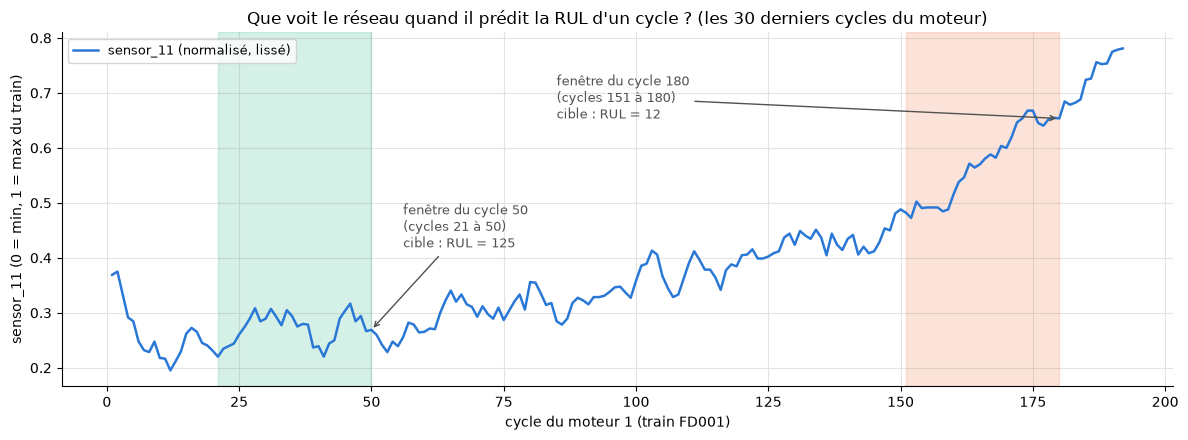

In [21]:
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(moteur_1["time_cycles"], moteur_1["sensor_11"], color=COULEUR_1, linewidth=1.8, label="sensor_11 (normalisé, lissé)")

# deux fenetres d'exemple : (cycle present, couleur, position du texte par rapport au point)
for cycle_present, couleur, decalage_texte in [(50, COULEUR_3, (6, 0.15)), (180, COULEUR_2, (-95, 0.0))]:
    rul_vraie = int(moteur_1["time_cycles"].max() - cycle_present)  # RUL brute a ce cycle
    rul_cible = min(rul_vraie, PLAFOND_RUL)  # cible plafonnee (Phase 2)
    ax.axvspan(cycle_present - LONGUEUR_FENETRE + 1, cycle_present, color=couleur, alpha=0.18)
    valeur = float(moteur_1.loc[moteur_1["time_cycles"] == cycle_present, "sensor_11"].iloc[0])
    position_texte = (cycle_present + decalage_texte[0], valeur + decalage_texte[1])
    ax.annotate(f"fenêtre du cycle {cycle_present}\n(cycles {cycle_present - LONGUEUR_FENETRE + 1} à {cycle_present})\n"
                f"cible : RUL = {rul_cible}", xy=(cycle_present, valeur), xytext=position_texte,
                fontsize=9, color=COULEUR_TEXTE, arrowprops={"arrowstyle": "->", "color": COULEUR_TEXTE})

ax.set_xlabel("cycle du moteur 1 (train FD001)")
ax.set_ylabel("sensor_11 (0 = min, 1 = max du train)")
ax.set_title("Que voit le réseau quand il prédit la RUL d'un cycle ? (les 30 derniers cycles du moteur)")
ax.legend(loc="upper left", fontsize=9)
plt.tight_layout()
plt.show()

#### B.2 Notion 2 — le remplissage en début de vie

**Problème.** Au cycle 3, le moteur n'a que 3 cycles observés : impossible de remplir une fenêtre de 30.

**Choix.** On complète le **début** de la fenêtre en **répétant le premier cycle** du moteur : la fenêtre du
cycle 3 est [cycle 1, cycle 1, …, cycle 1, cycle 2, cycle 3]. Pourquoi pas des zéros ? Pour un capteur
normalisé, 0 est une vraie valeur (le minimum du train) : le réseau croirait voir un moteur dans un état
extrême. Répéter le premier cycle dit seulement « rien n'a changé avant », ce qui est le plus neutre pour un
moteur qui commence sa vie. On n'emprunte **jamais** de cycles à un autre moteur.

Ce remplissage ne touche que les 29 premiers cycles de chaque moteur. Sur le test FD001, le dernier cycle (celui
qui est noté) a toujours au moins 31 cycles derrière lui : pas de remplissage à cet endroit (section B.5).

In [22]:
position_cycle_3 = int(np.flatnonzero(cycles_presents == 3)[0])
fenetre_3 = fenetres_cycles[position_cycle_3, :, 0]
print("Fenetre du cycle 3 :", fenetre_3.astype(int))

nb_cycle_1 = int(np.sum(fenetre_3 == 1))  # positions qui contiennent le cycle 1
print(f"{nb_cycle_1} positions contiennent le cycle 1 : {nb_cycle_1 - 1} de remplissage + le vrai cycle 1 ; "
      f"puis les cycles 2 et 3.")
assert list(fenetre_3[-3:].astype(int)) == [1, 2, 3]

Fenetre du cycle 3 : [1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 2 3]
28 positions contiennent le cycle 1 : 27 de remplissage + le vrai cycle 1 ; puis les cycles 2 et 3.


#### B.3 Contrôle sur tout le train : jamais un autre moteur, jamais le futur

Même astuce sur les 20 631 lignes du train, avec deux entrées « étiquettes » : `unit_number` et `time_cycles`.
Pour chaque fenêtre, on vérifie que **toutes** ses positions viennent du moteur de la ligne, et d'un cycle
inférieur ou égal au cycle de la ligne.

In [23]:
fenetres_controle, _, numeros_lignes, cycles_lignes = construire_fenetres(train, ["unit_number", "time_cycles"],
                                                                         longueur=LONGUEUR_FENETRE)
moteurs_vus = fenetres_controle[:, :, 0]  # (20631, 30) : le moteur de chaque position de chaque fenetre
cycles_vus = fenetres_controle[:, :, 1]   # (20631, 30) : le cycle de chaque position

meme_moteur = moteurs_vus == numeros_lignes[:, np.newaxis]  # Vrai si la position vient du moteur de la ligne
pas_de_futur = cycles_vus <= cycles_lignes[:, np.newaxis]   # Vrai si la position est un cycle <= cycle present
dernier_pas_present = cycles_vus[:, -1] == cycles_lignes    # la derniere position est le cycle present

print(f"Positions venant d'un autre moteur : {int(np.sum(~meme_moteur))} sur {meme_moteur.size}")
print(f"Positions venant du futur          : {int(np.sum(~pas_de_futur))} sur {pas_de_futur.size}")
print(f"Fenetres dont le dernier pas n'est pas le cycle present : {int(np.sum(~dernier_pas_present))}")
assert meme_moteur.all() and pas_de_futur.all() and dernier_pas_present.all()

Positions venant d'un autre moteur : 0 sur 618930
Positions venant du futur          : 0 sur 618930
Fenetres dont le dernier pas n'est pas le cycle present : 0


#### B.4 Notion 3 — le tenseur 3D

**Définition.** Un tableau à 3 dimensions. Le tableau des arbres a 2 dimensions (lignes × features). Celui
des réseaux en a 3 : **(nombre de fenêtres, 30 cycles, nombre d'entrées)**. Image : une pile de 20 631 petites
feuilles de calcul, chacune de 30 lignes (les cycles) et 15 colonnes (les capteurs).

On vérifie que la dernière « ligne » de chaque feuille est bien la ligne correspondante du train, et que les
moteurs des fenêtres sont, dans l'ordre, ceux des lignes (alignement avec les arbres).

In [24]:
fenetres_capteurs, y_fenetres, groupes_fenetres, _ = construire_fenetres(train, capteurs, longueur=LONGUEUR_FENETRE,
                                                                        colonne_cible="RUL_cappee")
print(f"Tenseur 3D : {fenetres_capteurs.shape} = (fenetres, cycles, capteurs), type {fenetres_capteurs.dtype}, "
      f"{fenetres_capteurs.nbytes / 1e6:.1f} Mo")

valeurs_lignes = train[capteurs].to_numpy(dtype=np.float32)
assert np.array_equal(fenetres_capteurs[:, -1, :], valeurs_lignes)  # dernier pas = la ligne elle-meme
assert np.array_equal(groupes_fenetres, groups.to_numpy())          # meme moteur, dans le meme ordre
assert np.array_equal(y_fenetres, y.to_numpy(dtype=np.float32))     # meme cible
print("Alignement ligne a ligne avec le tableau des arbres : verifie.")

Tenseur 3D : (20631, 30, 15) = (fenetres, cycles, capteurs), type float32, 37.1 Mo
Alignement ligne a ligne avec le tableau des arbres : verifie.


#### B.5 Pourquoi des fenêtres de 30 cycles ?

Un choix de données, pas de littérature : on veut que la fenêtre du **dernier cycle observé** de chaque moteur
test (le seul qui est noté) soit remplie de vraies mesures. Plus long, des moteurs test courts seraient
complétés par remplissage au moment même où on les note ; plus court, le réseau verrait moins de tendance.

In [25]:
lignes = []
for sous_jeu in ["FD001", "FD002", "FD003", "FD004"]:  # longueur des trajectoires test de chaque sous-jeu
    brut_test = charger_sous_jeu(sous_jeu, "test")
    longueurs = brut_test.groupby("unit_number").size()  # nombre de cycles observes par moteur test
    ligne = {}
    ligne["sous_jeu"] = sous_jeu
    ligne["nb_moteurs_test"] = int(len(longueurs))
    ligne["cycles_observes_min"] = int(longueurs.min())
    ligne["cycles_observes_mediane"] = float(longueurs.median())
    ligne["moteurs_test_de_moins_de_30_cycles"] = int(np.sum(longueurs < LONGUEUR_FENETRE))
    lignes.append(ligne)
pd.DataFrame(lignes).set_index("sous_jeu")

,nb_moteurs_test,cycles_observes_min,cycles_observes_mediane,moteurs_test_de_moins_de_30_cycles
sous_jeu,,,,
FD001,100,31,133.5,0
FD002,259,21,132.0,6
FD003,100,38,148.0,0
FD004,248,19,153.5,11


Lecture : sur FD001, le plus court moteur test a 31 cycles — une fenêtre de 30 est toujours pleine au cycle noté.
Sur FD002 et FD004, quelques moteurs test sont plus courts (le minimum est de 21 et 19 cycles) : leur fenêtre
est complétée par remplissage (B.2). On garde 30 partout pour ne pas multiplier les réglages ; c'est une
limite connue pour ces quelques moteurs.

#### B.6 à B.9 — Neurone, perte et gradient, époque et lot (résumé, sans code de démonstration)

- **Un neurone** fait une **somme pondérée** de ses entrées, ajoute un **biais**, puis applique une fonction simple, par exemple **ReLU** : max(0, x). Les **poids** et le biais sont les nombres que l'apprentissage ajuste. Un **réseau** empile des **couches** de neurones : les sorties d'une couche sont les entrées de la suivante. Exemple : avec trois entrées du moteur 1 au cycle 150 (`sensor_11`, `sensor_4`, `time_cycles` / 100) et des poids choisis à la main, la sortie du neurone est la somme « poids × entrée » plus le biais, ramenée à 0 si elle est négative.
- **La perte** mesure à quel point les prédictions sont fausses : on utilise l'**erreur quadratique moyenne** (MSE), la moyenne de (prédiction − vérité)², perte native de XGBoost aussi. **Le gradient** dit, pour chaque poids, dans quel sens le bouger pour que la perte baisse, et de combien. L'apprentissage répète : prédire → calculer la perte → calculer le gradient → bouger chaque poids d'un petit pas. Exemple minimal : un « réseau » à un seul poids *w* qui prédit toujours *w*, pour une vraie RUL de 100 ; perte (*w* − 100)², gradient 2 (*w* − 100) ; en partant de *w* = 80 avec un pas de 0,1, *w* passe à 84, 87,2, 89,8… et se rapproche de 100. Un vrai réseau fait la même chose avec tous ses poids à la fois ; PyTorch calcule les gradients automatiquement (`perte.backward()`). **Adam** est la méthode utilisée pour faire ces pas : une descente de gradient qui adapte la taille du pas de chaque poids à l'historique de ses gradients (pas de base 0,001 au 03b ; choisi par Optuna au 04h).
- **Époque et lot** : on ne calcule pas le gradient sur les 20 000 fenêtres à la fois (trop lent) ni sur une seule (trop bruité) : on les découpe en **lots** de 256 fenêtres tirées au hasard (128 au 04h). Chaque lot donne **une** mise à jour des poids ; une **époque** est un passage complet sur toutes les fenêtres d'apprentissage, dans un nouvel ordre aléatoire. Exemple, pli 1 de la validation croisée : 80 moteurs d'entraînement = 64 moteurs d'apprentissage + 16 moteurs d'arrêt précoce (B.14) ; les 64 moteurs donnent 13 169 fenêtres, soit 52 lots de 256, donc 52 mises à jour des poids par époque.

#### B.8 Notion 6 — la normalisation de la cible

Les capteurs sont entre 0 et 1 (min-max, Phase 1), mais la RUL va de 0 à 125. Un réseau apprend mieux quand
entrées et sortie ont des ordres de grandeur proches : des sorties de l'ordre de 100 demanderaient des poids
très grands, et les premiers gradients seraient énormes. On **divise donc la cible par 125** pendant
l'apprentissage (elle va de 0 à 1), et on **remultiplie par 125** les prédictions. Une prédiction négative est
ramenée à 0 (une RUL négative n'a pas de sens physique). Tout cela est caché dans `src/deep_learning.py` : on
donne et on récupère des RUL en cycles.

In [26]:
cible = y.to_numpy(dtype=float)
cible_echelle = cible / ECHELLE_CIBLE  # ce que le reseau apprend a sortir
print(f"RUL plafonnee : de {cible.min():.0f} a {cible.max():.0f} cycles -> cible du reseau : de {cible_echelle.min():.2f} "
      f"a {cible_echelle.max():.2f}")
print(f"Exemple : moteur 1, cycle 150, RUL 42 -> le reseau doit sortir 42 / 125 = {42 / ECHELLE_CIBLE:.3f}")

RUL plafonnee : de 0 a 125 cycles -> cible du reseau : de 0.00 a 1.00
Exemple : moteur 1, cycle 150, RUL 42 -> le reseau doit sortir 42 / 125 = 0.336


#### B.10 Notion 8 — le LSTM

**Idée.** Un LSTM (*Long Short-Term Memory*) lit la fenêtre **cycle par cycle**, du plus ancien au plus récent,
comme on lirait une phrase mot par mot. Il garde une **mémoire** de 64 nombres, mise à jour à chaque cycle à
partir du cycle lu et de la mémoire précédente. Des **portes** (petites couches de neurones apprises) décident à
chaque pas ce qu'il faut oublier, ce qu'il faut ajouter, et ce qu'il faut transmettre. Exemple de ce qu'il peut
apprendre : « si `sensor_11` augmente depuis 20 cycles, retenir que la dégradation a commencé ».

**Notre architecture** (simple et standard, fixée à l'avance) :
1. deux couches LSTM de 64 unités empilées (la 2e lit la suite des mémoires de la 1re) ;
2. on garde la sortie du **dernier** cycle (le cycle présent, qui a « vu » toute la fenêtre) ;
3. une couche linéaire 64 → 1 donne la RUL (divisée par 125).

Environ 54 000 poids, pour 20 631 fenêtres : assez pour apprendre des motifs, et le dropout (B.12) et l'arrêt
précoce (B.13) limitent le risque d'apprendre le train par cœur.

In [27]:
modele_lstm_demo = creer_modele("lstm", n_entrees=len(capteurs), graine=42)  # reseau neuf (poids au hasard)
print(modele_lstm_demo)
print(f"Nombre de poids : {compter_parametres(modele_lstm_demo)}")

predictions_demo = predire(modele_lstm_demo, fenetres_capteurs[:4])  # 4 fenetres -> 4 RUL
print("Sorties d'un reseau NON entraine pour 4 fenetres (sans signification) :", np.round(predictions_demo, 1))

ModeleLSTM(
  (lstm): LSTM(15, 64, num_layers=2, batch_first=True, dropout=0.2)
  (dropout): Dropout(p=0.2, inplace=False)
  (sortie): Linear(in_features=64, out_features=1, bias=True)
)
Nombre de poids : 54081
Sorties d'un reseau NON entraine pour 4 fenetres (sans signification) : [9.  8.9 8.9 8.9]


#### B.11 Notion 9 — la convolution 1D

**Idée.** Un **filtre** est une petite suite de poids (par exemple 3 nombres) qu'on fait **glisser** le long des
cycles : à chaque position, on multiplie les 3 cycles par les 3 poids et on additionne. Le filtre répond fort
quand le signal ressemble au motif qu'il code. Un réseau convolutif **apprend** ses filtres.

**Exemple concret, filtre écrit à la main** sur 9 cycles : poids −4, −3, …, 0, …, +3, +4, divisés par 60. Ce
filtre calcule la **pente** de la droite qui passe au mieux par les 9 cycles (« de combien le capteur monte par
cycle »). Appliqué au `sensor_11` du moteur 1, il reste proche de 0 en début de vie et devient positif en fin de
vie, quand le capteur monte. Les filtres du CNN sont plus courts (5 et 3 cycles), portent sur les 15 capteurs à
la fois, et leurs poids sont appris au lieu d'être écrits à la main.

Poids du filtre : [-0.067 -0.05  -0.033 -0.017  0.     0.017  0.033  0.05   0.067]
Sortie moyenne du filtre sur les 50 premiers cycles : -0.0009
Sortie moyenne du filtre sur les 30 derniers cycles : +0.0085


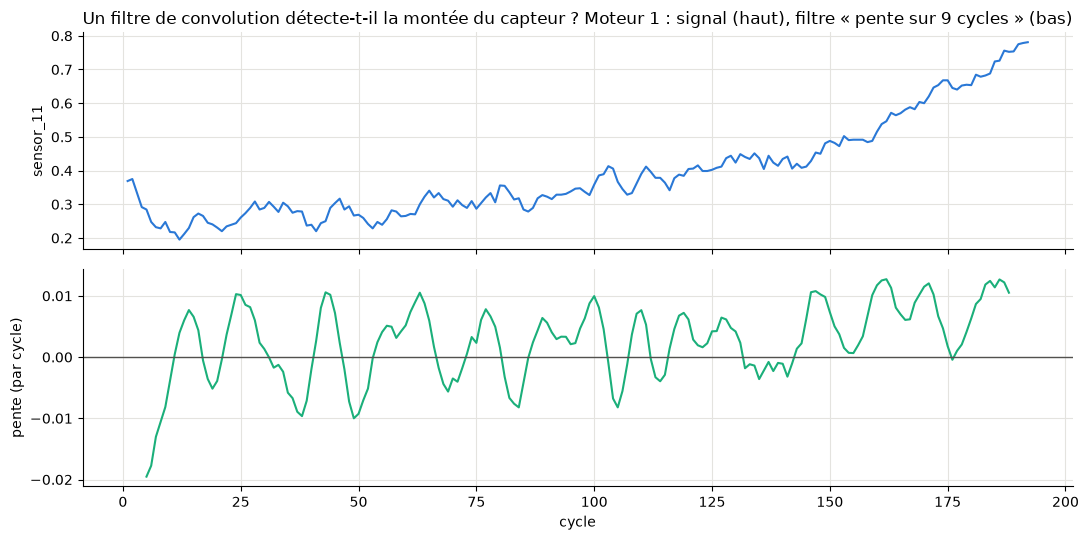

In [28]:
signal = moteur_1["sensor_11"].to_numpy()  # 192 valeurs, une par cycle
filtre = (np.arange(9) - 4.0) / 60.0  # poids -4/60 ... +4/60 : pente au sens des moindres carres sur 9 cycles
largeur = len(filtre)
print("Poids du filtre :", np.round(filtre, 3))

sortie_filtre = np.zeros(len(signal) - largeur + 1)  # une valeur par position du filtre
for debut in range(len(sortie_filtre)):  # on fait glisser le filtre, une position a la fois
    somme = 0.0
    for j in range(largeur):  # produit terme a terme, puis somme
        somme = somme + filtre[j] * signal[debut + j]
    sortie_filtre[debut] = somme

print(f"Sortie moyenne du filtre sur les 50 premiers cycles : {sortie_filtre[:50].mean():+.4f}")
print(f"Sortie moyenne du filtre sur les 30 derniers cycles : {sortie_filtre[-30:].mean():+.4f}")

fig, axes = plt.subplots(2, 1, figsize=(11, 5.5), sharex=True)
axes[0].plot(moteur_1["time_cycles"], signal, color=COULEUR_1)
axes[0].set_ylabel("sensor_11")
axes[0].set_title("Un filtre de convolution détecte-t-il la montée du capteur ? Moteur 1 : signal (haut), filtre « pente sur 9 cycles » (bas)")
cycles_centres = moteur_1["time_cycles"].to_numpy()[4:-4]  # chaque sortie est placee au cycle du milieu des 9
axes[1].plot(cycles_centres, sortie_filtre, color=COULEUR_3)
axes[1].axhline(0, color=COULEUR_TEXTE, linewidth=1)
axes[1].set_ylabel("pente (par cycle)")
axes[1].set_xlabel("cycle")
plt.tight_layout()
plt.show()

#### B.12 Notion 10 — du filtre au CNN 1D (BatchNorm, ReLU, pooling global)

Un **CNN 1D** applique en parallèle **beaucoup** de filtres appris, chacun sur les 15 capteurs à la fois (un filtre
de largeur 5 a 5 × 15 poids). Trois ingrédients de plus :

- **ReLU** (B.6) après chaque convolution : sans elle, empiler des convolutions reviendrait à une seule ;
- **BatchNorm** : remet la sortie de chaque filtre à une échelle stable (moyenne ≈ 0, écart-type ≈ 1 sur le
  lot), ce qui rend l'apprentissage plus rapide et moins sensible au réglage du pas ;
- **pooling global moyen** : après les convolutions, chaque filtre a une réponse par position de la fenêtre ;
  on en fait la **moyenne** sur les 30 positions → un nombre par filtre (« ce motif est-il présent dans la
  fenêtre ? »).

**Notre architecture** : 3 blocs « convolution → BatchNorm → ReLU » (32, 64 puis 64 filtres, de largeur 5, 5
et 3 cycles ; après les 3 blocs, chaque position « voit » 11 cycles), pooling global moyen, dropout, couche
linéaire 64 → 1. Environ 26 000 poids. Différence avec le LSTM : le CNN regarde des morceaux de quelques cycles
partout dans la fenêtre en même temps ; le LSTM lit la fenêtre dans l'ordre et résume tout dans sa mémoire.

In [29]:
modele_cnn_demo = creer_modele("cnn1d", n_entrees=len(capteurs), graine=42)
print(modele_cnn_demo)
print(f"Nombre de poids : {compter_parametres(modele_cnn_demo)}")
print("Sorties pour 4 fenetres (reseau non entraine) :", np.round(predire(modele_cnn_demo, fenetres_capteurs[:4]), 1))

ModeleCNN1D(
  (convolutions): Sequential(
    (0): Conv1d(15, 32, kernel_size=(5,), stride=(1,), padding=(2,))
    (1): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Conv1d(32, 64, kernel_size=(5,), stride=(1,), padding=(2,))
    (4): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (5): ReLU()
    (6): Conv1d(64, 64, kernel_size=(3,), stride=(1,), padding=(1,))
    (7): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (8): ReLU()
  )
  (dropout): Dropout(p=0.2, inplace=False)
  (sortie): Linear(in_features=64, out_features=1, bias=True)
)
Nombre de poids : 25473
Sorties pour 4 fenetres (reseau non entraine) : [12.6 12.6 12.6 12.6]


#### B.13 Notion 11 — le dropout (résumé, sans code de démonstration)

Pendant l'apprentissage, on « éteint » au hasard une partie des neurones (20 % au 03b) à chaque lot : leur sortie est mise à 0, et les autres sont multipliées par 1 / (1 − 0,2) = 1,25 pour garder la même moyenne. Le réseau ne peut donc pas compter sur un neurone en particulier, ce qui limite l'apprentissage par cœur. En **prédiction**, le dropout est coupé : tous les neurones travaillent. Exemple : sur un vecteur de 10 « 1 », en apprentissage environ 2 valeurs deviennent 0 et les autres 1,25 ; en prédiction, les 10 restent à 1.

#### B.14 Notion 12 — le surapprentissage et l'arrêt précoce (*early stopping*)

**Le risque.** Si on entraîne trop longtemps, le réseau finit par apprendre les **particularités des moteurs
d'entraînement** (leur bruit) plutôt que la dégradation en général : la perte d'entraînement continue de baisser,
mais l'erreur sur des moteurs **nouveaux** remonte. C'est le **surapprentissage**.

**L'arrêt précoce.** On met de côté quelques moteurs d'entraînement (20 %) qui ne servent **pas** à ajuster les
poids. Après chaque époque, on mesure l'erreur sur eux. On garde les poids de la **meilleure époque**, et on
arrête si l'erreur ne s'améliore plus pendant 10 époques (la **patience** ; 80 époques au plus).

Point crucial dans la validation croisée : ces moteurs d'arrêt précoce sont pris parmi les moteurs
d'**entraînement** du pli, **jamais** parmi ses moteurs de validation. Sinon, les moteurs qu'on prétend
« jamais vus » auraient choisi le moment de l'arrêt, et le score serait optimiste.

### 4.5 Faut-il donner `time_cycles` aux réseaux ?

En Phase 3, `time_cycles` (l'âge du moteur) a nettement amélioré XGBoost (RMSE CV 18,64 → 16,86, test
d'ablation). Pour un réseau, la question se repose : il voit 30 cycles, mais pas depuis combien de temps le
moteur vole. On ajoute éventuellement une 16e entrée, `time_cycles` / 100 (constante fixe, rien n'est appris
sur les données, donc aucune fuite ; valeurs de 0 à 3,6 sur FD001).

**Décision prise sur une seule séparation de validation du train, jamais sur le test**, avec une règle écrite
avant l'expérience (dans le script, `TEXTE_REGLE_ENTREES`) :

In [30]:
choix_entrees = pd.read_csv(os.path.join(DOSSIER_03B, "03b_choix_entrees_fd001.csv"))
with open(os.path.join(DOSSIER_03B, "03b_choix_entrees_fd001.json"), encoding="utf-8") as fichier:
    decision_entrees = json.load(fichier)
print(decision_entrees["regle"])
print()

resume_choix = choix_entrees.groupby(["type_modele", "avec_time_cycles"])["rmse_decision"].agg(["mean", "std", "min", "max"])
resume_choix.columns = ["rmse_moyen_3_graines", "ecart_type", "min", "max"]
print(resume_choix.round(2).to_string())
print()
print(f"Moyenne sur les deux reseaux : avec time_cycles {decision_entrees['rmse_moyen_avec_time_cycles']:.2f}, "
      f"sans {decision_entrees['rmse_moyen_sans_time_cycles']:.2f} -> time_cycles garde : "
      f"{decision_entrees['garder_time_cycles']}")

AVEC_TIME_CYCLES = bool(decision_entrees["garder_time_cycles"])
colonnes_entree = lister_colonnes_entree(capteurs, AVEC_TIME_CYCLES)  # entrees de tous les reseaux qui suivent
print(f"Entrees retenues ({len(colonnes_entree)}) : {colonnes_entree}")

Separation unique des 100 moteurs du train FD001 (graine 42) : 20 moteurs de decision, 80 moteurs d'entrainement eux-memes separes en 64 d'apprentissage et 16 d'arret precoce. Chaque reseau (LSTM, CNN 1D) est entraine avec et sans time_cycles, 3 graines chacun ; on mesure le RMSE sur les 20 moteurs de decision (tous leurs cycles). time_cycles est garde si la moyenne, sur les deux reseaux et les 3 graines, de ce RMSE est plus basse avec time_cycles que sans ; sinon on garde les capteurs seuls (variante la plus simple). Le jeu de test n'intervient pas. Decision prise une fois sur FD001 et appliquee a FD002-FD004.

                              rmse_moyen_3_graines  ecart_type    min    max
type_modele avec_time_cycles                                                
cnn1d       False                            16.39        0.72  15.56  16.85
            True                             13.88        0.66  13.14  14.41
lstm        False                            13.58        0.38  13.34  1

**`time_cycles` est gardé : les réseaux reçoivent 16 entrées** (15 capteurs + `time_cycles` / 100).

- RMSE sur les 20 moteurs de décision, moyenne de 3 graines : LSTM 12,09 avec contre 13,58 sans ; CNN 1D 13,88 avec
  contre 16,39 sans. Pour chaque réseau, le **moins bon** essai avec `time_cycles` (LSTM 12,50 ; CNN 14,41) fait
  mieux que le **meilleur** essai sans (13,34 ; 15,56) : l'écart n'est pas un effet de graine.
- Même conclusion qu'en Phase 3 pour XGBoost : l'âge du moteur aide, même quand le modèle voit 30 cycles d'historique.
- Limite : une seule séparation et 20 moteurs de décision. C'est un choix fait proprement sans le test, pas une preuve
  générale ; il est appliqué tel quel à FD002–FD004.

### Décision de la section 4

**Décisions** (03b) :

1. **Fenêtre glissante par moteur**, une fenêtre par ligne dans l'ordre des lignes, jamais un cycle futur ni un autre moteur (contrôlé sur les 20 631 lignes, et par `tests/test_anti_triche.py`) ; début de vie complété en **répétant le premier cycle** ; cible divisée par 125 pendant l'apprentissage.
2. **Longueur 30 cycles** au 03b : le plus court moteur test FD001 a 31 cycles (B.5). **Mise à jour 04h** : Optuna retient une fenêtre de **20 cycles** pour FD001 et FD002 (section 10).
3. **`time_cycles` / 100 en entrée** : RMSE de décision 12,98 avec contre 14,99 sans (moyenne des deux réseaux, 3 graines ; sortie de la cellule 4.5) ; le moins bon essai avec fait mieux que le meilleur sans.

## 5. Les réseaux valent-ils leur coût ? Validation croisée, mêmes plis que les arbres

*Repris du notebook `03b_deep_learning_lstm_cnn` (sections A.5 et D.1 à D.4, D.6).* Cette section n'a pas de ligne propre dans le tableau 5.2 du plan ; elle est gardée parce que 8.2 garde la section D du 03b (« validation croisée et tests appariés arbres contre réseaux »), et que c'est elle qui justifie de garder des réseaux malgré leur coût.

**Ce qui a fondé la décision (anciens modèles)** : réseaux du 03b (réglages fixés à l'avance, avec `ecartinit_20`) contre XGBoost Phase 3 (46 variables, sans `ecartinit_20`). La comparaison des versions retenues entre elles est dans `resultats/FD001`, section 6.

### 5.1 La référence XGBoost

Les réseaux seront comparés à **XGBoost Phase 3** (réglages de la Phase 3, `CONFIG_PHASE3` de
`src/config_modele.py`). On le réentraîne ici (quelques secondes) pour disposer de ses prédictions hors-pli
(validation croisée, mêmes plis) et de ses prédictions sur le test.

**Pourquoi maintenant, avant tout réseau ?** Une contrainte technique, constatée en préparant ce notebook :
xgboost / lightgbm, scikit-learn et PyTorch embarquent chacun leur propre copie de la bibliothèque de calcul
parallèle OpenMP, et ces copies cohabitent mal dans un même processus Python :

- si PyTorch est **chargé** avant xgboost, XGBoost plante ensuite dès qu'il calcule sur plusieurs cœurs (erreur de
  segmentation, reproduite 3 fois sur 3) ; chargé après, il fonctionne. D'où l'ordre des imports de la cellule A.2 ;
- si XGBoost a déjà calculé, PyTorch sur **plusieurs** cœurs peut se bloquer indéfiniment (constaté dans la suite
  de tests) ; sur 1 cœur, non. D'où le réglage à 1 cœur.

Par prudence, on fait aussi tous les calculs XGBoost avant d'utiliser PyTorch. Les chiffres n'en dépendent pas :
seul l'ordre des opérations change (contrôles de reproduction en D.2 et F.2).

In [31]:
configs_xgb = {}  # nom affiche -> configuration (src/config_modele.py)
configs_xgb["XGBoost Phase 3"] = config_sur_n_coeurs(CONFIG_PHASE3)  # meme modele, 4 coeurs au plus (section 1)

resultats_xgb = {}  # validation croisee (memes plis)
resultats_test_xgb = {}  # test officiel, modele entraine sur les 100 moteurs
temps_prediction_xgb_ms = {}  # prediction de toutes les trajectoires test, ramenee a un moteur
X_test_tous_cycles = contexte_test["test"][contexte_train["feature_cols"]]  # toutes les lignes du test
for nom_modele in configs_xgb:
    fabrique = construire_fabrique_depuis_config(configs_xgb[nom_modele])
    resultats_xgb[nom_modele] = evaluer_en_validation_croisee(fabrique, X, y, groups, plis,
                                                              seuil_surestimation=SEUIL_SURESTIMATION,
                                                              seuil_alerte=SEUIL_ALERTE)
    modele_final = fabrique()
    modele_final.fit(X, y)  # 100 moteurs d'entrainement
    resultats_test_xgb[nom_modele] = evaluer_sur_test(modele_final, X_test_dernier, y_test_vraie, plafond=PLAFOND_RUL,
                                                      seuil_surestimation=SEUIL_SURESTIMATION, seuil_alerte=SEUIL_ALERTE)
    debut = time.perf_counter()
    modele_final.predict(X_test_tous_cycles)
    temps_prediction_xgb_ms[nom_modele] = 1000.0 * (time.perf_counter() - debut) / len(moteurs_test)
    print(f"{nom_modele} : RMSE CV moyen = {resultats_xgb[nom_modele]['rmse_moyen']:.3f}, "
          f"RMSE test = {resultats_test_xgb[nom_modele]['rmse']:.2f}")

XGBoost Phase 3 : RMSE CV moyen = 16.867, RMSE test = 19.70


### 5.2 Protocole

Pour chacun des 5 plis (les plis de la Phase 4) et pour chaque réseau :

1. les 80 moteurs d'entraînement du pli sont séparés (graine 42) en **64 moteurs d'apprentissage** et
   **16 moteurs d'arrêt précoce** ; les 20 moteurs de validation du pli restent intouchés ;
2. un réseau **neuf** (graine 42) apprend sur les 64 moteurs, l'arrêt précoce surveille les 16 ;
3. il prédit les 20 moteurs de validation, à **chaque cycle** : prédictions hors-pli (OOF), une par ligne.

Les 10 apprentissages (2 réseaux × 5 plis) tournent en parallèle dans le script (1 cœur chacun, résultats
identiques à une exécution l'une après l'autre).

On relit les résultats et on vérifie leur cohérence : prédictions OOF alignées sur les lignes du train, et le
RMSE de chaque pli recalculé ici, à partir des plis de ce notebook, égal à celui du script (ce qui prouve que le
script a bien utilisé les mêmes plis).

In [32]:
cv_reseaux = pd.read_csv(os.path.join(DOSSIER_03B, "03b_cv_fd001.csv")).set_index("modele")
oof = pd.read_csv(os.path.join(DOSSIER_03B, "03b_oof_fd001.csv.gz"))

# alignement ligne a ligne avec le train de ce notebook
assert np.array_equal(oof["unit_number"].to_numpy(), train["unit_number"].to_numpy())
assert np.array_equal(oof["time_cycles"].to_numpy(), train["time_cycles"].to_numpy())
assert np.array_equal(oof["RUL_cappee"].to_numpy(dtype=float), y.to_numpy(dtype=float))

for nom_reseau in cv_reseaux.index:  # chaque reseau (et la variante asymetrique, section E)
    rmse_par_pli_script = json.loads(cv_reseaux.loc[nom_reseau, "rmse_par_pli"])
    for position in range(len(plis)):
        idx_val = plis[position][1]
        rmse_recalcule = rmse(y.iloc[idx_val], oof[f"oof_{nom_reseau}"].iloc[idx_val])
        # tolerance : les predictions OOF sont ecrites avec 4 decimales
        assert abs(rmse_recalcule - rmse_par_pli_script[position]) < 1e-3, (nom_reseau, position)
    print(f"{nom_reseau:18s} : RMSE par pli {np.round(rmse_par_pli_script, 2)} (recalcules ici : identiques), "
          f"meilleures epoques {cv_reseaux.loc[nom_reseau, 'meilleures_epoques']}")

lstm               : RMSE par pli [ 7.89 10.12  9.9   8.04  8.76] (recalcules ici : identiques), meilleures epoques [30, 12, 36, 55, 10]
cnn1d              : RMSE par pli [10.09 11.39 10.78  9.16  8.82] (recalcules ici : identiques), meilleures epoques [11, 23, 17, 22, 7]
lstm_alpha2.26     : RMSE par pli [ 8.7  10.23  9.69  8.73  9.96] (recalcules ici : identiques), meilleures epoques [11, 12, 36, 47, 17]


### 5.3 Contrôle de la référence XGBoost

XGBoost Phase 3 a été réentraîné en A.5 sur les mêmes plis. Contrôle : on doit retrouver exactement les chiffres
de validation croisée du notebook 05 (RMSE CV 16,87, score NASA CV 29 782,6).

In [33]:
# memes valeurs que le notebook 05, section B (arrondies comme dans son tableau)
assert round(resultats_xgb["XGBoost Phase 3"]["rmse_moyen"], 2) == 16.87
assert round(resultats_xgb["XGBoost Phase 3"]["nasa_moyen"], 1) == 29782.6
print("Chiffres de validation croisee du notebook 05 retrouves a l'identique :")
for nom_modele in resultats_xgb:
    print(f"  {nom_modele} : RMSE CV moyen {resultats_xgb[nom_modele]['rmse_moyen']:.3f}")

Chiffres de validation croisee du notebook 05 retrouves a l'identique :
  XGBoost Phase 3 : RMSE CV moyen 16.867


### 5.4 Tableau comparatif (validation croisée, mêmes 5 plis)

Mêmes colonnes que la Phase 4. Le temps d'entraînement des réseaux est la somme des 5 plis, chacun mesuré dans
son processus avec **1 cœur** (machine partagée avec d'autres calculs : ordre de grandeur, pas une mesure fine) ;
XGBoost est mesuré ici sur 4 cœurs (section 1). Prédiction : temps pour prédire toute la
trajectoire des moteurs de validation, ramené à un moteur (environ 206 cycles).

D'abord une petite fonction qui met une ligne de résultats au même format pour les arbres et pour les réseaux.

In [34]:
def ligne_cv(nom, rmse_moyen, rmse_ecart_type, mae_moyen, nasa_moyen, surestimes, alertes_manquees, fausses_alertes,
             biais, temps_entrainement, prediction_ms):
    '''
    Construit une ligne du tableau de validation croisee (memes colonnes pour arbres et reseaux).

    Parameters
    ----------
    nom : str
        Nom du modele.
    rmse_moyen, rmse_ecart_type, mae_moyen, nasa_moyen : float
        Moyennes (et ecart-type du RMSE) sur les 5 plis.
    surestimes, alertes_manquees, fausses_alertes : int
        Comptes sur les 20 631 predictions hors-pli.
    biais : float
        Moyenne de (prediction - verite) hors-pli.
    temps_entrainement : float
        Entrainement cumule des 5 plis (s).
    prediction_ms : float
        Prediction d'une trajectoire de moteur (ms).

    Returns
    -------
    dict
        La ligne.
    '''
    ligne = {}
    ligne["modele"] = nom
    ligne["rmse_cv_moyen"] = rmse_moyen
    ligne["rmse_cv_ecart_type"] = rmse_ecart_type
    ligne["mae_cv_moyen"] = mae_moyen
    ligne["nasa_cv_moyen"] = nasa_moyen
    ligne["surestimes_oof_20"] = surestimes
    ligne["alertes_manquees_oof"] = alertes_manquees
    ligne["fausses_alertes_oof"] = fausses_alertes
    ligne["biais_oof"] = biais
    ligne["temps_entrainement_5_plis_s"] = temps_entrainement
    ligne["prediction_ms_par_moteur"] = prediction_ms
    return ligne

Le tableau : les deux réseaux (lus dans `03b_cv_fd001.csv`) et XGBoost Phase 3 (calculé en A.5, contrôlé en D.2).

In [35]:
NOMS_AFFICHES = {"lstm": "LSTM", "cnn1d": "CNN 1D"}
lignes = []
for nom_reseau in ["lstm", "cnn1d"]:
    r = cv_reseaux.loc[nom_reseau]
    lignes.append(ligne_cv(NOMS_AFFICHES[nom_reseau], r["rmse_cv_moyen"], r["rmse_cv_ecart_type"], r["mae_cv_moyen"],
                           r["nasa_cv_moyen"], r["surestimes_oof"], r["alertes_manquees_oof"], r["fausses_alertes_oof"],
                           r["biais_oof"], r["temps_entrainement_5_plis_s"], r["prediction_ms_par_moteur"]))
for nom_modele in resultats_xgb:
    r = resultats_xgb[nom_modele]
    lignes.append(ligne_cv(nom_modele, r["rmse_moyen"], r["rmse_ecart_type"], r["mae_moyen"], r["nasa_moyen"],
                           r["surestimes_oof"], r["alertes_manquees_oof"], r["fausses_alertes_oof"], r["biais_oof"],
                           r["temps_entrainement_total"], 1000.0 * r["temps_prediction_total"] / NB_MOTEURS_TRAIN))
tableau_cv = pd.DataFrame(lignes).set_index("modele")
tableau_cv.round(2)

,rmse_cv_moyen,rmse_cv_ecart_type,mae_cv_moyen,nasa_cv_moyen,surestimes_oof_20,alertes_manquees_oof,fausses_alertes_oof,biais_oof,temps_entrainement_5_plis_s,prediction_ms_par_moteur
modele,,,,,,,,,,
LSTM,8.94,0.92,5.68,6122.79,799,154,126,0.38,335.72,10.72
CNN 1D,10.05,0.96,6.81,8172.68,831,253,108,0.11,674.45,61.59
XGBoost Phase 3,16.87,1.25,11.50,29782.56,2384,552,259,-0.16,2.22,0.14


**Un point d'équité à vérifier : le clip à 0.** Les prédictions des réseaux sont ramenées à 0 si elles sont
négatives ; les prédictions hors-pli des arbres ne le sont pas (protocole de la Phase 3). Le clip ne peut que
réduire l'erreur (la vérité est ≥ 0). On mesure son effet sur XGBoost : s'il est négligeable, la comparaison
du tableau est équitable.

In [36]:
for nom_modele in resultats_xgb:
    predictions_oof_xgb = resultats_xgb[nom_modele]["predictions_oof"]
    predictions_clippees = np.clip(predictions_oof_xgb, a_min=0.0, a_max=None)
    rmse_par_pli_clippe = []
    for idx_train, idx_val in plis:
        rmse_par_pli_clippe.append(rmse(y.iloc[idx_val], predictions_clippees[idx_val]))
    nb_negatives = int(np.sum(predictions_oof_xgb < 0))
    print(f"{nom_modele} : {nb_negatives} predictions OOF negatives ; RMSE CV moyen {resultats_xgb[nom_modele]['rmse_moyen']:.3f} "
          f"-> {np.mean(rmse_par_pli_clippe):.3f} avec clip a 0")

XGBoost Phase 3 : 25 predictions OOF negatives ; RMSE CV moyen 16.867 -> 16.867 avec clip a 0


### 5.5 Les écarts sont-ils significatifs ? Tests appariés par moteur

Comme en Phase 4 : pour chaque modèle, le **RMSE hors-pli de chacun des 100 moteurs**, puis comparaison moteur
par moteur (`comparer_apparie` : test t apparié et Wilcoxon signé). Trois comparaisons fixées à l'avance :
LSTM contre XGBoost Phase 3, CNN 1D contre XGBoost Phase 3, LSTM contre CNN 1D. Seuil de Bonferroni :
0,05 / 3 ≈ 0,017 pour les deux tests. Différence moyenne négative = le premier modèle a un RMSE par moteur plus
petit (il est meilleur).

In [37]:
rmse_par_moteur = {}  # nom -> RMSE hors-pli de chacun des 100 moteurs (tries par numero)
rmse_par_moteur["LSTM"] = erreurs_par_moteur(y, oof["oof_lstm"], groups)["rmse"].to_numpy()
rmse_par_moteur["CNN 1D"] = erreurs_par_moteur(y, oof["oof_cnn1d"], groups)["rmse"].to_numpy()
for nom_modele in resultats_xgb:
    rmse_par_moteur[nom_modele] = erreurs_par_moteur(y, resultats_xgb[nom_modele]["predictions_oof"], groups)["rmse"].to_numpy()

SEUIL_BONFERRONI_CV = 0.05 / 3
comparaisons_cv = [("LSTM", "XGBoost Phase 3"), ("CNN 1D", "XGBoost Phase 3"), ("LSTM", "CNN 1D")]
lignes = []
for nom_a, nom_b in comparaisons_cv:
    resultat = comparer_apparie(rmse_par_moteur[nom_a], rmse_par_moteur[nom_b])
    ligne = {}
    ligne["comparaison"] = f"{nom_a} vs {nom_b}"
    ligne["rmse_moyen_par_moteur_a"] = float(np.mean(rmse_par_moteur[nom_a]))
    ligne["rmse_moyen_par_moteur_b"] = float(np.mean(rmse_par_moteur[nom_b]))
    ligne["difference_moyenne"] = resultat["difference_moyenne"]
    ligne["moteurs_ou_a_est_meilleur"] = int(np.sum(rmse_par_moteur[nom_a] < rmse_par_moteur[nom_b]))
    ligne["p_valeur_t"] = resultat["p_valeur_t"]
    ligne["p_valeur_wilcoxon"] = resultat["p_valeur_wilcoxon"]
    ligne["significatif_bonferroni"] = bool(resultat["p_valeur_t"] < SEUIL_BONFERRONI_CV and resultat["p_valeur_wilcoxon"] < SEUIL_BONFERRONI_CV)
    lignes.append(ligne)
tableau_tests_cv = pd.DataFrame(lignes).set_index("comparaison")
tableau_tests_cv.round(4)

,rmse_moyen_par_moteur_a,rmse_moyen_par_moteur_b,difference_moyenne,moteurs_ou_a_est_meilleur,p_valeur_t,p_valeur_wilcoxon,significatif_bonferroni
comparaison,,,,,,,
LSTM vs XGBoost Phase 3,8.3354,15.5130,-7.1776,87,0.0000,0.0000,True
CNN 1D vs XGBoost Phase 3,9.3983,15.5130,-6.1147,77,0.0000,0.0000,True
LSTM vs CNN 1D,8.3354,9.3983,-1.0629,63,0.0017,0.0011,True


**Figure de synthèse (validation croisée)** : un critère par panneau. Panneau RMSE : barre = moyenne des 5 plis,
points = les 5 plis.

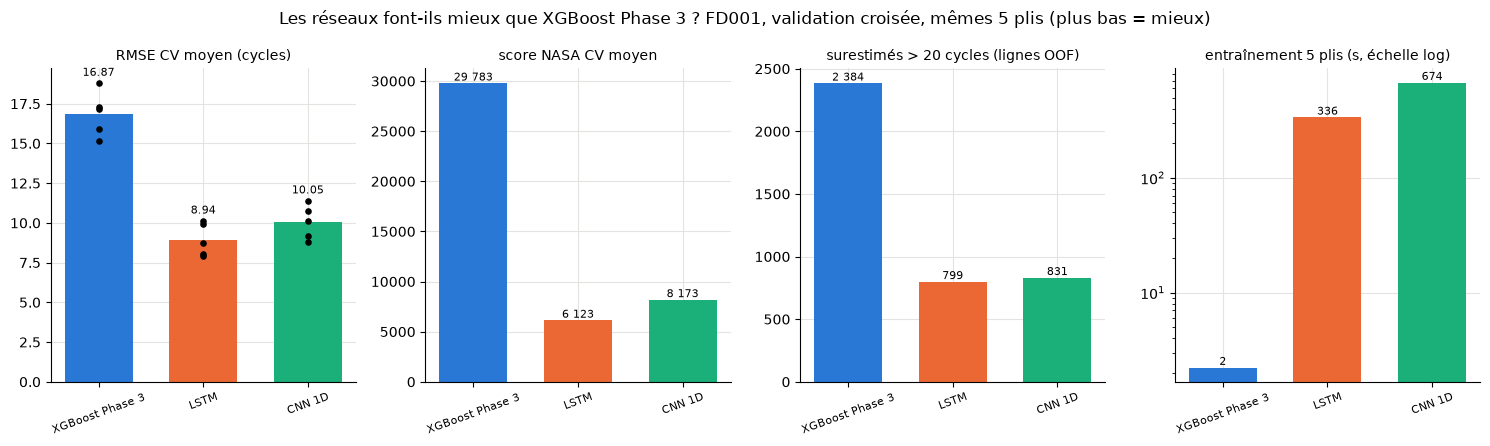

In [38]:
noms_figure = ["XGBoost Phase 3", "LSTM", "CNN 1D"]
couleurs_figure = [COULEUR_1, COULEUR_2, COULEUR_3]
rmse_plis_figure = {}
rmse_plis_figure["XGBoost Phase 3"] = resultats_xgb["XGBoost Phase 3"]["rmse_par_pli"]
rmse_plis_figure["LSTM"] = json.loads(cv_reseaux.loc["lstm", "rmse_par_pli"])
rmse_plis_figure["CNN 1D"] = json.loads(cv_reseaux.loc["cnn1d", "rmse_par_pli"])

fig, axes = plt.subplots(1, 4, figsize=(15, 4.5))
panneaux = [("rmse_cv_moyen", "RMSE CV moyen (cycles)"), ("nasa_cv_moyen", "score NASA CV moyen"),
            ("surestimes_oof_20", "surestimés > 20 cycles (lignes OOF)"), ("temps_entrainement_5_plis_s", "entraînement 5 plis (s, échelle log)")]
for ax, (colonne, titre) in zip(axes, panneaux):
    for position in range(len(noms_figure)):
        nom_modele = noms_figure[position]
        valeur = tableau_cv.loc[nom_modele, colonne]
        ax.bar(position, valeur, color=couleurs_figure[position], width=0.65)
        hauteur_texte = valeur  # le texte se place juste au-dessus de la barre...
        texte = f"{valeur:,.0f}".replace(",", " ")
        if colonne == "rmse_cv_moyen":
            ax.scatter(np.full(5, position), rmse_plis_figure[nom_modele], color="black", s=14, zorder=3)
            hauteur_texte = max(rmse_plis_figure[nom_modele]) + 0.3  # ... ou au-dessus du pli le plus haut
            texte = f"{valeur:.2f}"
        ax.text(position, hauteur_texte, texte, ha="center", va="bottom", fontsize=8)
    ax.set_xticks(np.arange(len(noms_figure)))
    ax.set_xticklabels(noms_figure, rotation=20, fontsize=8)
    ax.set_title(titre, fontsize=10)
    if colonne == "temps_entrainement_5_plis_s":
        ax.set_yscale("log")
fig.suptitle("Les réseaux font-ils mieux que XGBoost Phase 3 ? FD001, validation croisée, mêmes 5 plis (plus bas = mieux)")
plt.tight_layout()
plt.show()

### 5.6 Conclusion

- **Le LSTM fait nettement mieux que XGBoost Phase 3 en validation croisée.** RMSE CV 8,94 ± 0,92, contre 16,87 ± 1,25.
  Test apparié sur les 100 moteurs : RMSE par moteur 8,34 contre 15,51 en moyenne (−7,18 cycles), plus petit sur
  87 moteurs sur 100, p < 0,0001 (t et Wilcoxon) : significatif après correction de Bonferroni. **Une grande partie
  de cet écart vient de `ecartinit_20`**, que XGBoost Phase 3 n'a pas : avec cette variable, XGBoost descend à 9,36
  (notebook 05, F.3 ; section 7 de ce notebook).
- **Il est aussi plus prudent, sans avoir été réglé pour** : score NASA CV 6 123 (contre 29 783 pour XGBoost
  Phase 3) ; 799 lignes surestimées de plus de 20 cycles (contre 2 384) ; 154 alertes manquées (contre 552) ;
  126 fausses alertes (contre 259) ; biais +0,38 cycle.
- **Le CNN 1D fait aussi mieux que XGBoost Phase 3** (RMSE CV 10,05 ± 0,96 ; −6,11 cycles par moteur, plus petit sur
  77 moteurs sur 100, p < 0,0001), **mais moins bien que le LSTM** : −1,06 cycle par moteur en faveur du LSTM
  (p = 0,0017 / 0,0011, significatif au seuil de Bonferroni de 0,017). Ses meilleures époques vont de 7 à 23 selon
  le pli.
- **Le clip à 0 n'explique rien** : XGBoost Phase 3 n'a que 25 prédictions hors-pli négatives sur 20 631, et son
  RMSE CV ne bouge pas au millième près avec le clip (16,867).
- **Équité des données** : dans chaque pli, les réseaux apprennent sur 64 moteurs (16 sont réservés à l'arrêt
  précoce), XGBoost sur 80. L'avantage des réseaux ne vient donc pas de plus de données.
- **Coût** : environ 100 fois plus de temps d'entraînement que XGBoost Phase 3 (336 s pour les 5 plis du LSTM, 674 s
  pour le CNN, contre quelques secondes selon la charge de la machine ; 1 cœur pour le réseau, tous les cœurs pour
  XGBoost) ; prédiction de la trajectoire d'un moteur en 10,7 ms (LSTM) et 61,6 ms (CNN), contre environ 0,1 ms.
- **Pourquoi le CNN fait-il moins bien que le LSTM ? Hypothèses, non testées** : la moyenne globale sur les 30
  positions efface *où* un motif apparaît dans la fenêtre, alors que les derniers cycles comptent le plus (le LSTM
  sort l'état du dernier cycle). Les tester demanderait de modifier l'architecture après avoir vu ces résultats, à
  juger sur la validation croisée seulement.

### Décision de la section 5

**Décision : garder les deux familles, arbres et réseaux**, pour la suite (variables, hyperparamètres, test). **Chiffre** : en validation croisée sur les mêmes 5 plis, le LSTM du 03b fait 8,94 contre 16,87 pour XGBoost Phase 3, plus petit sur 87 moteurs sur 100, significatif au seuil de Bonferroni (tableau 5.5). **Limite, dite par le 03b lui-même** : une grande partie de l'écart vient de `ecartinit_20`, que XGBoost Phase 3 n'avait pas (section 7) ; **coût** : environ 100 fois plus de temps d'entraînement.

## 6. Les variables : ablation, une famille à la fois

*Repris du notebook `04e_feature_engineering` (sections 1 à 7 et 10).* Applique la **section 7** de [`docs/protocole_evaluation.md`](../docs/protocole_evaluation.md) au XGBoost de la Phase 3. Le test officiel du jeu retenu (section 8 du 04e : RMSE 19,70 → 13,10) est dans `evolution`, étape 4 ; la section 9 du 04e (variantes testées après lecture des résultats) est retirée, son résultat tient en une ligne à la fin de cette section.

**Ce qui a fondé la décision (ancien modèle)** : l'ablation est faite avec les réglages XGBoost de la Phase 3, pour que seule la liste de variables change. Les réglages ont été optimisés ensuite, sur le jeu retenu (section 9).

### 6.0 Point de départ, dit franchement

Les 46 features du notebook 03 sont : 15 capteurs lissés (moyenne mobile 5 cycles, Phase 1) + leur moyenne glissante sur 5 cycles + leur écart-type glissant sur 5 cycles + `time_cycles`.

- Aucun document du dépôt ne justifie le choix « moyenne + écart-type sur 5 cycles ». Le cahier des charges (Phase 3) demande moyenne, variance, asymétrie et kurtosis ; seules deux de ces statistiques avaient été reprises, **sans hypothèse écrite**.
- L'ablation de la Phase 3 (§5) a montré que ces colonnes n'apportent rien de mesurable (écarts de 0,2 de RMSE contre un bruit d'environ 1,3 entre plis), que tout le gain vient de `time_cycles`, et que **16 features (15 capteurs + `time_cycles`) font aussi bien que 46**.
- Une raison probable : la « moyenne glissante » est la moyenne sur 5 cycles d'un capteur **déjà** lissé sur 5 cycles (moyenne de moyennes, corrélation 0,987 mesurée en Phase 3). Elle décrit le même niveau, avec un peu de retard.

**Référence à battre : les 16 features** (`ref16`). Les 46 actuelles (`ref46`) sont aussi mesurées.

### Ce que cette section fait

Pour chaque famille de features : une hypothèse écrite **avant** le test → un test d'ablation sur les mêmes plis par moteur que le notebook 03 → une conclusion chiffrée, y compris quand la famille n'apporte rien. Puis sélection (règle écrite avant les résultats), importance des features (gain **et** permutation), et **un seul** passage sur le test officiel pour le jeu retenu.

### Contraintes respectées

- features **causales** (la ligne du cycle t n'utilise que les cycles ≤ t), **moteur par moteur** — vérifié par un test automatique en section 2 ;
- mêmes réglages XGBoost que le notebook 03 (`n_estimators=200, max_depth=5, learning_rate=0.05, random_state=42`) ;
- mêmes plis : `GroupKFold(n_splits=5, shuffle=True, random_state=42)` (graine 42). Pour mesurer le bruit, la validation est **répétée avec deux autres graines de plis** (43 et 44) ; la graine 42 reste la référence comparable au notebook 03 ;
- jamais le test officiel pour choisir quoi que ce soit.

### 6.1 Chargement et préparation (identique au notebook 03)

On repart de `src/preprocessing.py` sans le modifier. Deux versions du signal sont gardées :
- le signal **normalisé non lissé** (nécessaire pour la moyenne mobile exponentielle, qui est une alternative au lissage) ;
- le signal **lissé** par la moyenne mobile 5 cycles (Phase 1), base des 16 features de référence.

In [39]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.model_selection import GroupKFold
from sklearn.inspection import permutation_importance
from xgboost import XGBRegressor

from src.preprocessing import (
    load_fd001, get_sensor_columns, find_constant_sensors,
    normalize_minmax, lisser_capteurs, calculer_rul, plafonner_rul, DATA_DIR,
)

FENETRE = 5          # fenetre du lissage de la Phase 1
PLAFOND_RUL = 125    # plafond de la RUL, Phase 2
GRAINES_PLIS = [42, 43, 44]  # 42 = plis du notebook 03 ; 43 et 44 servent a mesurer le bruit du decoupage
# memes reglages XGBoost que le notebook 03, pour que seule la liste de features change
REGLAGES_XGB = dict(n_estimators=200, max_depth=5, learning_rate=0.05, random_state=42, n_jobs=NB_COEURS)  # 4 coeurs : memes predictions

In [40]:
train_brut = load_fd001("train")  # fichier d'entrainement FD001

sensor_cols = get_sensor_columns(train_brut.columns)  # les 21 capteurs bruts
capteurs_constants = find_constant_sensors(train_brut, sensor_cols)  # 6 capteurs constants (Phase 1)
train_brut = train_brut.drop(columns=capteurs_constants)  # on les retire
capteurs = get_sensor_columns(train_brut.columns)  # les 15 capteurs informatifs

# normalisation min-max (le scaler est garde pour le test) : ici le signal n'est PAS encore lisse
train_norm, scaler = normalize_minmax(train_brut, capteurs)
train_norm = calculer_rul(train_norm)  # RUL brute par cycle
train_norm = plafonner_rul(train_norm, plafond=PLAFOND_RUL)  # RUL plafonnee a 125

# les features par fenetre supposent des lignes triees par moteur puis par cycle (ordre du fichier)
ordre_attendu = train_norm.sort_values(["unit_number", "time_cycles"]).index
assert (ordre_attendu == train_norm.index).all(), "le tableau n'est pas trie par moteur puis par cycle"

y = train_norm["RUL_cappee"]      # cible (Phase 2)
groups = train_norm["unit_number"]  # sert uniquement a GroupKFold (quel moteur)
print(f"train : {train_norm.shape}, {groups.nunique()} moteurs, {len(capteurs)} capteurs")

train : (20631, 22), 100 moteurs, 15 capteurs


### 6.2 Fabrication des features candidates

Une seule fonction calcule **toutes** les familles candidates (pour le train comme pour le test, avec exactement le même code) ; chaque test d'ablation n'en sélectionne ensuite que quelques colonnes. Chaque colonne s'appelle `capteur|statistique_k` (`k` = taille de la fenêtre en cycles).

| Statistique | Définition (cycle t, fenêtre k) | Calculée sur |
|---|---|---|
| `moy_k` | moyenne des k derniers cycles | capteur lissé |
| `std_k`, `var_k` | écart-type / variance des k derniers cycles | capteur lissé |
| `skew_k`, `kurt_k` | asymétrie / aplatissement des k derniers cycles | capteur lissé |
| `pente_k` | pente de la droite ajustée (moindres carrés) sur les k derniers cycles | capteur lissé |
| `ewma_k` | moyenne mobile exponentielle, `span=k` | capteur **brut** normalisé |
| `ecartinit_k` | valeur lissée actuelle − moyenne de ses `min(t, k)` premiers cycles | capteur lissé |

Valeurs indéfinies (début de vie : écart-type avec 1 point, asymétrie avec moins de 3 points, kurtosis avec moins de 4, pente avec 1 point) remplacées par 0, comme le notebook 03 le fait déjà pour l'écart-type.

`ecartinit_k` est rendu causal : au cycle t < k, la référence est la moyenne des t premiers cycles seulement (pas des k premiers, qui incluraient le futur).

In [41]:
# score NASA (Saxena et al., 2008) : la fonction est ecrite une seule fois, dans src/evaluation.py (score_nasa,
# SOMME des penalites, constantes 13 et 10, controlee en section 3.5). Ici on l'utilise en MOYENNE par
# prediction (protocole, section 1.5) : la somme divisee par le nombre de predictions.
def score_nasa_moyen(y_vrai, y_pred):
    """
    Score NASA moyen par prediction : score_nasa de src/evaluation.py divise par le nombre de predictions.

    Parameters
    ----------
    y_vrai : array-like
        Les vraies RUL.
    y_pred : array-like
        Les RUL predites, dans le meme ordre.

    Returns
    -------
    float
        La penalite moyenne par prediction (comparable entre jeux de tailles differentes).
    """
    nb_predictions = len(y_vrai)  # nombre de predictions evaluees
    return float(score_nasa(y_vrai, y_pred) / nb_predictions)


# controle : sur un exemple calcule a la main (une surestimation de 20 et une sous-estimation de 20)
attendu = ((np.exp(2) - 1) + (np.exp(20 / 13) - 1)) / 2
assert abs(score_nasa_moyen([100, 100], [120, 80]) - attendu) < 1e-9
print("Score NASA moyen = score_nasa (src/evaluation.py) / nombre de predictions : OK")

Score NASA moyen = score_nasa (src/evaluation.py) / nombre de predictions : OK


In [42]:
# fenetres testees pour chaque statistique (hypotheses en section 4)
FENETRES = {
    "moy": [5, 10, 20, 30],
    "std": [5, 10, 20, 30],
    "var": [5, 20],
    "skew": [5, 20],
    "kurt": [5, 20],
    "pente": [5, 10, 20, 30],
    "ewma": [5, 10, 20],
    "ecartinit": [5, 10, 20],
}


def pente_moindres_carres(valeurs):
    """
    Pente de la droite de regression lineaire de `valeurs` en fonction de leur rang (0, 1, 2, ...).

    Parameters
    ----------
    valeurs : numpy.ndarray
        Les valeurs d'un capteur sur la fenetre (au moins 2 points).

    Returns
    -------
    float
        Variation moyenne du capteur par cycle sur la fenetre.
    """
    rangs = np.arange(len(valeurs), dtype=float)       # 0, 1, 2, ... : le temps, en cycles
    rangs_centres = rangs - rangs.mean()               # on centre pour simplifier la formule
    # pente = covariance(rang, valeur) / variance(rang), ecrite avec des sommes
    numerateur = np.sum(rangs_centres * (valeurs - valeurs.mean()))
    denominateur = np.sum(rangs_centres ** 2)
    return numerateur / denominateur


def statistique_fenetre(serie_lisse, serie_brute, statistique, k):
    """
    Calcule UNE statistique causale (cycle t -> cycles <= t) sur UN moteur et UN capteur.

    Parameters
    ----------
    serie_lisse : pandas.Series
        Signal lisse du capteur pour ce moteur, dans l'ordre des cycles.
    serie_brute : pandas.Series
        Signal normalise NON lisse du meme capteur et du meme moteur (pour l'EWMA).
    statistique : str
        "moy", "std", "var", "skew", "kurt", "pente", "ewma" ou "ecartinit".
    k : int
        Taille de la fenetre (ou span pour l'EWMA, nombre de cycles de reference pour ecartinit).

    Returns
    -------
    numpy.ndarray
        Une valeur par cycle ; les valeurs indefinies (debut de vie) sont remplacees par 0.
    """
    if statistique == "moy":
        resultat = serie_lisse.rolling(k, min_periods=1).mean()
    elif statistique == "std":
        resultat = serie_lisse.rolling(k, min_periods=1).std()
    elif statistique == "var":
        resultat = serie_lisse.rolling(k, min_periods=1).var()
    elif statistique == "skew":
        resultat = serie_lisse.rolling(k, min_periods=3).skew()   # il faut au moins 3 points
    elif statistique == "kurt":
        resultat = serie_lisse.rolling(k, min_periods=4).kurt()   # il faut au moins 4 points
    elif statistique == "pente":
        resultat = serie_lisse.rolling(k, min_periods=2).apply(pente_moindres_carres, raw=True)
    elif statistique == "ewma":
        # adjust=False : formule recursive classique, s_t = alpha * x_t + (1 - alpha) * s_{t-1}, causale
        resultat = serie_brute.ewm(span=k, adjust=False).mean()
    elif statistique == "ecartinit":
        valeurs = serie_lisse.values
        somme_cumulee = np.cumsum(valeurs)                     # somme des t+1 premiers cycles
        nb_cycles = np.arange(1, len(valeurs) + 1)             # 1, 2, 3, ... : combien de cycles connus a l'instant t
        moyenne_debut = somme_cumulee / nb_cycles              # moyenne des cycles 1..t (cas t < k)
        if len(valeurs) >= k:
            moyenne_debut[k:] = somme_cumulee[k - 1] / k       # t >= k : moyenne FIGEE des k premiers cycles
        resultat = pd.Series(valeurs - moyenne_debut)
    else:
        raise ValueError(f"statistique inconnue : {statistique}")

    return resultat.fillna(0.0).values  # debut de vie : statistique indefinie -> 0


def calculer_features_candidates(df_lisse, df_norm, capteurs):
    """
    Calcule toutes les features candidates, moteur par moteur, capteur par capteur.

    Parameters
    ----------
    df_lisse : pandas.DataFrame
        Tableau avec les capteurs LISSES (sortie de lisser_capteurs), trie par moteur puis cycle.
    df_norm : pandas.DataFrame
        Meme tableau avec les capteurs normalises NON lisses, memes lignes dans le meme ordre.
    capteurs : list de str
        Noms des capteurs.

    Returns
    -------
    pandas.DataFrame
        Une colonne "capteur|statistique_k" par combinaison, meme index que df_lisse.
    """
    nb_lignes = len(df_lisse)
    unites = df_lisse["unit_number"].values
    colonnes = {}  # nom de colonne -> tableau numpy rempli moteur apres moteur

    for capteur in capteurs:  # un capteur a la fois
        for statistique, liste_k in FENETRES.items():
            for k in liste_k:
                colonnes[f"{capteur}|{statistique}_{k}"] = np.zeros(nb_lignes)  # espace reserve

    for moteur_id in np.unique(unites):  # un moteur a la fois : jamais de melange entre deux moteurs
        positions = np.where(unites == moteur_id)[0]  # numeros de ligne de ce moteur
        for capteur in capteurs:
            serie_lisse = pd.Series(df_lisse[capteur].values[positions])  # signal lisse de ce moteur
            serie_brute = pd.Series(df_norm[capteur].values[positions])   # signal brut de ce moteur
            for statistique, liste_k in FENETRES.items():
                for k in liste_k:
                    valeurs = statistique_fenetre(serie_lisse, serie_brute, statistique, k)
                    colonnes[f"{capteur}|{statistique}_{k}"][positions] = valeurs

    return pd.DataFrame(colonnes, index=df_lisse.index)


def preparer_features(df_norm, capteurs):
    """
    Pipeline complet : lissage (Phase 1) puis toutes les features candidates.

    Parameters
    ----------
    df_norm : pandas.DataFrame
        Tableau normalise, NON lisse, trie par moteur puis cycle.
    capteurs : list de str
        Noms des capteurs.

    Returns
    -------
    pandas.DataFrame
        Colonnes : capteurs lisses, time_cycles, toutes les features candidates.
    """
    df_lisse = lisser_capteurs(df_norm, capteurs, fenetre=FENETRE)  # lissage moteur par moteur (src/)
    candidates = calculer_features_candidates(df_lisse, df_norm, capteurs)
    base = df_lisse[capteurs + ["time_cycles"]]  # 15 capteurs lisses + numero de cycle
    return pd.concat([base, candidates], axis=1)

In [43]:
# --- Test 1 : causalite et independance des moteurs ---
# On calcule les features sur 3 moteurs, puis sur les memes 3 moteurs dont le moteur 1 est COUPE apres le
# cycle 100. Si une feature utilisait le futur ou melangeait deux moteurs, les lignes communes differeraient.
petit = train_norm[train_norm["unit_number"] <= 3].reset_index(drop=True)
complet = preparer_features(petit, capteurs)

masque_garde = (petit["unit_number"] != 1) | (petit["time_cycles"] <= 100)  # lignes qui existent encore apres la coupe
petit_coupe = petit[masque_garde].reset_index(drop=True)
coupe = preparer_features(petit_coupe, capteurs)

complet_restreint = complet[masque_garde.values].reset_index(drop=True)  # memes lignes, calculees AVEC le futur
assert complet_restreint.shape == coupe.shape
assert np.allclose(complet_restreint.values, coupe.values, atol=1e-9), "une feature depend du futur ou d'un autre moteur !"
print(f"Test causalite / independance des moteurs : OK ({coupe.shape[1]} colonnes comparees sur {len(coupe)} lignes)")

Test causalite / independance des moteurs : OK (376 colonnes comparees sur 566 lignes)


In [44]:
# --- Test 2 : nos colonnes moy_5 / std_5 sont bien celles du notebook 03 ---
# La fonction du notebook 03 vit maintenant dans src/features.py (ajouter_features_glissantes, section 3.2) :
# on compare directement avec elle, au lieu d'en garder une copie ici.
from src.features import ajouter_features_glissantes

petit_lisse = lisser_capteurs(petit, capteurs, fenetre=FENETRE)
ancien = ajouter_features_glissantes(petit_lisse, capteurs, FENETRE).fillna(0.0)  # 1er cycle : ecart-type indefini -> 0 (comme le notebook 03)
for capteur in capteurs:
    assert np.allclose(ancien[capteur + "_glissante_moy"].values, complet[f"{capteur}|moy_5"].values, atol=1e-12)
    assert np.allclose(ancien[capteur + "_glissante_std"].values, complet[f"{capteur}|std_5"].values, atol=1e-12)
print("moy_5 et std_5 = features du notebook 03 (src/features.py) : OK")

moy_5 et std_5 = features du notebook 03 (src/features.py) : OK


In [45]:
# --- Calcul sur tout le train (le plus long du notebook : on mesure le temps) ---
debut = time.time()
X_train = preparer_features(train_norm, capteurs)
print(f"Features calculees en {time.time() - debut:.0f} s : {X_train.shape[1]} colonnes, {len(X_train)} lignes")
assert X_train.isna().sum().sum() == 0, "il reste des NaN"

# apercu sur le moteur 1, capteur 11 : une feature de chaque famille (pour verifier que les valeurs ont du sens)
colonnes_apercu = ["time_cycles", "sensor_11", "sensor_11|std_5", "sensor_11|pente_10", "sensor_11|ewma_10", "sensor_11|ecartinit_10"]
X_train.loc[train_norm["unit_number"] == 1, colonnes_apercu].iloc[[0, 1, 2, 9, 49, 99, 150, 191]]

Features calculees en 7 s : 376 colonnes, 20631 lignes


,time_cycles,sensor_11,sensor_11|std_5,sensor_11|pente_10,sensor_11|ewma_10,sensor_11|ecartinit_10
0,1,0.369048,0.000000,0.000000,0.369048,0.000000
1,2,0.375000,0.004209,0.005952,0.371212,0.002976
2,3,0.333333,0.022535,-0.017857,0.349174,-0.025794
9,10,0.217857,0.012860,-0.018131,0.243816,-0.064881
49,50,0.269048,0.020423,0.004949,0.287270,-0.013690
99,100,0.358333,0.011713,0.002893,0.355770,0.075595
150,151,0.482143,0.017750,0.010079,0.456987,0.199405
191,192,0.780952,0.013970,0.011255,0.769845,0.498214


### 6.3 Cadre d'évaluation et règle de décision (écrits avant de voir les résultats)

**Plis.** Les plis par moteur sont calculés une fois par graine (42, 43, 44) et réutilisés par tous les jeux de features. Un `assert` vérifie qu'aucun moteur n'est des deux côtés. Un jeu de features est donc évalué sur 3 × 5 = 15 couples (graine, pli) ; les 5 de la graine 42 sont ceux du notebook 03.

**Métriques** (par pli, sur toutes les lignes de validation, cible plafonnée à 125) : RMSE (métrique principale), MAE, score NASA **moyen par prédiction**, et RMSE restreint à la fin de vie (RUL vraie ≤ 30), seule zone où une décision de maintenance se prend.

**Comparaison.** Chaque jeu est comparé à `ref16` **pli par pli** (mêmes plis → différences appariées), ce qui est plus fin que de comparer deux moyennes avec leur écart-type : le bruit du découpage est largement commun aux deux jeux et s'annule dans la différence.

**Règle de décision.** Un jeu candidat est *retenu* seulement si les trois conditions sont vraies :
1. gain moyen de RMSE vs `ref16` ≥ **0,30 cycle** (environ le quart du bruit entre plis, 1,2, mesuré en Phase 3) ;
2. il bat `ref16` sur au moins **12 des 15** couples (graine, pli) ;
3. son score NASA moyen n'est pas dégradé de plus de **5 %**.

Parmi les jeux retenus, on garde celui au meilleur RMSE ; si un jeu avec **moins de features** est à moins de 0,10 cycle du meilleur, on prend le plus simple (règle 9 d'`AGENTS.md`). Si rien n'est retenu, le jeu final est `ref16`.

Un test de Wilcoxon apparié est rapporté **à titre indicatif** : les 15 couples ne sont pas indépendants (les plis d'une même graine partagent des moteurs, et les 3 graines réutilisent les mêmes 100 moteurs), donc la p-valeur est optimiste. Avec 5 plis seulement, la plus petite p-valeur possible vaut 0,0625.

In [46]:
# plis par moteur, un jeu par graine ; la graine 42 est celle du notebook 03
plis_par_graine = {}
for graine in GRAINES_PLIS:
    gkf = GroupKFold(n_splits=5, shuffle=True, random_state=graine)
    plis = list(gkf.split(X_train, y, groups=groups))  # calcule UNE fois, reutilise pour tous les jeux
    for idx_train, idx_val in plis:  # verification explicite : aucun moteur des deux cotes
        moteurs_train = set(groups.iloc[idx_train])
        moteurs_val = set(groups.iloc[idx_val])
        assert len(moteurs_train & moteurs_val) == 0, "un moteur est present des deux cotes !"
    plis_par_graine[graine] = plis
print(f"Plis calcules pour les graines {GRAINES_PLIS} ({len(plis_par_graine[42])} plis chacune), moteurs jamais partages.")


def evaluer_jeu(colonnes):
    """
    Evalue un jeu de features par validation croisee par moteur, sur toutes les graines de plis.

    Parameters
    ----------
    colonnes : list de str
        Les colonnes de X_train a utiliser comme features.

    Returns
    -------
    pandas.DataFrame
        Une ligne par (graine, pli) avec rmse, mae, nasa_moyen, rmse_fin (RUL vraie <= 30).
    """
    X_jeu = X_train[colonnes]  # seulement les colonnes de ce jeu
    lignes = []
    for graine, plis in plis_par_graine.items():  # les 3 graines de plis
        for numero_pli, (idx_train, idx_val) in enumerate(plis):  # les 5 plis de la graine
            modele = XGBRegressor(**REGLAGES_XGB)  # modele tout neuf, memes reglages que le notebook 03
            modele.fit(X_jeu.iloc[idx_train], y.iloc[idx_train])
            y_pred = modele.predict(X_jeu.iloc[idx_val])
            y_val = y.iloc[idx_val].values

            erreur = y_pred - y_val                          # positif = surestimation
            masque_fin = y_val <= 30                         # fin de vie : RUL vraie <= 30 cycles
            lignes.append({
                "graine": graine,
                "pli": numero_pli + 1,
                "rmse": float(np.sqrt(np.mean(erreur ** 2))),
                "mae": float(np.mean(np.abs(erreur))),
                "nasa_moyen": score_nasa_moyen(y_val, y_pred),
                "rmse_fin": float(np.sqrt(np.mean(erreur[masque_fin] ** 2))),
            })
    return pd.DataFrame(lignes)

Plis calcules pour les graines [42, 43, 44] (5 plis chacune), moteurs jamais partages.


### 6.4 Hypothèses écrites avant les tests

Toutes les familles sont testées **ajoutées aux 16 features de référence** (`ref16` = 15 capteurs lissés + `time_cycles`), une famille à la fois. Les familles de `ref46` (moy_5, std_5) servent de point de comparaison.

| Famille | Hypothèse | Ce que j'attends |
|---|---|---|
| **F1** variance / asymétrie / kurtosis | Le signal devient plus dispersé en fin de vie (Phase 2 : écart-type ×2 à ×2,7 pour RUL ≤ 125). La variance devrait aider surtout en fin de vie (`rmse_fin`). L'asymétrie et le kurtosis sur **5 points** sont des estimateurs très bruités, donc je m'attends à rien en k=5 et, au mieux, un petit effet en k=20. | Variance : gain faible possible. Skew/kurt : rien. |
| **F2** pente | Le niveau d'un capteur dit *où on en est* ; la pente dit *à quelle vitesse ça se dégrade*, information que le niveau seul ne contient pas. Fenêtre trop courte (5) = pente bruitée, donc 10 à 20 devraient être meilleures. | **Famille la plus plausible** d'un vrai gain. |
| **F3** tailles de fenêtre | Une moyenne sur 10-30 cycles d'un signal déjà lissé est une copie retardée du niveau : redondante. Un écart-type sur fenêtre plus longue est une estimation de dispersion plus stable que sur 5 points. | Moyennes : rien. Écarts-types longs : léger gain possible. |
| **F4** EWMA | Autre façon de lisser, calculée sur le signal brut. En **ajout**, elle est redondante avec le capteur lissé. En **remplacement** du lissage (même nombre de features que `ref16`), elle devrait faire jeu égal : un autre filtre, pas une autre information. | Ajout : rien. Remplacement : égalité. |
| **F5** écart à l'état initial | Les moteurs ne partent pas du même niveau (différences de fabrication). Soustraire le niveau de départ isole la dérive propre à la dégradation, et devrait aider le modèle à comparer des moteurs différents. | Gain plausible, deuxième après la pente. |

Ces hypothèses sont des paris : le but de l'ablation est précisément de les mettre à l'épreuve, y compris contre mon intuition.

In [47]:
# ---- définition de tous les jeux testés : nom -> (famille, liste de colonnes) ----
def colonnes_de(statistique, k):
    """Liste des 15 colonnes 'capteur|statistique_k' (une par capteur)."""
    liste = []
    for capteur in capteurs:
        liste.append(f"{capteur}|{statistique}_{k}")
    return liste


base16 = capteurs + ["time_cycles"]  # reference : 15 capteurs lisses + numero de cycle

configs = {}  # on garde l'ordre d'insertion
configs["ref16 : capteurs + time_cycles"] = {"famille": "ref", "colonnes": base16}
configs["ref46 : + moy_5 + std_5 (actuel)"] = {"famille": "ref", "colonnes": base16 + colonnes_de("moy", 5) + colonnes_de("std", 5)}

# F1 : variance, asymetrie, kurtosis
for k in [5, 20]:
    for statistique in ["var", "skew", "kurt"]:
        configs[f"F1 +{statistique}_{k}"] = {"famille": "F1", "colonnes": base16 + colonnes_de(statistique, k)}
    configs[f"F1 +var+skew+kurt_{k}"] = {
        "famille": "F1",
        "colonnes": base16 + colonnes_de("var", k) + colonnes_de("skew", k) + colonnes_de("kurt", k),
    }

# F2 : pente
for k in [5, 10, 20, 30]:
    configs[f"F2 +pente_{k}"] = {"famille": "F2", "colonnes": base16 + colonnes_de("pente", k)}

# F3 : tailles de fenetre (ecart-type et moyenne)
for k in [5, 10, 20, 30]:
    configs[f"F3 +std_{k}"] = {"famille": "F3", "colonnes": base16 + colonnes_de("std", k)}
for k in [5, 10, 20, 30]:
    configs[f"F3 +moy_{k}"] = {"famille": "F3", "colonnes": base16 + colonnes_de("moy", k)}

# F4 : EWMA, en ajout puis en remplacement du lissage (les 15 capteurs lisses sont alors remplaces)
for k in [5, 10, 20]:
    configs[f"F4 +ewma_{k}"] = {"famille": "F4", "colonnes": base16 + colonnes_de("ewma", k)}
for k in [5, 10, 20]:
    configs[f"F4 ewma_{k} remplace le lissage"] = {"famille": "F4", "colonnes": colonnes_de("ewma", k) + ["time_cycles"]}

# F5 : ecart a l'etat initial
for k in [5, 10, 20]:
    configs[f"F5 +ecartinit_{k}"] = {"famille": "F5", "colonnes": base16 + colonnes_de("ecartinit", k)}

for nom, config in configs.items():  # verification : toutes les colonnes existent
    for colonne in config["colonnes"]:
        assert colonne in X_train.columns, f"colonne absente : {colonne}"
print(f"{len(configs)} jeux de features a evaluer, soit {len(configs) * 15} entrainements XGBoost.")

31 jeux de features a evaluer, soit 465 entrainements XGBoost.


In [48]:
# ---- sanity check avant le gros calcul : ref46 doit redonner ~16.86 (graine 42), ref16 ~16.95 (notebook 03 section 5) ----
resultats = {}
for nom in ["ref16 : capteurs + time_cycles", "ref46 : + moy_5 + std_5 (actuel)"]:
    debut = time.time()
    resultats[nom] = evaluer_jeu(configs[nom]["colonnes"])
    rmse_42 = resultats[nom][resultats[nom]["graine"] == 42]["rmse"].mean()
    print(f"{nom:36s} RMSE moyen (graine 42) = {rmse_42:.2f}   [{time.time() - debut:.0f} s]")

rmse_ref46_42 = resultats["ref46 : + moy_5 + std_5 (actuel)"].query("graine == 42")["rmse"].mean()
rmse_ref16_42 = resultats["ref16 : capteurs + time_cycles"].query("graine == 42")["rmse"].mean()
# tolerance 0.15 : XGBoost peut varier legerement d'un environnement a l'autre (note de reproductibilite, doc 03)
assert abs(rmse_ref46_42 - 16.86) < 0.15, f"ref46 devrait redonner 16.86, obtenu {rmse_ref46_42:.2f}"
assert abs(rmse_ref16_42 - 16.95) < 0.15, f"ref16 devrait redonner 16.95, obtenu {rmse_ref16_42:.2f}"
print("Les chiffres du notebook 03 sont retrouves.")

ref16 : capteurs + time_cycles       RMSE moyen (graine 42) = 16.95   [4 s]


ref46 : + moy_5 + std_5 (actuel)     RMSE moyen (graine 42) = 16.87   [5 s]
Les chiffres du notebook 03 sont retrouves.


In [49]:
# ---- le gros calcul : tous les jeux, memes plis, memes reglages ----
debut_total = time.time()
for nom, config in configs.items():
    if nom in resultats:  # deja calcule (les deux references)
        continue
    debut = time.time()
    resultats[nom] = evaluer_jeu(config["colonnes"])
    rmse_moyen = resultats[nom]["rmse"].mean()
    print(f"{nom:40s} {len(config['colonnes']):3d} features   RMSE moyen (15 plis) = {rmse_moyen:.2f}   [{time.time() - debut:.0f} s]")
print(f"\nTemps total : {(time.time() - debut_total) / 60:.1f} min")

F1 +var_5                                 31 features   RMSE moyen (15 plis) = 16.56   [5 s]


F1 +skew_5                                31 features   RMSE moyen (15 plis) = 16.62   [5 s]


F1 +kurt_5                                31 features   RMSE moyen (15 plis) = 16.61   [5 s]


F1 +var+skew+kurt_5                       61 features   RMSE moyen (15 plis) = 16.53   [7 s]


F1 +var_20                                31 features   RMSE moyen (15 plis) = 14.95   [6 s]


F1 +skew_20                               31 features   RMSE moyen (15 plis) = 16.60   [6 s]


... (19 outputs left out)

F4 ewma_20 remplace le lissage            16 features   RMSE moyen (15 plis) = 16.93   [3 s]


F5 +ecartinit_5                           31 features   RMSE moyen (15 plis) = 10.58   [5 s]


F5 +ecartinit_10                          31 features   RMSE moyen (15 plis) = 9.68   [5 s]


F5 +ecartinit_20                          31 features   RMSE moyen (15 plis) = 9.27   [5 s]

Temps total : 2.4 min


### 6.5 Tableau d'ablation

Colonnes :
- `RMSE 42` : RMSE moyen ± écart-type entre les 5 plis de la graine 42 (les plis du notebook 03) ;
- `RMSE 15` : RMSE moyen sur les 15 couples (graine, pli) ;
- `gain` : RMSE(`ref16`) − RMSE(jeu), **moyenne des différences appariées** sur les 15 couples (positif = meilleur que `ref16`) ; `± bruit` : écart-type de ces différences ;
- `mieux/15` : nombre de couples où le jeu bat `ref16` ;
- `p Wilcoxon` : indicatif seulement (voir section 3) ;
- `NASA moy` : score NASA moyen par prédiction ; `Δ NASA %` : variation vs `ref16` (positif = pire) ;
- `RMSE fin` : RMSE quand la RUL vraie ≤ 30.

In [50]:
ref = resultats["ref16 : capteurs + time_cycles"]  # tableau de reference : 15 lignes (graine, pli)
lignes_tableau = []

for nom, config in configs.items():
    r = resultats[nom]
    # memes plis, dans le meme ordre -> la difference ligne a ligne est une difference appariee
    assert (r["graine"].values == ref["graine"].values).all() and (r["pli"].values == ref["pli"].values).all()
    gains = ref["rmse"].values - r["rmse"].values  # positif = ce jeu est meilleur que ref16 sur ce pli

    if nom.startswith("ref16"):
        p_wilcoxon = np.nan  # comparaison de ref16 avec elle-meme : sans objet
    else:
        p_wilcoxon = float(stats.wilcoxon(gains).pvalue)

    rmse_42 = r[r["graine"] == 42]["rmse"]  # les 5 plis du notebook 03
    lignes_tableau.append({
        "jeu": nom,
        "famille": config["famille"],
        "nb": len(config["colonnes"]),
        "RMSE 42": f"{rmse_42.mean():.2f} ± {rmse_42.std(ddof=0):.2f}",
        "RMSE 15": r["rmse"].mean(),
        "gain": gains.mean(),
        "± bruit": gains.std(ddof=0),
        "mieux/15": int(np.sum(gains > 0)),
        "p Wilcoxon": p_wilcoxon,
        "MAE": r["mae"].mean(),
        "NASA moy": r["nasa_moyen"].mean(),
        "Δ NASA %": 100 * (r["nasa_moyen"].mean() / ref["nasa_moyen"].mean() - 1),
        "RMSE fin": r["rmse_fin"].mean(),
    })

tableau = pd.DataFrame(lignes_tableau)

# regle de decision ecrite en section 3
tableau["retenu"] = (
    (tableau["gain"] >= 0.30) & (tableau["mieux/15"] >= 12) & (tableau["Δ NASA %"] <= 5.0)
    & (tableau["famille"] != "ref")
)

pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 30)
affichage = tableau.copy()
# mise en forme du texte affiche, colonne par colonne (memes formats que le 04e)
for colonne in ["RMSE 15", "gain", "± bruit", "MAE", "RMSE fin", "NASA moy"]:
    textes = []
    for valeur in affichage[colonne]:
        textes.append(f"{valeur:.2f}")
    affichage[colonne] = textes
textes = []
for valeur in affichage["p Wilcoxon"]:
    if np.isnan(valeur):
        textes.append("")  # ref16 contre elle-meme : sans objet
    else:
        textes.append(f"{valeur:.3f}")
affichage["p Wilcoxon"] = textes
textes = []
for valeur in affichage["Δ NASA %"]:
    textes.append(f"{valeur:+.1f}")
affichage["Δ NASA %"] = textes
print(affichage.drop(columns=["famille"]).to_string(index=False))

# (le 04e ecrivait ce tableau dans docs/figures/04e_tableau_ablation.csv ; fichier deja publie, on ne l'ecrase pas)

                             jeu  nb      RMSE 42 RMSE 15  gain ± bruit  mieux/15 p Wilcoxon   MAE NASA moy Δ NASA % RMSE fin  retenu
  ref16 : capteurs + time_cycles  16 16.95 ± 1.20   16.65  0.00    0.00         0            11.31     6.88     +0.0     9.41   False
ref46 : + moy_5 + std_5 (actuel)  46 16.87 ± 1.25   16.60  0.05    0.17         8      0.679 11.37     6.68     -3.0     9.49   False
                       F1 +var_5  31 16.79 ± 1.18   16.56  0.09    0.12        10      0.030 11.32     6.63     -3.7     9.38   False
                      F1 +skew_5  31 16.88 ± 1.19   16.62  0.03    0.07         9      0.229 11.34     6.68     -2.9     9.42   False
                      F1 +kurt_5  31 16.82 ± 1.21   16.61  0.04    0.11        11      0.188 11.34     6.68     -2.9     9.47   False
             F1 +var+skew+kurt_5  61 16.74 ± 1.19   16.53  0.12    0.17        11      0.018 11.34     6.53     -5.1     9.40   False
                      F1 +var_20  31 15.02 ± 1.26   14.95  1.7

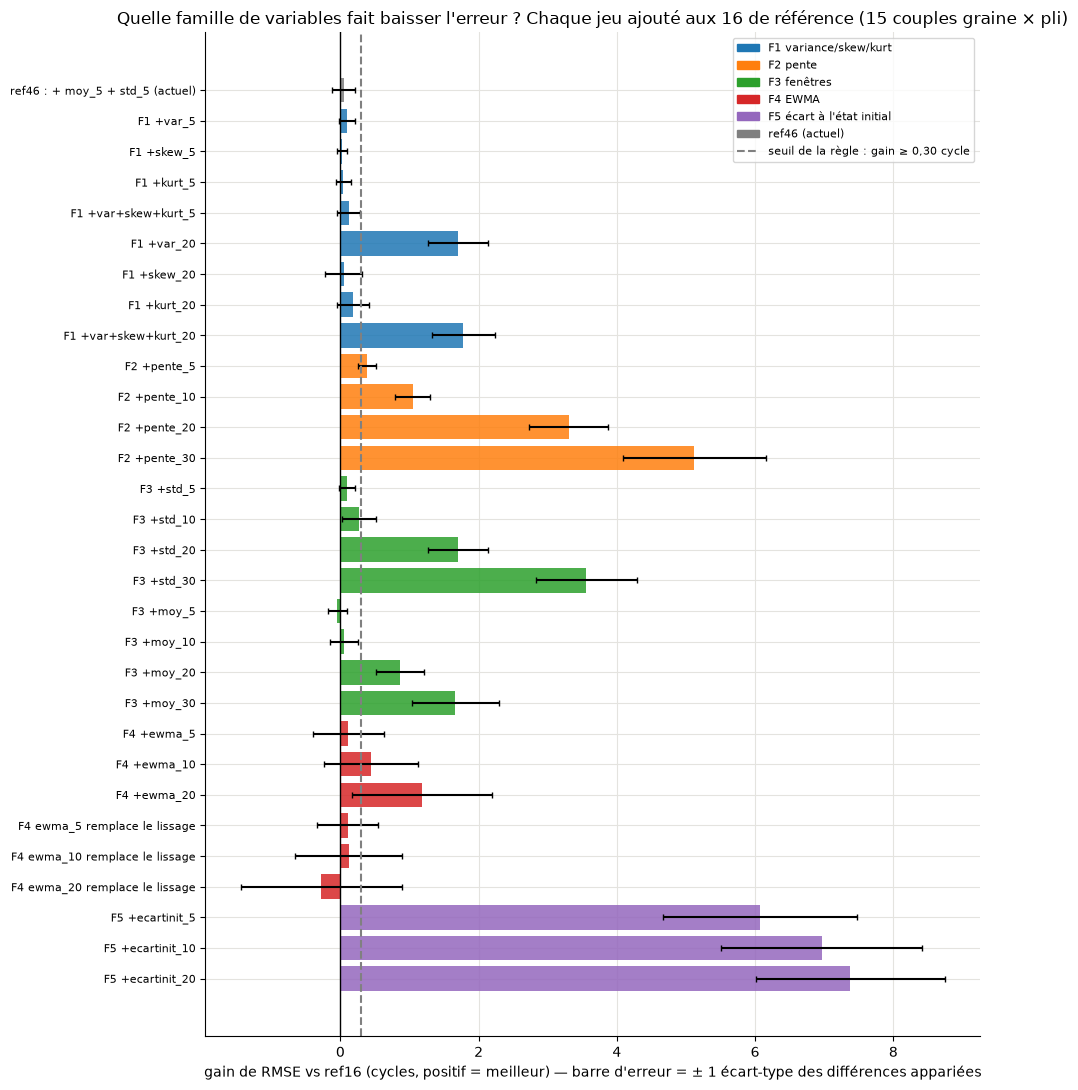

In [51]:
# ---- figure : gain de RMSE vs ref16, jeu par jeu, avec le bruit (ecart-type des differences appariees) ----
couleurs_famille = {"ref": "tab:grey", "F1": "tab:blue", "F2": "tab:orange", "F3": "tab:green", "F4": "tab:red", "F5": "tab:purple"}
noms_famille = {"ref": "référence", "F1": "F1 variance/skew/kurt", "F2": "F2 pente", "F3": "F3 fenêtres", "F4": "F4 EWMA", "F5": "F5 écart à l'état initial"}

a_tracer = tableau[~tableau["jeu"].str.startswith("ref16")].reset_index(drop=True)  # ref16 = ligne zero
positions = np.arange(len(a_tracer))

fig, ax = plt.subplots(figsize=(10, 11))
for i in range(len(a_tracer)):  # une barre par jeu
    ligne = a_tracer.iloc[i]
    ax.barh(positions[i], ligne["gain"], xerr=ligne["± bruit"], color=couleurs_famille[ligne["famille"]],
            alpha=0.85, ecolor="black", capsize=2)

ax.axvline(0, color="black", linewidth=1)
ax.axvline(0.30, color="grey", linestyle="--", label="seuil de la règle : gain ≥ 0,30 cycle")
ax.set_yticks(positions)
ax.set_yticklabels(a_tracer["jeu"], fontsize=8)
ax.invert_yaxis()  # premier jeu en haut
ax.set_xlabel("gain de RMSE vs ref16 (cycles, positif = meilleur) — barre d'erreur = ± 1 écart-type des différences appariées")
ax.set_title("Quelle famille de variables fait baisser l'erreur ? Chaque jeu ajouté aux 16 de référence (15 couples graine × pli)")

poignees = []
for cle, couleur in couleurs_famille.items():
    if cle != "ref":
        poignees.append(plt.Rectangle((0, 0), 1, 1, color=couleur, label=noms_famille[cle]))
poignees.append(plt.Rectangle((0, 0), 1, 1, color=couleurs_famille["ref"], label="ref46 (actuel)"))
legende_seuil = ax.get_legend_handles_labels()[0]
ax.legend(handles=poignees + legende_seuil, loc="upper right", fontsize=8)  # en haut a droite : les grandes barres F5 sont en bas

plt.tight_layout()
# (figure deja publiee dans docs/figures/04e_ablation_gain_rmse.png, citee par la doc : on ne l'ecrase pas)
plt.show()

### 6.6 Sélection (règle de la section 6.3)

On applique la règle telle qu'écrite. Pour chaque famille on garde, parmi ses variantes *retenues*, celle au meilleur gain. Les meilleures variantes retenues sont ensuite combinées en un seul jeu (si plusieurs familles passent), évalué comme les autres, puis le jeu final est choisi (meilleur RMSE, ou le plus simple à moins de 0,10 cycle).

In [52]:
retenus = tableau[tableau["retenu"]]
print(f"Jeux qui passent la règle : {len(retenus)} sur {len(tableau) - 2} candidats (hors ref16 et ref46)\n")
if len(retenus) > 0:
    print(retenus[["jeu", "nb", "gain", "± bruit", "mieux/15", "Δ NASA %"]].to_string(index=False))

# meilleure variante retenue de chaque famille
meilleur_par_famille = {}
for famille in ["F1", "F2", "F3", "F4", "F5"]:
    candidats_famille = retenus[retenus["famille"] == famille]
    if len(candidats_famille) > 0:
        meilleur = candidats_famille.sort_values("gain", ascending=False).iloc[0]
        meilleur_par_famille[famille] = meilleur["jeu"]
print(f"\nMeilleure variante retenue par famille : {meilleur_par_famille}")

Jeux qui passent la règle : 14 sur 29 candidats (hors ref16 et ref46)

                 jeu  nb     gain  ± bruit  mieux/15   Δ NASA %
          F1 +var_20  31 1.704293 0.431051        15 -31.092893
F1 +var+skew+kurt_20  61 1.777951 0.455303        15 -32.367057
         F2 +pente_5  31 0.387405 0.130955        15 -10.892209
        F2 +pente_10  31 1.045723 0.251178        15 -22.619752
        F2 +pente_20  31 3.303813 0.572959        15 -50.602225
        F2 +pente_30  31 5.122785 1.030140        15 -66.032841
          F3 +std_20  31 1.704295 0.431051        15 -31.092937
          F3 +std_30  31 3.560301 0.729848        15 -52.807582
          F3 +moy_20  31 0.857562 0.345077        15 -27.644775
          F3 +moy_30  31 1.664274 0.626553        15 -38.729209
         F4 +ewma_20  31 1.179912 1.008214        13 -28.697367
     F5 +ecartinit_5  31 6.069024 1.401759        15 -71.115666
    F5 +ecartinit_10  31 6.965805 1.453886        15 -76.852350
    F5 +ecartinit_20  31 7.377240

In [53]:
# ---- jeux finalistes : ref16, chaque meilleure variante retenue, et leur combinaison ----
finalistes = {"ref16 : capteurs + time_cycles": configs["ref16 : capteurs + time_cycles"]["colonnes"]}
for famille, nom in meilleur_par_famille.items():
    finalistes[nom] = configs[nom]["colonnes"]

if len(meilleur_par_famille) >= 2:  # une combinaison n'a de sens qu'avec au moins deux familles
    colonnes_combinees = list(base16)  # on part des 16 de reference
    for famille, nom in meilleur_par_famille.items():
        for colonne in configs[nom]["colonnes"]:
            if colonne not in colonnes_combinees:  # sans doublon
                colonnes_combinees.append(colonne)
    nom_combinaison = "combinaison : " + " + ".join(meilleur_par_famille.values())
    configs[nom_combinaison] = {"famille": "combi", "colonnes": colonnes_combinees}
    resultats[nom_combinaison] = evaluer_jeu(colonnes_combinees)
    finalistes[nom_combinaison] = colonnes_combinees

# evaluation de chaque finaliste avec la MEME regle que les autres (gain pairs vs ref16)
lignes_finales = []
for nom, colonnes in finalistes.items():
    r = resultats[nom]
    gains = ref["rmse"].values - r["rmse"].values
    delta_nasa = 100 * (r["nasa_moyen"].mean() / ref["nasa_moyen"].mean() - 1)
    passe = (gains.mean() >= 0.30) and (np.sum(gains > 0) >= 12) and (delta_nasa <= 5.0) and (not nom.startswith("ref16"))
    lignes_finales.append({"jeu": nom, "nb": len(colonnes), "RMSE 15": r["rmse"].mean(), "gain": gains.mean(),
                           "± bruit": gains.std(ddof=0), "mieux/15": int(np.sum(gains > 0)),
                           "Δ NASA %": delta_nasa, "RMSE fin": r["rmse_fin"].mean(), "passe": passe})
finales = pd.DataFrame(lignes_finales)
print(finales.round(3).to_string(index=False))

# ---- choix final : meilleur RMSE parmi les jeux qui passent, sinon ref16 ; a moins de 0.10 du meilleur -> le plus simple ----
passants = finales[finales["passe"]]
if len(passants) == 0:
    nom_final = "ref16 : capteurs + time_cycles"
    print("\nAucun jeu ne passe la règle -> jeu final = ref16 (16 features).")
else:
    meilleur_gain = passants["gain"].max()
    proches = passants[passants["gain"] >= meilleur_gain - 0.10]  # a moins de 0.10 cycle du meilleur
    nom_final = proches.sort_values(["nb", "RMSE 15"]).iloc[0]["jeu"]  # le moins de features, puis le meilleur RMSE
    print(f"\nJeu final : {nom_final}")

colonnes_finales = list(finalistes[nom_final])
print(f"{len(colonnes_finales)} features retenues.")

                                                                                            jeu  nb  RMSE 15  gain  ± bruit  mieux/15  Δ NASA %  RMSE fin  passe
                                                                 ref16 : capteurs + time_cycles  16   16.650 0.000    0.000         0     0.000     9.410  False
                                                                           F1 +var+skew+kurt_20  61   14.872 1.778    0.455        15   -32.367     6.341   True
                                                                                   F2 +pente_30  31   11.527 5.123    1.030        15   -66.033     4.182   True
                                                                                     F3 +std_30  31   13.089 3.560    0.730        15   -52.808     4.498   True
                                                                                    F4 +ewma_20  31   15.470 1.180    1.008        13   -28.697     6.446   True
                                  

### 6.7 Importance des features du jeu retenu : gain XGBoost **et** permutation

- **Gain XGBoost** : réduction totale de l'erreur apportée par les découpes qui utilisent la feature (modèle entraîné sur les 100 moteurs). Biaisé en faveur des features avec beaucoup de valeurs distinctes et instable entre features corrélées.
- **Importance par permutation** : on mélange au hasard les valeurs d'**une** colonne sur les moteurs de validation (jamais vus à l'entraînement) et on mesure la hausse de RMSE. Mesure ce que le modèle perd réellement sans cette information, sur des données non apprises. Calculée pli par pli (graine 42), 5 mélanges par pli.

Limite connue : quand deux features sont corrélées, mélanger l'une laisse l'autre compenser, donc leur importance par permutation est **sous-estimée** (surtout les capteurs lissés entre eux).

Ces importances sont gardées pour la Phase 5 (explicabilité).

In [54]:
X_final = X_train[colonnes_finales]

# ---- importance par gain : un modele entraine sur tous les moteurs ----
modele_gain = XGBRegressor(importance_type="gain", **REGLAGES_XGB)
modele_gain.fit(X_final, y)
importance_gain = pd.Series(modele_gain.feature_importances_, index=colonnes_finales)  # normalisee : somme = 1

# ---- importance par permutation : sur les moteurs de VALIDATION de chaque pli (graine 42) ----
hausses_par_pli = []
for idx_train, idx_val in plis_par_graine[42]:
    modele = XGBRegressor(**REGLAGES_XGB)
    modele.fit(X_final.iloc[idx_train], y.iloc[idx_train])
    resultat = permutation_importance(
        modele, X_final.iloc[idx_val], y.iloc[idx_val],
        scoring="neg_root_mean_squared_error",  # hausse de RMSE quand on melange la colonne
        n_repeats=5, random_state=42, n_jobs=1,
    )
    hausses_par_pli.append(resultat.importances_mean)  # un tableau (une valeur par colonne) par pli

hausses = np.array(hausses_par_pli)  # forme (5 plis, nb colonnes)
importance_permutation = pd.Series(hausses.mean(axis=0), index=colonnes_finales)
ecart_permutation = pd.Series(hausses.std(axis=0), index=colonnes_finales)  # variation entre plis

tableau_importance = pd.DataFrame({
    "gain (part)": importance_gain,
    "permutation (hausse RMSE)": importance_permutation,
    "± entre plis": ecart_permutation,
}).sort_values("permutation (hausse RMSE)", ascending=False)
print(tableau_importance.round(4).head(20).to_string())

                        gain (part)  permutation (hausse RMSE)  ± entre plis
time_cycles                  0.0054                     7.2792        0.9299
sensor_11|ecartinit_20       0.3833                     5.2719        1.1590
sensor_9|ecartinit_20        0.0170                     4.5161        1.0123
sensor_4|ecartinit_20        0.1063                     1.9330        0.7517
sensor_14|ecartinit_20       0.0082                     1.6888        0.5273
sensor_15|ecartinit_20       0.1390                     1.5856        0.5162
sensor_13|ecartinit_20       0.0072                     1.2521        0.3119
sensor_8|ecartinit_20        0.0081                     1.2508        0.4805
sensor_7|ecartinit_20        0.0524                     1.2451        0.2561
sensor_12|ecartinit_20       0.0262                     0.9490        0.2318
sensor_4                     0.0390                     0.8641        0.1200
sensor_20|ecartinit_20       0.0319                     0.6177        0.3570

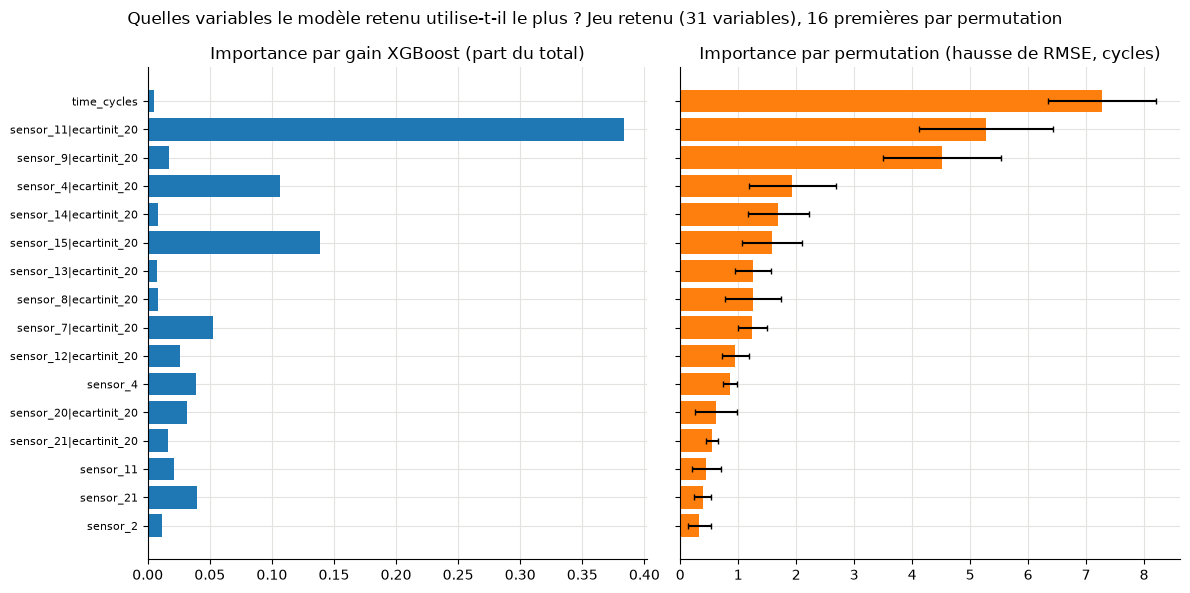

Correlation de rang gain / permutation (toutes les features) : 0.72


In [55]:
# ---- figure : les deux importances cote a cote, memes features, classees par permutation ----
top = tableau_importance.head(16).iloc[::-1]  # 16 premieres, la plus importante en haut du graphique
positions = np.arange(len(top))

fig, (ax_gain, ax_perm) = plt.subplots(1, 2, figsize=(12, 6), sharey=True)
ax_gain.barh(positions, top["gain (part)"], color="tab:blue")
ax_gain.set_title("Importance par gain XGBoost (part du total)")
ax_gain.set_yticks(positions)
ax_gain.set_yticklabels(top.index, fontsize=8)

ax_perm.barh(positions, top["permutation (hausse RMSE)"], xerr=top["± entre plis"], color="tab:orange", ecolor="black", capsize=2)
ax_perm.set_title("Importance par permutation (hausse de RMSE, cycles)")
fig.suptitle(f"Quelles variables le modèle retenu utilise-t-il le plus ? Jeu retenu ({len(colonnes_finales)} variables), 16 premières par permutation")

plt.tight_layout()
# (figure deja publiee dans docs/figures/04e_importances_jeu_retenu.png : on ne l'ecrase pas)
plt.show()

# les deux classements s'accordent-ils ? (correlation de rang de Spearman entre les deux importances)
rho = stats.spearmanr(tableau_importance["gain (part)"], tableau_importance["permutation (hausse RMSE)"]).statistic
print(f"Correlation de rang gain / permutation (toutes les features) : {rho:.2f}")

### 6.8 Synthèse chiffrée (validation)

Reprise de la synthèse du 04e, sans la ligne du test officiel (section 8 du 04e, déplacée dans `evolution`, étape 4).

In [56]:
# ---- synthese chiffree (a recopier dans le rapport) ----
final_ligne = finales[finales["jeu"] == nom_final].iloc[0]
ref46_ligne = tableau[tableau["jeu"].str.startswith("ref46")].iloc[0]
ref16_ligne = tableau[tableau["jeu"].str.startswith("ref16")].iloc[0]
print(f"Jeu retenu : {nom_final} ({len(colonnes_finales)} features)")
print(f"  validation (15 couples graine x pli) : RMSE {final_ligne['RMSE 15']:.2f}   | ref16 {ref16_ligne['RMSE 15']:.2f}   | ref46 {ref46_ligne['RMSE 15']:.2f}")
print(f"  gain apparie vs ref16 : {final_ligne['gain']:+.2f} +/- {final_ligne['± bruit']:.2f} (bat ref16 sur {final_ligne['mieux/15']}/15)")
print(f"  gain apparie ref46 vs ref16 : {ref46_ligne['gain']:+.2f} +/- {ref46_ligne['± bruit']:.2f}")
# (test officiel du jeu retenu : evolution, etape 4)

print("\nJeux ecartes (aucun ne passe la regle) ou non retenus : voir le tableau 6.5, colonne 'retenu'.")

Jeu retenu : F5 +ecartinit_20 (31 features)
  validation (15 couples graine x pli) : RMSE 9.27   | ref16 16.65   | ref46 16.60
  gain apparie vs ref16 : +7.38 +/- 1.37 (bat ref16 sur 15/15)
  gain apparie ref46 vs ref16 : +0.05 +/- 0.17

Jeux ecartes (aucun ne passe la regle) ou non retenus : voir le tableau 6.5, colonne 'retenu'.


**Section 9 du 04e (retirée)** : variantes testées **après** lecture des résultats, jamais évaluées sur le test, aucune retenue. Résultat, d'après les conclusions du 04e : `ecartinit_30` et `ecartinit_50` font +0,21 de mieux que `ecartinit_20` (dans le bruit, sous le seuil de 0,30), `ecartinit_80` −0,12 ; versions plus simples moins bonnes (16 variables `ecartinit_20` + `time_cycles` : 10,18 ; 30 variables sans `time_cycles` : 12,42 ; 16 + pente : 10,33). Code et sorties : notebook 04e au tag `v1-avant-reorganisation`.

### 6.9 Conclusions du 04e (rédigées sur les sorties du 04e ; les chiffres de cette exécution sont dans les cellules ci-dessus)

> Rédigées **après** exécution. Les hypothèses de la section 4 n'ont pas été modifiées.

### Verdict par famille (gain de RMSE vs `ref16`, moyenne des différences appariées sur 15 couples graine × pli ; bruit typique entre plis ≈ 1,2)

| Famille | Hypothèse (section 4) | Résultat | Verdict |
|---|---|---|---|
| **F5** écart à l'état initial | gain plausible, « deuxième après la pente » | `ecartinit_5` **+6,07**, `_10` **+6,97**, `_20` **+7,38** (15/15 plis) ; `_30` et `_50` +7,59 ; `_80` +7,26 | **Confirmée, bien au-delà de l'attendu : de loin la meilleure famille** |
| **F2** pente | famille la plus plausible d'un gain, k=5 trop bruité | `pente_5` +0,39, `_10` +1,05, `_20` +3,30, `_30` +5,12, `_50` +7,30 | Confirmée ; le gain croît avec la fenêtre |
| **F3** fenêtres | moyennes redondantes ; écart-type long = léger gain | `moy_5` −0,04, `moy_10` +0,05 (redondantes, comme prévu) mais `moy_20` +0,86, `moy_30` +1,66 ; `std_10` +0,27, `std_20` +1,70, `std_30` +3,56, `std_50` +5,84 | Partiellement **infirmée** : les moyennes longues apportent (une moyenne sur 30 cycles est un niveau *passé*, que le niveau actuel peut comparer) ; le gain des écarts-types longs est bien plus grand que « léger » |
| **F1** variance / asymétrie / kurtosis | rien en k=5 ; au mieux un petit effet en k=20 | k=5 : `var` +0,10, `skew` +0,02, `kurt` +0,04. k=20 : `var` **+1,70**, `skew` +0,05, `kurt` +0,18 | Confirmée pour skew/kurt (rien). La variance à k=20 apporte, mais voir la remarque ci-dessous |
| **F4** EWMA | ajout redondant ; en remplacement du lissage, égalité | ajout : `ewma_5` +0,12, `_10` +0,44 (11/15), `_20` +1,18 (13/15, bruit 1,0) ; remplacement : +0,10, +0,12, −0,28 | Confirmée : en remplacement, jeu égal (différences de −0,28 à +0,12, dans le bruit) ; un autre filtre, pas une autre information |

**Remarque sur F1 et F3 :** `var_20` et `std_20` donnent exactement le même résultat (gain +1,70 pour les deux). C'est normal : la variance est le carré de l'écart-type, et les arbres de décision ne dépendent que de l'ordre des valeurs, pas de leur échelle. Ce ne sont pas deux informations, mais une seule.

### Jeu retenu (règle de la section 3, appliquée telle qu'écrite)

**`ref16` + `ecartinit_20`, soit 31 features** (15 capteurs lissés, `time_cycles`, 15 écarts à l'état initial sur 20 cycles).

| | `ref16` (16) | `ref46` (46, Phase 3) | **retenu (31)** |
|---|---|---|---|
| Validation, RMSE (15 couples) | 16,65 | 16,60 | **9,27** |
| Gain apparié vs `ref16` | — | +0,05 ± 0,17 | **+7,38 ± 1,37, 15/15** |
| Score NASA moyen par prédiction | 6,88 | | 1,47 (−78,6 %) |
| RMSE en fin de vie (RUL ≤ 30) | 9,41 | 9,48 | 3,69 |
| **Test officiel : RMSE** | | 19,70 | **13,10** |
| Test officiel : score NASA (somme) | | 852,9 | **237,0** |
| Test officiel : surestimés de plus de 20 cycles | | 9/100 | **2/100** |

Sur le test, le jeu retenu a une erreur absolue plus petite sur 60 moteurs sur 100, et le Wilcoxon apparié donne p < 0,001. Le benchmark exploratoire du README (RMSE test 18,97) est battu. **Le test n'a servi qu'une fois pour ce jeu** (plus une réévaluation de `ref46`, dont le chiffre était déjà publié, pour la comparaison moteur par moteur).

### Pourquoi 31 et pas moins ni plus (règle 9)

- **Combiner toutes les familles retenues (121 features) fait moins bien (9,58) que `ecartinit_20` seul (9,27)** : les familles se recouvrent, empiler ne sert à rien.
- **Plus simple, à performance égale ?** Non. `ecartinit_20` + `time_cycles` seuls (16 features) : 10,18 (−0,91 vs retenu, moins bon sur 15/15 plis). Sans `time_cycles` (30 features) : 12,42. Ajouter la pente à la version à 16 : 10,33. Le jeu à 31 features reste donc le plus simple des jeux au niveau de 9,3.
- **Fenêtre de `ecartinit`** : 30 et 50 font +0,21 de mieux que 20, dans le bruit (écart-type de la différence 0,23 à 0,31, et sous le seuil de 0,30 de la règle) ; 80 fait −0,12. L'optimum est donc autour de 20-50 et **bien encadré** par l'extension de la section 9. 20 est conservé : la règle ne justifie pas de changer.

### Écarté, avec la raison chiffrée

- `skew_5`, `skew_20`, `kurt_5`, `kurt_20`, `var_5`, `std_5`, `moy_5`, `moy_10`, `ewma_5`, `std_10` : gain de −0,04 à +0,27, sous le seuil de 0,30 et dans le bruit.
- Les colonnes de `ref46` (`moy_5` + `std_5`, 30 features) : **+0,05 ± 0,17**, indiscernable de zéro, 8 plis sur 15 seulement. Elles ne sont pas conservées.
- Remplacer le lissage par une EWMA : égalité (−0,28 à +0,12), aucun intérêt à changer un choix de la Phase 1 qui marche.
- La combinaison de toutes les familles (121 features) : 9,58, pire que `ecartinit_20` seul.

### Importance des features du jeu retenu (section 7)

- **Permutation** (hausse du RMSE quand on mélange la colonne, sur des moteurs jamais vus) : `time_cycles` 7,28 ; `sensor_11|ecartinit_20` 5,27 ; `sensor_9|ecartinit_20` 4,52 ; `sensor_4|ecartinit_20` 1,93 ; les capteurs lissés seuls pèsent au plus 0,86 (`sensor_4`).
- **Gain XGBoost** : `sensor_11|ecartinit_20` 0,38 ; `sensor_15|ecartinit_20` 0,14 ; `sensor_4|ecartinit_20` 0,11 ; `time_cycles` seulement 0,005. **Les deux mesures ne s'accordent pas sur `time_cycles`** (corrélation de rang globale 0,72). Le gain compte les découpes, pas ce que le modèle perd sans la variable ; et `time_cycles` reste décisif quand on l'enlève (12,42 au lieu de 9,27). On se fie à la permutation, avec sa limite connue : elle sous-estime les variables corrélées entre elles.

### Limites et points à vérifier (règle 11)

1. **`ecartinit` suppose qu'on observe le moteur depuis son cycle 1.** C'est vrai dans C-MAPSS (train et test commencent au cycle 1), pas forcément en exploitation : un moteur déployé en cours de vie n'a pas d'« état initial » connu. À écrire dans le rapport de phase.
2. **Le mécanisme n'est pas prouvé.** L'hypothèse (les moteurs partent de niveaux différents, et soustraire ce niveau isole la dégradation) est cohérente avec les résultats mais je n'ai pas mesuré la dispersion du niveau initial entre moteurs. Une figure « niveau initial de `sensor_11` pour les 100 moteurs » la confirmerait ou non.
3. **Optimisme de sélection.** La fenêtre (20) et la famille ont été choisies sur la validation ; le test indépendant (19,70 → 13,10) confirme le gain, mais l'ordre de grandeur de la validation (9,27) est, comme toujours, un peu optimiste.
4. **Les p-valeurs de Wilcoxon sur 15 couples sont optimistes** (les 3 graines réutilisent les mêmes 100 moteurs). Le critère « bat `ref16` sur 15 plis sur 15 » et la taille du gain retenu (+7,38, plus de 5 fois l'écart-type des différences appariées) pèsent plus que ces p-valeurs.
5. **Une affirmation faite plus tôt dans la session était à nuancer** : mesurer l'erreur « au dernier cycle de chaque moteur de validation » n'aurait rien apporté, puisque tous les moteurs d'entraînement finissent à RUL = 0. Évaluer toutes les lignes équivaut à moyenner sur des coupes de trajectoire uniformes ; ce qui diffère du test est la répartition des RUL (non plafonnées, de 7 à 145), pas le fait d'évaluer plusieurs cycles.
6. **Non fait ici** : normalisation du scaler à l'intérieur des plis (sans effet sur XGBoost, à faire pour un LSTM), FD002 à FD004 (normalisation par régime), réglage des hyperparamètres sur le nouveau jeu de features (autre session), importance SHAP (Phase 5). Les réglages XGBoost sont ceux de la Phase 3 ; les hyperparamètres optimaux ont pu changer avec ces features.

### Décision de la section 6

**Décision : le jeu de variables retenu a 31 variables** : 15 capteurs lissés, `time_cycles`, et l'écart de chaque capteur à son état initial sur 20 cycles (`ecartinit_20`). Les moyennes et écarts-types glissants de la Phase 3 sont abandonnés.

**Chiffre** (cette exécution) : gain apparié contre `ref16` **+7,38 ± 1,37**, meilleur sur **15/15** couples (graine, pli) ; les colonnes de `ref46` n'apportent que +0,05 ± 0,17. Règle écrite avant les résultats : gain ≥ 0,30, au moins 12/15, score NASA non dégradé de plus de 5 %.

**Coûts et limites** : `ecartinit` suppose qu'on observe le moteur depuis son premier cycle (vrai dans C-MAPSS, pas forcément en exploitation) ; choix fait avec les réglages de la Phase 3, sur FD001 seulement.

## 7. L'écart à l'état initial, pour les 5 modèles qui apprennent

*Repris du notebook `05_comparaison_evaluation` (section F, sauf F.7, test officiel, déplacé dans `evolution`, section 4.7).*

**Ce qui a fondé la décision (anciens modèles)** : la règle est appliquée aux versions « de base » de chaque modèle (arbres à réglages de base, réseaux du 03b). Les versions retenues en v2 (réglages Optuna) ont toutes `ecartinit` en entrée.

### 7.0 Améliorations testées (FD001, validation croisée)

Le notebook 05 comparait d'abord des modèles **à réglages de base**, avec les 46 variables de la Phase 3. Sa section F essaie deux idées pour faire mieux. Une idée n'est gardée que si elle passe une **règle écrite avant de voir les résultats**, jugée sur la validation croisée seulement (les 5 plis de la section 3).

| Idée | Modèles concernés | D'où elle vient |
|---|---|---|
| 1. Ajouter `ecartinit_20` : l'écart de chaque capteur à son propre état de départ | les 5 modèles qui apprennent (Random Forest, XGBoost, LightGBM, LSTM, CNN 1D) | notebook `04e_feature_engineering` de Matisse |
| 2. Donner aux réseaux 50 cycles d'historique au lieu de 30 | LSTM et CNN 1D | articles DAST (fenêtres de 40 à 60 cycles) et STAGNN (50 cycles), section H |

**Qui calcule quoi** : les entraînements sont longs, ils sont faits par deux scripts (`scripts/generer_predictions_arbres.py` pour les arbres, `scripts/entrainer_deep_learning.py` pour les réseaux) qui écrivent leurs résultats dans `sorties/resultats/`. Ce notebook **relit** ces résultats : il ne réentraîne aucun des modèles de cette section. Le test officiel n'a été calculé qu'après la décision, une seule fois par version évaluée (F.7) : la version retenue de chaque modèle et, pour les arbres, la version de base (le modèle final publié avant cette étude) ; un candidat non retenu n'est jamais évalué sur le test. Pour XGBoost, la version à 31 variables avait déjà été évaluée une fois sur le test par Matisse (04e, après son choix en validation croisée) : le script redonne exactement son chiffre.

### 7.1 Lecture des résultats des scripts

**Ce qu'on fait** : on vérifie que tous les fichiers produits par les scripts sont présents. S'il en manque un, la cellule s'arrête et affiche la commande à lancer depuis la racine du dépôt (rien n'est réentraîné ici). La règle des arbres est lue directement dans le script qui l'applique.

In [57]:
# bibliotheques supplementaires pour cette section
import textwrap  # coupe les longs textes en lignes de largeur fixe pour l'affichage

from src.inference import module_script_arbres  # charge scripts/generer_predictions_arbres.py comme un module (sans lancer son main)

SOUS_JEUX = ["FD001", "FD002", "FD003", "FD004"]

# commandes a lancer depuis la racine du depot si un fichier manque (durees mesurees sur la machine du projet)
COMMANDE_ARBRES = "python scripts/preparer_demo.py (etape des arbres : scripts/generer_predictions_arbres.py, environ 12 minutes)"
COMMANDE_RESEAUX = "fichier versionne de docs/resultats/03b/ (git checkout) ; il a ete produit par scripts/entrainer_deep_learning.py --cv-sous-jeux"

# les modeles concernes : cle des fichiers -> nom affiche dans les tableaux
MODELES_RETENUS = {}
MODELES_RETENUS["reference_naive"] = "Reference naive"
MODELES_RETENUS["random_forest"] = "Random Forest"
MODELES_RETENUS["lightgbm"] = "LightGBM"
MODELES_RETENUS["xgboost_phase3"] = "XGBoost"
MODELES_RETENUS["lstm"] = "LSTM"
MODELES_RETENUS["cnn1d"] = "CNN 1D"
CLES_ARBRES = ["reference_naive", "random_forest", "xgboost_phase3", "lightgbm"]  # produits par le script des arbres
CLES_RESEAUX = ["lstm", "cnn1d"]  # produits par le script des reseaux

# fichier attendu -> commande qui le produit
FICHIERS_ATTENDUS = {}
FICHIERS_ATTENDUS[os.path.join(DOSSIER_RESULTATS, "05_arbres_choix_features.csv")] = COMMANDE_ARBRES
for nom_fichier in ["03b_candidats_fd001.csv", "03b_candidats_fd001.json"]:
    FICHIERS_ATTENDUS[os.path.join(DOSSIER_03B, nom_fichier)] = COMMANDE_RESEAUX

manquants = []  # (fichier, commande) des fichiers absents
for chemin in FICHIERS_ATTENDUS:
    if not os.path.exists(chemin):
        manquants.append((chemin, FICHIERS_ATTENDUS[chemin]))

if len(manquants) > 0:
    print("Fichiers manquants, a produire avec la commande indiquee (depuis la racine du depot) :")
    for chemin, commande in manquants:
        print(f"  {chemin}\n      -> {commande}")
    raise FileNotFoundError(f"{len(manquants)} fichier(s) de resultats manquant(s) : voir la liste ci-dessus.")
print(f"Les {len(FICHIERS_ATTENDUS)} fichiers de resultats attendus sont presents.")

Les 3 fichiers de resultats attendus sont presents.


### 7.2 Idée 1 — la variable `ecartinit_20` (Matisse, notebook 04e, section 6 ci-dessus)

**L'idée.** Deux moteurs neufs n'ont pas exactement les mêmes valeurs de capteurs (petites différences de fabrication). La valeur d'un capteur seule dit donc mal où en est un moteur ; ce qui annonce la panne, c'est **de combien il s'est éloigné de son propre état de départ**. Pour chaque capteur lissé x d'un moteur :

ecartinit_20(t) = x(t) − moyenne de x sur les 20 premiers cycles du moteur.

Tant que t < 20, la moyenne porte sur les t cycles déjà vus : on n'utilise **jamais** un cycle futur (vérifié par `test_ecart_etat_initial_causal_et_par_moteur` dans `tests/test_anti_triche.py`).

**Exemple** (avec 3 cycles de référence au lieu de 20, pour la lisibilité) : un capteur vaut 10, 12, 14 puis 20. La référence vaut 10 (cycle 1), puis 11, puis 12, et reste figée à 12 ensuite. L'écart vaut donc 0, 1, 2 puis 8.

**D'où elle vient.** Le notebook `04e_feature_engineering` de Matisse conclut un jeu de **31 variables** : les 15 capteurs lissés, `time_cycles` et les 15 écarts `<capteur>_ecartinit_20`. Pour les arbres, ce jeu **remplace** les 46 variables de base. Pour les réseaux (candidat « A »), on ajoute les 15 écarts (mis à l'échelle entre 0 et 1) aux 15 capteurs et à `time_cycles` / 100 : 31 entrées aussi.

**Ce qu'on attend.** Une baisse nette de l'erreur pour tous les modèles, puisque la variable rend comparables des moteurs qui partent de niveaux différents.

**Règle de décision**, écrite dans les scripts avant les expériences (texte commun aux deux scripts, recopié tel quel) :

> Pour chaque modele, une amelioration est retenue sur FD001 si, sur les memes 5 plis par moteur, (a) le RMSE moyen de validation baisse d'au moins 0,3 cycle (seuil de Matisse, notebook 04d) ET (b) le test de Wilcoxon apparie sur le RMSE par moteur (100 moteurs, prediction hors-pli) donne p < 0,05 en faveur du candidat. Sinon on garde la version de base. Le score NASA et les surestimations de plus de 20 cycles sont rapportes a cote ; si le candidat les degrade nettement, le dire. Les choix faits sur FD001 sont appliques tels quels a FD002-FD004 (le dire comme limite).

Mise en œuvre, fixée elle aussi avant les résultats : la p-valeur de Wilcoxon est **bilatérale** (`comparer_apparie` de `src/evaluation.py`) et « en faveur du candidat » veut dire que la différence moyenne (RMSE candidat − RMSE base, moteur par moteur) est **négative**. La cellule suivante affiche les textes complets tels que les scripts les ont enregistrés.

In [58]:
# regle des arbres : constante REGLE_DE_DECISION de scripts/generer_predictions_arbres.py (le script la recopiait
# dans les metadonnees de chaque fichier de predictions ; on la lit a la source, sans dependre de sorties/predictions/)
regle_arbres = module_script_arbres().REGLE_DE_DECISION
# regle des reseaux : enregistree par le script avec ses decisions
with open(os.path.join(DOSSIER_03B, "03b_candidats_fd001.json"), encoding="utf-8") as fichier:
    decisions_reseaux = json.load(fichier)

print("Regle des modeles a arbres (scripts/generer_predictions_arbres.py) :")
print(textwrap.fill(regle_arbres, width=110))
print("\nRegle des reseaux (scripts/entrainer_deep_learning.py) :")
print(textwrap.fill(decisions_reseaux["regle"], width=110))
print("\nPrecisions des reseaux, fixees avant les resultats :")
print(textwrap.fill(decisions_reseaux["precisions"], width=110))

Regle des modeles a arbres (scripts/generer_predictions_arbres.py) :
Pour chaque modele, une amelioration est retenue sur FD001 si, sur les memes 5 plis par moteur, (a) le RMSE
moyen de validation baisse d'au moins 0,3 cycle (seuil de Matisse, notebook 04d) ET (b) le test de Wilcoxon
apparie sur le RMSE par moteur (100 moteurs, prediction hors-pli) donne p < 0,05 en faveur du candidat. Sinon
on garde la version de base. Le score NASA et les surestimations de plus de 20 cycles sont rapportes a cote ;
si le candidat les degrade nettement, le dire. Les choix faits sur FD001 sont appliques tels quels a
FD002-FD004 (le dire comme limite). Mise en oeuvre : p-valeur bilaterale de scipy.stats.wilcoxon
(src/evaluation.py, comparer_apparie), et 'en faveur du candidat' = difference moyenne (RMSE candidat - RMSE
base, moteur par moteur) negative ; la p-valeur unilaterale est rapportee a cote.

Regle des reseaux (scripts/entrainer_deep_learning.py) :
Pour chaque modele, une amelioration est retenue

### 7.3 Résultat de l'idée 1 pour les modèles à arbres

**Comment lire** : une ligne par modèle. `rmse_cv` = moyenne ± écart-type des 5 plis (en cycles) ; `(a)` et `(b)` = les deux conditions de la règle ; `moteurs_meilleurs` = nombre de moteurs (sur 100) où le candidat a un RMSE plus petit ; les trois dernières colonnes de chiffres disent si le candidat dégrade la prudence (score NASA de validation, lignes surestimées de plus de 20 cycles, alertes manquées). La référence naïve prédit toujours la même valeur : elle ignore les variables, aucun test n'est possible et elle garde la base.

In [59]:
# formater_moyenne_ecart (« moyenne ± ecart-type ») : la fonction du 05 (A.5) vit maintenant dans src/
from src.evaluation_sous_jeu import formater_moyenne_ecart


def p_valeur_lisible(p_valeur):
    """
    Ecrit une p-valeur en notation scientifique courte, ou "sans objet" si elle n'existe pas.

    Parameters
    ----------
    p_valeur : float
        La p-valeur (NaN si aucun test n'a ete possible).

    Returns
    -------
    str
        Par exemple "9.9e-16", ou "sans objet".
    """
    if pd.isna(p_valeur):
        return "sans objet"
    return f"{p_valeur:.1e}"


choix_arbres = pd.read_csv(os.path.join(DOSSIER_RESULTATS, "05_arbres_choix_features.csv"))
choix_fd001 = choix_arbres[choix_arbres["sous_jeu"] == "FD001"].set_index("modele")  # la decision se prend sur FD001

lignes = []
for cle in CLES_ARBRES:
    source = choix_fd001.loc[cle]  # la ligne du script pour ce modele
    ligne = {}
    ligne["modele"] = MODELES_RETENUS[cle]
    ligne["rmse_cv_base_46"] = formater_moyenne_ecart(source["rmse_cv_base"], source["rmse_cv_ecart_type_base"])
    ligne["rmse_cv_candidat_31"] = formater_moyenne_ecart(source["rmse_cv_candidat"], source["rmse_cv_ecart_type_candidat"])
    ligne["baisse"] = round(source["baisse_rmse_cv"], 2)
    ligne["(a) baisse >= 0,3"] = bool(source["condition_a_baisse_rmse"])
    ligne["p_wilcoxon"] = p_valeur_lisible(source["p_wilcoxon_bilaterale"])
    ligne["moteurs_meilleurs"] = int(source["nb_moteurs_candidat_meilleur"])
    ligne["(b) p < 0,05 en faveur"] = bool(source["condition_b_wilcoxon"])
    ligne["nasa_cv base -> candidat"] = f"{source['nasa_cv_base']:.0f} -> {source['nasa_cv_candidat']:.0f}"
    ligne["surestimes_oof base -> candidat"] = f"{source['surestimes_oof_base']} -> {source['surestimes_oof_candidat']}"
    ligne["alertes_manquees_oof base -> candidat"] = (
        f"{source['alertes_manquees_oof_base']} -> {source['alertes_manquees_oof_candidat']}")
    ligne["decision"] = source["jeu_retenu"]
    lignes.append(ligne)
tableau_choix_arbres = pd.DataFrame(lignes).set_index("modele")
tableau_choix_arbres

,rmse_cv_base_46,rmse_cv_candidat_31,baisse,"(a) baisse >= 0,3",p_wilcoxon,moteurs_meilleurs,"(b) p < 0,05 en faveur",nasa_cv base -> candidat,surestimes_oof base -> candidat,alertes_manquees_oof base -> candidat,decision
modele,,,,,,,,,,,
Reference naive,41.69 ± 0.12,41.69 ± 0.12,0.00,False,sans objet,0,False,1271462 -> 1271462,6720 -> 6720,3100 -> 3100,base
Random Forest,16.96 ± 1.27,10.19 ± 0.69,6.78,True,7.3e-14,84,True,29773 -> 7374,2302 -> 876,565 -> 321,ecart_initial_20
XGBoost,16.87 ± 1.25,9.36 ± 0.33,7.51,True,9.9e-16,87,True,29783 -> 6310,2384 -> 754,552 -> 254,ecart_initial_20
LightGBM,16.85 ± 1.30,9.35 ± 0.48,7.50,True,4.3e-15,85,True,30142 -> 6372,2316 -> 758,568 -> 258,ecart_initial_20


### 7.4 Résultat de l'idée 1 pour les réseaux (candidat A)

**Ce qu'on fait** : même règle, appliquée à chaque réseau séparément. « base » = fenêtre de 30 cycles, 15 capteurs + `time_cycles` / 100 (16 entrées, notebook 03b) ; « A » = la même chose + les 15 écarts `ecartinit_20` (31 entrées). Mêmes colonnes qu'en 7.3 ; `compare_a` dit contre quelle version le candidat est jugé.

In [60]:
candidats_reseaux = pd.read_csv(os.path.join(DOSSIER_03B, "03b_candidats_fd001.csv"))
NOMS_RESEAUX = {"lstm": "LSTM", "cnn1d": "CNN 1D"}
DESCRIPTION_CANDIDATS = {}  # code du candidat -> description courte
DESCRIPTION_CANDIDATS["base"] = "fenetre 30"
DESCRIPTION_CANDIDATS["A"] = "fenetre 30 + ecartinit_20"
DESCRIPTION_CANDIDATS["B"] = "fenetre 50"
DESCRIPTION_CANDIDATS["AB"] = "fenetre 50 + ecartinit_20"


def texte_ou_tiret(valeur):
    """
    Renvoie la valeur sous forme de texte, ou un tiret si elle est absente (cas de la version de base).

    Parameters
    ----------
    valeur : object
        Une valeur lue dans le fichier (NaN si absente).

    Returns
    -------
    str
        La valeur en texte, ou "-".
    """
    if pd.isna(valeur):
        return "-"
    return str(valeur)


def tableau_candidats_reseaux(candidats, codes_a_montrer):
    """
    Met en forme les candidats des reseaux (fichier 03b_candidats_fd001.csv), une ligne par reseau et candidat.

    Parameters
    ----------
    candidats : pandas.DataFrame
        Le contenu de 03b_candidats_fd001.csv.
    codes_a_montrer : list de str
        Les codes des candidats a afficher ("base", "A", "B", "AB").

    Returns
    -------
    pandas.DataFrame
        Index (reseau, candidat) ; RMSE CV, comparaison, conditions de la regle et indicateurs de prudence.
    """
    lignes = []
    for reseau in ["lstm", "cnn1d"]:  # LSTM d'abord, puis CNN 1D
        for code_candidat in codes_a_montrer:
            selection = candidats[(candidats["type_modele"] == reseau) & (candidats["candidat"] == code_candidat)]
            if len(selection) == 0:
                continue  # candidat non evalue pour ce reseau (A+B seulement si A et B passent la regle)
            source = selection.iloc[0]
            ligne = {}
            ligne["reseau"] = NOMS_RESEAUX[reseau]
            ligne["candidat"] = code_candidat
            ligne["entrees"] = DESCRIPTION_CANDIDATS[code_candidat]
            ligne["nb_entrees"] = int(source["nb_entrees"])
            ligne["rmse_cv"] = formater_moyenne_ecart(source["rmse_cv_moyen"], source["rmse_cv_ecart_type"])
            ligne["compare_a"] = texte_ou_tiret(source["compare_a"])
            if pd.isna(source["gain_rmse"]):
                ligne["baisse"] = "-"
            else:
                ligne["baisse"] = f"{source['gain_rmse']:.2f}"
            if pd.isna(source["p_wilcoxon"]):
                ligne["p_wilcoxon"] = "-"
            else:
                ligne["p_wilcoxon"] = p_valeur_lisible(source["p_wilcoxon"])
            ligne["moteurs_meilleurs"] = texte_ou_tiret(source["nb_moteurs_ameliores"]).replace(".0", "")
            ligne["(a)"] = texte_ou_tiret(source["critere_a"])
            ligne["(b)"] = texte_ou_tiret(source["critere_b"])
            ligne["retenu"] = texte_ou_tiret(source["retenu"])
            ligne["nasa_cv"] = round(source["nasa_cv_moyen"])
            ligne["surestimes_oof"] = int(source["surestimes_oof"])
            ligne["alertes_manquees_oof"] = int(source["alertes_manquees_oof"])
            lignes.append(ligne)
    return pd.DataFrame(lignes).set_index(["reseau", "candidat"])


tableau_candidats_reseaux(candidats_reseaux, ["base", "A"])

entrees  nb_entrees       rmse_cv compare_a baisse p_wilcoxon moteurs_meilleurs   (a)   (b) retenu  nasa_cv  surestimes_oof  alertes_manquees_oof
reseau candidat                                                                                                                                                                     
LSTM   base                     fenetre 30          16  13.70 ± 1.76         -      -          -                 -     -     -      -    15630            1503                   298
       A         fenetre 30 + ecartinit_20          31   8.94 ± 0.92      base   4.76    2.1e-13                83  True  True   True     6123             799                   154
CNN 1D base                     fenetre 30          16  16.96 ± 1.82         -      -          -                 -     -     -      -    24051            1786                   388
       A         fenetre 30 + ecartinit_20          31  10.05 ± 0.96      base   6.92    2.2e-13                85  True  True   True     8173             831                   253

### 7.5 Idée 2 — une fenêtre de 50 cycles pour les réseaux : rejetée

Idée venue des articles DAST (fenêtres de 40 à 60 cycles) et STAGNN (50 cycles), même règle, combinaison A+B comparée au meilleur des deux. **Résultat (05, F.5)** : LSTM, la fenêtre de 50 passe contre la base (13,70 → 11,32), mais A+B (9,32) ne bat pas A (8,94 ; **p = 0,063**) : A est gardé. CNN 1D : −0,89 cycle, **p = 0,41**, rejetée. Le tableau détaillé est retiré (plan 8.2 : « en une ligne avec sa p-valeur ») ; la cellule suivante affiche la décision enregistrée par le script, et le contrôle 7.7 vérifie ces chiffres dans le fichier.

**Décision enregistrée par le script**, pour chaque réseau : les candidats qui passent la règle contre la base, puis la version finalement retenue (longueur de fenêtre et nombre de cycles de référence de `ecartinit`).

In [61]:
for reseau in ["lstm", "cnn1d"]:
    decision = decisions_reseaux["decisions"][reseau]  # bloc de decision du script pour ce reseau
    print(f"{NOMS_RESEAUX[reseau]:7s} : candidats qui passent la regle contre la base = {decision['retenus_contre_base']} ; "
          f"version retenue = {decision['configuration_retenue']} "
          f"(fenetre {decision['longueur_fenetre']} cycles, ecart_initial = {decision['ecart_initial']})")

LSTM    : candidats qui passent la regle contre la base = ['A', 'B'] ; version retenue = A (fenetre 30 cycles, ecart_initial = 20)
CNN 1D  : candidats qui passent la regle contre la base = ['A'] ; version retenue = A (fenetre 30 cycles, ecart_initial = 20)


### 7.6 Figure : erreur de validation avant et après l'idée 1

**Comment lire** : pour chaque modèle qui apprend, la barre grise est la version de base, la barre bleue la version avec `ecartinit_20` (celle qui est retenue) ; le trait vertical est l'écart-type entre les 5 plis. Plus bas = mieux. Mêmes 5 plis pour toutes les barres.

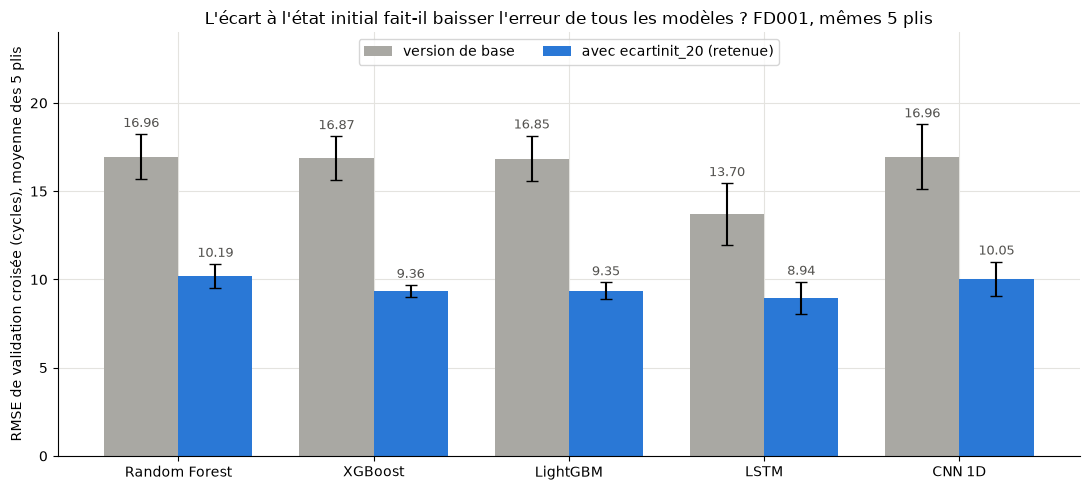

In [62]:
noms_figure = []      # noms des 5 modeles, dans l'ordre des barres
rmse_base = []        # RMSE CV moyen de la version de base
ecart_base = []       # ecart-type entre plis de la version de base
rmse_retenu = []      # RMSE CV moyen de la version avec ecartinit_20
ecart_retenu = []     # ecart-type entre plis de cette version
for cle in ["random_forest", "xgboost_phase3", "lightgbm"]:  # les arbres, lus en F.3
    noms_figure.append(MODELES_RETENUS[cle])
    rmse_base.append(choix_fd001.loc[cle, "rmse_cv_base"])
    ecart_base.append(choix_fd001.loc[cle, "rmse_cv_ecart_type_base"])
    rmse_retenu.append(choix_fd001.loc[cle, "rmse_cv_candidat"])
    ecart_retenu.append(choix_fd001.loc[cle, "rmse_cv_ecart_type_candidat"])
for reseau in ["lstm", "cnn1d"]:  # les reseaux, lus en F.4
    ligne_base = candidats_reseaux[(candidats_reseaux["type_modele"] == reseau) & (candidats_reseaux["candidat"] == "base")].iloc[0]
    ligne_a = candidats_reseaux[(candidats_reseaux["type_modele"] == reseau) & (candidats_reseaux["candidat"] == "A")].iloc[0]
    noms_figure.append(NOMS_RESEAUX[reseau])
    rmse_base.append(ligne_base["rmse_cv_moyen"])
    ecart_base.append(ligne_base["rmse_cv_ecart_type"])
    rmse_retenu.append(ligne_a["rmse_cv_moyen"])
    ecart_retenu.append(ligne_a["rmse_cv_ecart_type"])

positions_f6 = np.arange(len(noms_figure))  # une position par modele
largeur = 0.38  # largeur d'une barre ; les deux barres d'un modele sont cote a cote
fig, ax = plt.subplots(figsize=(11, 5))
ax.bar(positions_f6 - largeur / 2, rmse_base, width=largeur, yerr=ecart_base, capsize=4, color="#a9a8a3",
       label="version de base")
ax.bar(positions_f6 + largeur / 2, rmse_retenu, width=largeur, yerr=ecart_retenu, capsize=4, color=COULEUR_1,
       label="avec ecartinit_20 (retenue)")
for position, valeur, ecart in zip(positions_f6, rmse_retenu, ecart_retenu):  # valeur au-dessus de chaque barre bleue
    ax.text(position + largeur / 2, valeur + ecart + 0.4, f"{valeur:.2f}", ha="center", fontsize=9, color=COULEUR_TEXTE)
for position, valeur, ecart in zip(positions_f6, rmse_base, ecart_base):  # et au-dessus de chaque barre grise
    ax.text(position - largeur / 2, valeur + ecart + 0.4, f"{valeur:.2f}", ha="center", fontsize=9, color=COULEUR_TEXTE)
ax.set_xticks(positions_f6)
ax.set_xticklabels(noms_figure)
ax.set_ylabel("RMSE de validation croisée (cycles), moyenne des 5 plis")
ax.set_ylim(0, 24)  # place pour la legende au-dessus des barres
ax.set_title("L'écart à l'état initial fait-il baisser l'erreur de tous les modèles ? FD001, mêmes 5 plis")
ax.legend(loc="upper center", ncol=2)
plt.tight_layout()
plt.show()

### 7.7 Ce qu'il faut retenir (05, F.8, partie validation)

- **Idée 1 retenue pour les 5 modèles qui apprennent.** RMSE de validation FD001 : Random Forest 16,96 → 10,19 ; XGBoost 16,87 → 9,36 ; LightGBM 16,85 → 9,35 ; LSTM 13,70 → 8,94 ; CNN 1D 16,96 → 10,05. Les deux conditions passent partout : baisse de 4,76 à 7,51 cycles, Wilcoxon p ≤ 2,2e-13, candidat meilleur sur 83 à 87 moteurs sur 100. La référence naïve garde la base (elle n'utilise pas les variables).
- **La prudence ne se dégrade pas, elle s'améliore** : lignes hors-pli surestimées de plus de 20 cycles 2 384 → 754 (XGBoost) et 1 503 → 799 (LSTM) ; alertes manquées hors-pli 552 → 254 (XGBoost) et 298 → 154 (LSTM).
- **Idée 2 non retenue** (7.5).
- Les puces du 05 sur le test officiel (F.7 : FD001 à FD004, alerte sur le CNN 1D de FD004) suivent F.7 dans `evolution`, étape 4 (section 4.7) ; en v2, FD003 et FD004 ont les réseaux du 04h (nuit du 2026-11-07 au 08 ; *mise à jour du 2026-11-08 : ce texte disait avant qu'ils n'en avaient plus*).
- **Limites** : choix fait sur FD001 seulement ; hyperparamètres non réoptimisés pour les nouvelles entrées à ce stade (ils le sont ensuite : sections 9 et 10) ; un seul entraînement par modèle.

**Contrôle des chiffres** : la cellule suivante vérifie que les chiffres cités ci-dessus sont ceux des fichiers relus ; elle s'arrête sur une erreur si un résultat change.

In [63]:
# le texte commun de la regle est bien le meme dans les deux scripts
assert regle_arbres.startswith(decisions_reseaux["regle"])

# F.5 : longueur des trajectoires FD001 (remplissage d'une fenetre de 50 cycles)
longueurs_train = contexte_train["groups"].value_counts()             # cycles par moteur d'entrainement (section 4.3)
longueurs_test = contexte_test["test"].groupby("unit_number").size()   # cycles observes par moteur test (section 4.3)
assert longueurs_train.min() == 128
assert int(np.sum(longueurs_test < 50)) == 7

# idee 1 : RMSE CV base -> retenu, et prudence
rmse_cv_attendus = {"random_forest": (16.96, 10.19), "xgboost_phase3": (16.87, 9.36), "lightgbm": (16.85, 9.35)}
for cle in rmse_cv_attendus:
    assert round(choix_fd001.loc[cle, "rmse_cv_base"], 2) == rmse_cv_attendus[cle][0]
    assert round(choix_fd001.loc[cle, "rmse_cv_candidat"], 2) == rmse_cv_attendus[cle][1]
    assert choix_fd001.loc[cle, "jeu_retenu"] == "ecart_initial_20"
assert choix_fd001.loc["reference_naive", "jeu_retenu"] == "base"
candidats_indexes = candidats_reseaux.set_index(["type_modele", "candidat"])
assert round(candidats_indexes.loc[("lstm", "base"), "rmse_cv_moyen"], 2) == 13.70
assert round(candidats_indexes.loc[("lstm", "A"), "rmse_cv_moyen"], 2) == 8.94
assert round(candidats_indexes.loc[("cnn1d", "base"), "rmse_cv_moyen"], 2) == 16.96
assert round(candidats_indexes.loc[("cnn1d", "A"), "rmse_cv_moyen"], 2) == 10.05
baisses = [choix_fd001.loc["random_forest", "baisse_rmse_cv"], choix_fd001.loc["xgboost_phase3", "baisse_rmse_cv"],
           choix_fd001.loc["lightgbm", "baisse_rmse_cv"], candidats_indexes.loc[("lstm", "A"), "gain_rmse"],
           candidats_indexes.loc[("cnn1d", "A"), "gain_rmse"]]
assert round(min(baisses), 2) == 4.76 and round(max(baisses), 2) == 7.51
p_valeurs = [choix_fd001.loc["random_forest", "p_wilcoxon_bilaterale"], choix_fd001.loc["xgboost_phase3", "p_wilcoxon_bilaterale"],
             choix_fd001.loc["lightgbm", "p_wilcoxon_bilaterale"], candidats_indexes.loc[("lstm", "A"), "p_wilcoxon"],
             candidats_indexes.loc[("cnn1d", "A"), "p_wilcoxon"]]
assert max(p_valeurs) <= 2.2e-13 + 0.05e-13  # arrondi a 2,2e-13
moteurs_meilleurs = [choix_fd001.loc["random_forest", "nb_moteurs_candidat_meilleur"],
                     choix_fd001.loc["xgboost_phase3", "nb_moteurs_candidat_meilleur"],
                     choix_fd001.loc["lightgbm", "nb_moteurs_candidat_meilleur"],
                     candidats_indexes.loc[("lstm", "A"), "nb_moteurs_ameliores"],
                     candidats_indexes.loc[("cnn1d", "A"), "nb_moteurs_ameliores"]]
assert min(moteurs_meilleurs) == 83 and max(moteurs_meilleurs) == 87
assert choix_fd001.loc["xgboost_phase3", "surestimes_oof_base"] == 2384 and choix_fd001.loc["xgboost_phase3", "surestimes_oof_candidat"] == 754
assert candidats_indexes.loc[("lstm", "base"), "surestimes_oof"] == 1503 and candidats_indexes.loc[("lstm", "A"), "surestimes_oof"] == 799
assert choix_fd001.loc["xgboost_phase3", "alertes_manquees_oof_base"] == 552 and choix_fd001.loc["xgboost_phase3", "alertes_manquees_oof_candidat"] == 254
assert candidats_indexes.loc[("lstm", "base"), "alertes_manquees_oof"] == 298 and candidats_indexes.loc[("lstm", "A"), "alertes_manquees_oof"] == 154

# idee 2
assert round(candidats_indexes.loc[("lstm", "B"), "rmse_cv_moyen"], 2) == 11.32
assert round(candidats_indexes.loc[("lstm", "AB"), "rmse_cv_moyen"], 2) == 9.32
assert round(candidats_indexes.loc[("lstm", "AB"), "p_wilcoxon"], 3) == 0.063
assert round(candidats_indexes.loc[("cnn1d", "B"), "gain_rmse"], 2) == 0.89
assert round(candidats_indexes.loc[("cnn1d", "B"), "p_wilcoxon"], 2) == 0.41
assert decisions_reseaux["decisions"]["lstm"]["configuration_retenue"] == "A"
assert decisions_reseaux["decisions"]["cnn1d"]["configuration_retenue"] == "A"

print("Les chiffres cites dans la section 7 sont bien ceux des fichiers de resultats.")

Les chiffres cites dans la section 7 sont bien ceux des fichiers de resultats.


### Décision de la section 7

**Décision : `ecartinit_20` est ajouté aux entrées des 5 modèles qui apprennent** (pour les arbres, il remplace les 46 variables de base par les 31 de la section 6). **Chiffre** : baisse du RMSE de validation de 4,76 (LSTM) à 7,51 cycles (XGBoost), Wilcoxon p ≤ 2,2e-13, sur les mêmes 5 plis (vérifié par le contrôle 7.7). La fenêtre de 50 cycles est rejetée (p = 0,063 pour le LSTM, 0,41 pour le CNN 1D). Le k de l'écart initial des réseaux est ensuite réglé par Optuna (30 sur FD001, section 10).

## 8. Hyperparamètres des arbres : la méthode (Optuna) et la règle de décision

*Repris du notebook `04d_hyperparametres`.* Applique les sections 6 et 8 de [`docs/protocole_evaluation.md`](../docs/protocole_evaluation.md).

**Question** : les réglages actuels (`n_estimators=200, max_depth=5, learning_rate=0.05`) n'ont jamais été cherchés. Une recherche systématique trouve-t-elle des réglages **significativement** meilleurs ?

**Plan** : mêmes données, mêmes 46 features, mêmes plis par moteur que le notebook 03 ; **règle de décision écrite avant tout résultat de recherche** ; recherche Optuna (TPE, graine 42, 60 essais) ; biais d'optimisme ; confirmation sur des **plis neufs** (section 9). Le 04d comparait aussi `GridSearchCV` et `RandomizedSearchCV` à budget égal : cette comparaison ne servait qu'à choisir la méthode de recherche (Optuna converge le plus vite, les trois finissent à moins de 0,02 l'une de l'autre) ; elle est retirée de ce notebook (plan 8.2, une ligne dans `evolution`), ainsi que le test officiel des réglages inchangés.

**Ce qui a fondé la décision (ancien modèle)** : XGBoost Phase 3 à 46 variables. La même méthode, refaite sur les 31 variables, donne les réglages finaux (section 9.2).

In [64]:
import optuna
import scipy
import sklearn
import xgboost
from scipy import stats
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import GroupKFold
from xgboost import XGBRegressor

FENETRE = 5        # fenetre glissante, cf. notebook 03
PLAFOND_RUL = 125  # plafond de la RUL, cf. Phase 2
GRAINE = 42        # graine unique pour tout ce qui est aleatoire dans la recherche

# versions des bibliotheques, a noter dans le rapport (protocole 1.6)
print(f"numpy {np.__version__}, pandas {pd.__version__}, scikit-learn {sklearn.__version__}, "
      f"xgboost {xgboost.__version__}, optuna {optuna.__version__}, scipy {scipy.__version__}")

numpy 2.5.3, pandas 3.0.6, scikit-learn 1.9.1, xgboost 3.4.1, optuna 5.0.0, scipy 1.18.1


In [65]:
# --- Chargement et preparation : identique au notebook 03 (Phases 1 et 2), fait une seule fois dans src/features.py ---
# NB (point de methode signale) : le scaler est ajuste sur TOUT le train, avant les plis, comme dans le
# notebook 03. Sans effet sur XGBoost (la normalisation min-max garde l'ordre des valeurs, les arbres
# ne regardent que l'ordre), mais a refaire dans chaque pli pour un LSTM (protocole 1.3).
contexte_04d = preparer_train(fenetre=FENETRE, plafond=PLAFOND_RUL)  # capteurs constants, min-max, lissage, RUL, features glissantes

# 15 capteurs + 15 moyennes + 15 ecarts-types + time_cycles = 46 features (notebook 03)
feature_cols = contexte_04d["feature_cols"]
X = contexte_04d["X"]
y = contexte_04d["y"]
groups = contexte_04d["groups"]  # sert UNIQUEMENT a regrouper les lignes par moteur dans les plis

assert len(feature_cols) == 46
print(f"X : {X.shape}, y : {y.shape}, moteurs : {groups.nunique()}")

X : (20631, 46), y : (20631,), moteurs : 100


In [66]:
# score_nasa vient de src/evaluation.py (section 3.5) : SOMME des penalites (diviser par le nombre de lignes
# pour la moyenne par prediction). Sanity check identique au notebook 03 :
assert abs(score_nasa([100], [120]) - (np.exp(2) - 1)) < 0.01
assert abs(score_nasa([100], [80]) - (np.exp(20 / 13) - 1)) < 0.01

# --- Plis par moteur, calcules UNE fois (protocole 1.1 et 1.2) : ce sont les "plis de recherche" ---
plis = list(GroupKFold(n_splits=5, shuffle=True, random_state=GRAINE).split(X, y, groups=groups))

for idx_train, idx_val in plis:  # un moteur n'est jamais des deux cotes
    moteurs_train = set(groups.iloc[idx_train])
    moteurs_val = set(groups.iloc[idx_val])
    assert len(moteurs_train & moteurs_val) == 0, "un moteur est present des deux cotes !"
print("Plis de recherche : 5 plis, aucun moteur partage entre train et validation.")

Plis de recherche : 5 plis, aucun moteur partage entre train et validation.


In [67]:
REGLAGES_ACTUELS = {"n_estimators": 200, "max_depth": 5, "learning_rate": 0.05}  # Phase 3, jamais cherches


def evaluer_reglage(params, plis_a_utiliser):
    """
    Evalue un jeu d'hyperparametres XGBoost par validation croisee sur les plis donnes.

    Parameters
    ----------
    params : dict
        Hyperparametres passes a XGBRegressor (random_state=42 est ajoute ici).
    plis_a_utiliser : list de (idx_train, idx_val)
        Les plis par moteur a utiliser (jamais un decoupage aleatoire ligne par ligne).

    Returns
    -------
    dict
        Listes par pli : "rmse", "nasa_moyen" (score NASA moyen par prediction),
        "surestimes_20" (% de lignes surestimees de plus de 20 cycles).
    """
    rmse_plis = []
    nasa_plis = []
    surest_plis = []

    for idx_train, idx_val in plis_a_utiliser:  # un pli a la fois
        modele = XGBRegressor(random_state=GRAINE, n_jobs=NB_COEURS, **params)  # modele neuf a chaque pli (4 coeurs : memes predictions)
        modele.fit(X.iloc[idx_train], y.iloc[idx_train])
        y_val = y.iloc[idx_val].values
        y_pred = modele.predict(X.iloc[idx_val])

        rmse_plis.append(np.sqrt(mean_squared_error(y_val, y_pred)))
        nasa_plis.append(score_nasa(y_val, y_pred) / len(y_val))  # moyenne par prediction
        surest_plis.append(100.0 * np.sum(y_pred - y_val > 20) / len(y_val))  # en %

    return {"rmse": rmse_plis, "nasa_moyen": nasa_plis, "surestimes_20": surest_plis}


debut = time.time()
ref = evaluer_reglage(REGLAGES_ACTUELS, plis)
duree_ref = time.time() - debut

print(f"Reglages actuels : RMSE val = {np.mean(ref['rmse']):.2f} (ecart-type entre plis {np.std(ref['rmse']):.2f})")
print(f"                   score NASA moyen/prediction = {np.mean(ref['nasa_moyen']):.2f}  "
      f"(somme/pli ~ {np.mean(ref['nasa_moyen']) * len(y) / 5:.0f})")
print(f"                   surestimes > 20 cycles = {np.mean(ref['surestimes_20']):.1f} % des lignes")
print(f"Duree d'un essai (5 entrainements) : {duree_ref:.1f} s")

# sanity check : on doit retrouver le RMSE de validation du notebook 03 (16.86, tolerance de reproductibilite XGBoost)
assert abs(np.mean(ref["rmse"]) - 16.86) < 0.05, "ne redonne pas le 16.86 du notebook 03"

Reglages actuels : RMSE val = 16.87 (ecart-type entre plis 1.25)
                   score NASA moyen/prediction = 7.25  (somme/pli ~ 29915)
                   surestimes > 20 cycles = 11.6 % des lignes
Duree d'un essai (5 entrainements) : 1.8 s


## Règle de décision (écrite le 2026-11-04, avant tout résultat de recherche)

**Référence** : réglages actuels `n_estimators=200, max_depth=5, learning_rate=0.05`, RMSE de validation 16.86 sur les plis de recherche (graine 42), score NASA moyen par prédiction 7.24, 11.6 % de lignes surestimées de plus de 20 cycles.

**Budget** : 60 essais par méthode (1 essai = 1 jeu d'hyperparamètres = 5 entraînements, un par pli), donc 300 entraînements par méthode.

**Étape 1 — Choisir un candidat** : parmi les trois méthodes, le candidat est l'essai au **RMSE moyen de validation le plus bas** sur les plis de recherche, parmi les essais dont le score NASA moyen n'est pas plus de 5 % au-dessus de la référence et dont le % de surestimations > 20 cycles n'est pas plus de 5 % (relatif) au-dessus de la référence. Un seul candidat est retenu pour la suite : on ne teste pas plusieurs candidats (sinon la p-value serait gonflée par les tests multiples).

**Étape 2 — Confirmer sur des plis neufs** : les plis de recherche ont servi à choisir, ils sont donc biaisés en faveur du candidat (biais d'optimisme). La confirmation se fait sur **10 découpages par moteur avec des graines jamais utilisées** (1000 à 1009), 5 plis chacun, référence et candidat évalués sur exactement les mêmes plis. On obtient 10 différences de RMSE (une par graine, moyenne des 5 plis).

**Étape 3 — On change les réglages si et seulement si les quatre conditions sont réunies** :
1. gain moyen de RMSE (référence − candidat) **≥ 0,3 cycle** (≈ 2 % du RMSE ; en dessous, la différence n'a pas d'intérêt pratique même si elle est « significative ») ;
2. test t apparié sur les 10 différences : **p < 0,05** ;
3. test de Wilcoxon apparié sur les 10 différences : **p < 0,05** ;
4. le score NASA moyen par prédiction et le % de surestimations > 20 cycles du candidat ne sont pas dégradés de plus de 5 % (relatif) par rapport à la référence, en moyenne sur les plis neufs.

Sinon : **on ne change pas** les réglages. À performance statistiquement équivalente, on garde le modèle le plus simple (règle 9 d'`AGENTS.md`) : si le candidat est équivalent mais plus simple (moins d'arbres, moins profond), on le signale sans le retenir automatiquement.

**Limites assumées** : les 5 plis d'une même graine ne sont pas indépendants (leurs jeux d'entraînement se recouvrent), donc le test porte sur les 10 moyennes par graine, pas sur 50 plis ; ces 10 graines se recoupent aussi (mêmes 100 moteurs) et la p-value reste un peu optimiste. Le test officiel (100 moteurs, un point par moteur) n'est utilisé qu'une fois, après la décision, pour rapporter le modèle retenu.

## Espace de recherche (fixé avant de lancer les recherches)

Budget identique pour les trois méthodes : **60 essais**, soit 300 entraînements chacune.

**Grid search** : grille de 3 hyperparamètres seulement (les trois déjà réglés à la main en Phase 3), 5 × 3 × 4 = 60 combinaisons, tout le reste aux valeurs par défaut de XGBoost. Une grille complète sur 7 hyperparamètres serait hors de portée du budget : c'est précisément la limite de la méthode (protocole §6 : grille pour 1 ou 2 hyperparamètres).

| Hyperparamètre | Grille (grid) | Espace (random search et Optuna) | Pourquoi cette plage |
|---|---|---|---|
| `max_depth` | 2, 3, 4, 5, 6 | entier 2 à 8 | courbe de validation de la Phase 3 : minimum vers 3, sur-apprentissage croissant au-delà de 6 |
| `learning_rate` | 0.02, 0.05, 0.1 | log-uniforme 0.01 à 0.3 | jamais exploré ; échelle logarithmique car 0.01 → 0.02 compte autant que 0.15 → 0.3 |
| `n_estimators` | 100, 200, 300, 400 | entier 50 à 600 | minimum de validation vers 90 arbres à `learning_rate=0.05` ; le bon nombre d'arbres dépend du `learning_rate` |
| `subsample` | défaut (1.0) | 0.5 à 1.0 | fraction de lignes par arbre : régularisation |
| `colsample_bytree` | défaut (1.0) | 0.3 à 1.0 | fraction de features par arbre : régularisation, utile avec 46 features très corrélées |
| `min_child_weight` | défaut (1) | log-uniforme 1 à 30 | taille minimale d'une feuille : limite le sur-apprentissage |
| `reg_lambda` | défaut (1) | log-uniforme 0.1 à 30 | pénalité L2 sur les poids des feuilles |

L'espace de random search et d'Optuna **contient** les valeurs de la grille et les réglages actuels : les trois méthodes cherchent dans le même univers, la grille en explore juste une tranche.

Pour chaque essai on enregistre : RMSE moyen de validation (objectif), score NASA moyen par prédiction, % de surestimations > 20 cycles, durée.

*Dans ce notebook, seule la recherche Optuna est relancée (la grille et le random search sont retirés, voir l'en-tête de la section).*

In [68]:
N_ESSAIS = 60  # budget de la recherche (60 jeux d'hyperparametres, x5 plis) : le meme que dans le 04d

In [69]:
import pickle

# resultats des recherches (longues) : evite de tout relancer si on reouvre le notebook. Le 04d ecrivait dans
# notebooks/.cache_04d ; ici, dans sorties/ (non versionne), pour ne rien ajouter au depot.
DOSSIER_CACHE = os.path.join("..", "sorties", "cache_02_choix_du_modele")
os.makedirs(DOSSIER_CACHE, exist_ok=True)


def charger_ou_calculer(nom, fonction):
    """
    Renvoie le resultat mis en cache s'il existe, sinon le calcule avec `fonction`, le sauvegarde et le renvoie.

    Parameters
    ----------
    nom : str
        Nom du fichier de cache (sans extension).
    fonction : callable
        Fonction sans argument qui calcule le resultat (une recherche, longue).

    Returns
    -------
    object
        Le resultat (ici : un tableau pandas des essais et la duree en secondes).
    """
    chemin = os.path.join(DOSSIER_CACHE, nom + ".pkl")
    if os.path.exists(chemin):  # deja calcule lors d'une execution precedente
        with open(chemin, "rb") as f:
            return pickle.load(f)
    resultat = fonction()  # calcul long
    with open(chemin, "wb") as f:
        pickle.dump(resultat, f)
    return resultat

In [70]:
optuna.logging.set_verbosity(optuna.logging.WARNING)  # pas un message par essai


def objectif(essai):
    """
    Fonction objectif d'Optuna : propose des hyperparametres, renvoie le RMSE moyen de validation.

    Le score NASA moyen et le % de surestimations sont gardes en attributs de l'essai (pas optimises).

    Parameters
    ----------
    essai : optuna.trial.Trial
        L'essai en cours ; c'est lui qui propose les valeurs via suggest_*.

    Returns
    -------
    float
        RMSE moyen sur les 5 plis par moteur (a minimiser).
    """
    params = {
        "max_depth": essai.suggest_int("max_depth", 2, 8),
        "learning_rate": essai.suggest_float("learning_rate", 0.01, 0.3, log=True),
        "n_estimators": essai.suggest_int("n_estimators", 50, 600),
        "subsample": essai.suggest_float("subsample", 0.5, 1.0),
        "colsample_bytree": essai.suggest_float("colsample_bytree", 0.3, 1.0),
        "min_child_weight": essai.suggest_float("min_child_weight", 1, 30, log=True),
        "reg_lambda": essai.suggest_float("reg_lambda", 0.1, 30, log=True),
    }
    resultat = evaluer_reglage(params, plis)  # memes plis par moteur, meme fonction que pour la reference
    essai.set_user_attr("rmse_std", float(np.std(resultat["rmse"])))
    essai.set_user_attr("nasa_moyen", float(np.mean(resultat["nasa_moyen"])))
    essai.set_user_attr("surestimes_20", float(np.mean(resultat["surestimes_20"])))
    return float(np.mean(resultat["rmse"]))


def lancer_optuna():
    """
    Lance l'etude Optuna (TPE, graine 42, 60 essais).

    Returns
    -------
    ((pandas.DataFrame, optuna.study.Study), float)
        Le tableau des essais, l'etude (pour les figures) et la duree totale en secondes.
    """
    debut_optuna = time.time()
    etude = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=GRAINE))
    etude.optimize(objectif, n_trials=N_ESSAIS)

    lignes = []
    for t in etude.trials:  # un essai a la fois, dans l'ordre
        lignes.append({
            "methode": "Optuna",
            "essai": t.number + 1,
            "params": dict(t.params),
            "rmse": t.value,
            "rmse_std": t.user_attrs["rmse_std"],
            "nasa_moyen": t.user_attrs["nasa_moyen"],
            "surestimes_20": t.user_attrs["surestimes_20"],
        })
    return (pd.DataFrame(lignes), etude), time.time() - debut_optuna


(essais_optuna, etude_optuna), duree_optuna = charger_ou_calculer("optuna", lancer_optuna)
print(f"Optuna : {len(essais_optuna)} essais en {duree_optuna / 60:.1f} min")
print(essais_optuna.sort_values("rmse").head(3)[["params", "rmse", "nasa_moyen", "surestimes_20"]].to_string())

Optuna : 60 essais en 2.3 min
                                                                                                                                                                                                                             params       rmse  nasa_moyen  surestimes_20
58    {'max_depth': 2, 'learning_rate': 0.04491529979289121, 'n_estimators': 471, 'subsample': 0.7743091921657816, 'colsample_bytree': 0.9653814798006304, 'min_child_weight': 1.6928790612017364, 'reg_lambda': 7.897286994606383}  16.495028    6.235487      11.407684
57  {'max_depth': 2, 'learning_rate': 0.052622248276052004, 'n_estimators': 485, 'subsample': 0.7979223800562402, 'colsample_bytree': 0.9163769800935531, 'min_child_weight': 2.1691637253655216, 'reg_lambda': 11.924969143097057}  16.501752    6.250368      11.363407
42   {'max_depth': 2, 'learning_rate': 0.035778918674925456, 'n_estimators': 512, 'subsample': 0.5900373863961006, 'colsample_bytree': 0.9692502702557626, 'min_child_weight

In [71]:
DUREES = {"Optuna": duree_optuna}
tous_les_essais = essais_optuna  # 60 essais (le 04d y ajoutait les 60 de Grid et les 60 de Random, retires ici)

# reference : reglages actuels sur les memes plis (cellule de reference ci-dessus)
ref_rmse = float(np.mean(ref["rmse"]))
ref_nasa = float(np.mean(ref["nasa_moyen"]))
ref_surest = float(np.mean(ref["surestimes_20"]))

# --- Meilleur essai en RMSE ---
print(f"Reference (reglages actuels) : RMSE {ref_rmse:.3f} | NASA moyen {ref_nasa:.3f} | surestimes>20 {ref_surest:.2f} %\n")
for methode in ["Optuna"]:
    sous_tableau = tous_les_essais[tous_les_essais["methode"] == methode]
    meilleur = sous_tableau.sort_values("rmse").iloc[0]  # essai au RMSE le plus bas
    print(f"{methode:7s} budget={len(sous_tableau)} essais ({len(sous_tableau) * 5} entrainements), duree={DUREES[methode] / 60:.1f} min")
    print(f"        meilleur RMSE={meilleur['rmse']:.3f} (gain {ref_rmse - meilleur['rmse']:+.3f} vs reference), "
          f"NASA moyen={meilleur['nasa_moyen']:.3f}, surestimes>20={meilleur['surestimes_20']:.2f} %")
    params_arrondis = {}
    for nom_hp, valeur in meilleur["params"].items():  # arrondi pour la lecture
        if isinstance(valeur, float):
            params_arrondis[nom_hp] = round(valeur, 4)
        else:
            params_arrondis[nom_hp] = valeur
    print(f"        params={params_arrondis}\n")

# --- Candidat selon la regle (ecrite avant les resultats) : essais "eligibles" puis RMSE le plus bas ---
eligible = (tous_les_essais["nasa_moyen"] <= 1.05 * ref_nasa) & (tous_les_essais["surestimes_20"] <= 1.05 * ref_surest)
print(f"Essais eligibles (NASA et surestimations pas plus de 5 % au-dessus de la reference) : {int(eligible.sum())} sur {len(tous_les_essais)}")
candidat = tous_les_essais[eligible].sort_values("rmse").iloc[0]
PARAMS_CANDIDAT = dict(candidat["params"])  # un seul candidat est retenu pour la suite
print(f"Candidat : methode={candidat['methode']}, essai {candidat['essai']}, RMSE={candidat['rmse']:.3f}, "
      f"gain sur les plis de recherche = {ref_rmse - candidat['rmse']:+.3f}")
print(PARAMS_CANDIDAT)

# bruit entre plis, pour situer le gain : rappel de l'ecart-type de la reference
print(f"\nEcart-type du RMSE entre plis (reference) : {np.std(ref['rmse']):.2f} -> le gain est {(ref_rmse - candidat['rmse']) / np.std(ref['rmse']):.2f} fois ce bruit")

Reference (reglages actuels) : RMSE 16.867 | NASA moyen 7.250 | surestimes>20 11.62 %

Optuna  budget=60 essais (300 entrainements), duree=2.3 min
        meilleur RMSE=16.495 (gain +0.372 vs reference), NASA moyen=6.235, surestimes>20=11.41 %
        params={'max_depth': 2, 'learning_rate': 0.0449, 'n_estimators': 471, 'subsample': 0.7743, 'colsample_bytree': 0.9654, 'min_child_weight': 1.6929, 'reg_lambda': 7.8973}

Essais eligibles (NASA et surestimations pas plus de 5 % au-dessus de la reference) : 55 sur 60
Candidat : methode=Optuna, essai 59, RMSE=16.495, gain sur les plis de recherche = +0.372
{'max_depth': 2, 'learning_rate': 0.04491529979289121, 'n_estimators': 471, 'subsample': 0.7743091921657816, 'colsample_bytree': 0.9653814798006304, 'min_child_weight': 1.6928790612017364, 'reg_lambda': 7.897286994606383}

Ecart-type du RMSE entre plis (reference) : 1.25 -> le gain est 0.30 fois ce bruit


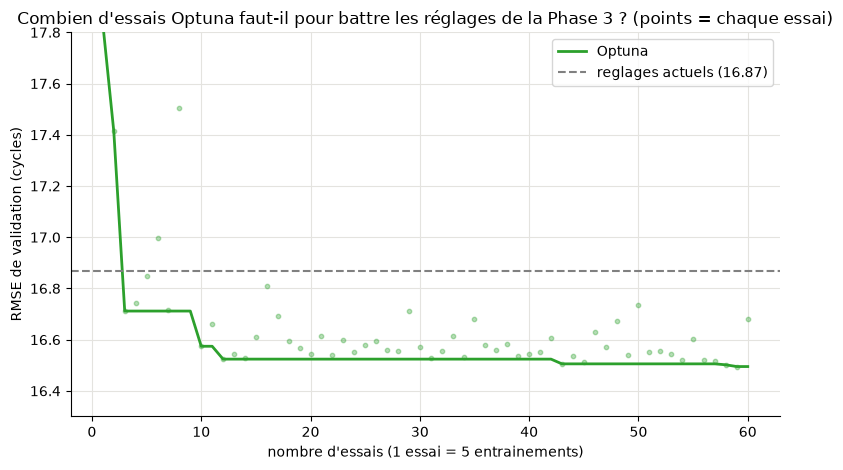

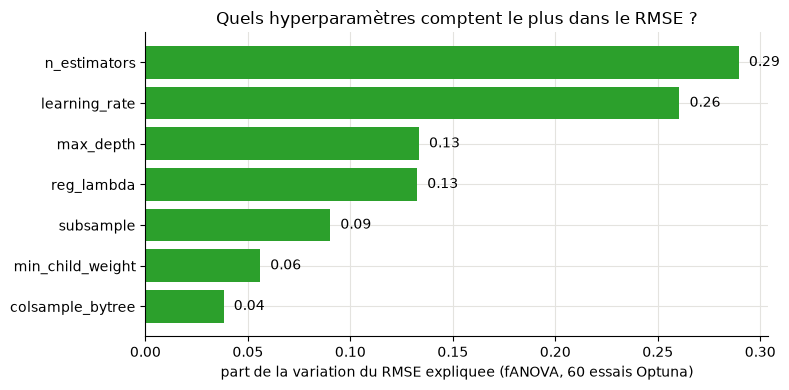

{'n_estimators': 0.289, 'learning_rate': 0.261, 'max_depth': 0.133, 'reg_lambda': 0.133, 'subsample': 0.09, 'min_child_weight': 0.056, 'colsample_bytree': 0.038}


In [72]:
COULEURS = {"Grid": "tab:blue", "Random": "tab:orange", "Optuna": "tab:green"}

# --- Figure 1 : meilleur RMSE atteint apres k essais (combien d'essais faut-il ?) ---
fig, ax = plt.subplots(figsize=(8, 4.8))
for methode in ["Optuna"]:
    sous_tableau = tous_les_essais[tous_les_essais["methode"] == methode].sort_values("essai")
    meilleur_jusqu_ici = []  # meilleur RMSE vu apres chaque essai
    courant = np.inf
    for valeur in sous_tableau["rmse"]:
        if valeur < courant:
            courant = valeur
        meilleur_jusqu_ici.append(courant)
    ax.plot(sous_tableau["essai"], meilleur_jusqu_ici, label=methode, color=COULEURS[methode], linewidth=2)
    ax.scatter(sous_tableau["essai"], sous_tableau["rmse"], s=10, color=COULEURS[methode], alpha=0.35)  # chaque essai
ax.axhline(ref_rmse, linestyle="--", color="grey", label=f"reglages actuels ({ref_rmse:.2f})")
ax.set_ylim(16.3, 17.8)  # on zoome : tout se joue sur quelques dixiemes
ax.set_xlabel("nombre d'essais (1 essai = 5 entrainements)")
ax.set_ylabel("RMSE de validation (cycles)")
ax.set_title("Combien d'essais Optuna faut-il pour battre les réglages de la Phase 3 ? (points = chaque essai)")
ax.legend()
plt.tight_layout()
# (le 04d enregistrait docs/figures/04d_historique_recherche.png, avec les 3 methodes : figure publiee, on ne l'ecrase pas)
plt.show()

# --- Figure 2 : importance des hyperparametres (etude Optuna, methode fANOVA) ---
importances = optuna.importance.get_param_importances(etude_optuna)  # dict nom -> part de la variance du RMSE
noms_hp = list(importances.keys())
valeurs_hp = list(importances.values())
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(noms_hp, valeurs_hp, color="tab:green")
ax.invert_yaxis()  # le plus important en haut
for position, valeur in enumerate(valeurs_hp):
    ax.text(valeur + 0.005, position, f"{valeur:.2f}", va="center")
ax.set_xlabel("part de la variation du RMSE expliquee (fANOVA, 60 essais Optuna)")
ax.set_title("Quels hyperparamètres comptent le plus dans le RMSE ?")
plt.tight_layout()
# (figure publiee dans docs/figures/04d_importance_hyperparametres.png : on ne l'ecrase pas)
plt.show()
importances_arrondies = {}
for nom_hp, valeur in importances.items():  # arrondi pour la lecture
    importances_arrondies[nom_hp] = round(valeur, 3)
print(importances_arrondies)

# (Figure 3 du 04d, RMSE contre score NASA par essai : deplacee dans evolution, etape 5)

## 9. Confirmation sur plis neufs, et réglages finaux des arbres

*Repris du 04d (étape 2 de la règle), puis du 04f et du 04g.* Le plan (5.2) met la confirmation après les réseaux ; elle est placée ici, juste après la recherche qu'elle confirme, parce que les cellules qui suivent réutilisent directement le candidat de la section 8.

### 9.1 Le candidat de la section 8 contre les réglages de la Phase 3 (04d)

Les plis de recherche ont servi à choisir : ils sont biaisés en faveur du candidat (**biais d'optimisme**, le meilleur de 60 essais est trop beau). On compare donc candidat et référence sur **10 découpages par moteur jamais utilisés** (graines 1000 à 1009), mêmes plis pour les deux modèles.

In [73]:
GRAINES_CONFIRMATION = list(range(1000, 1010))  # 10 graines jamais utilisees dans la recherche (qui utilisait 42)


def lancer_confirmation():
    """
    Evalue reference et candidat sur 10 decoupages par moteur neufs (5 plis chacun).

    Pour chaque graine, les DEUX modeles sont evalues sur exactement les memes plis (comparaison appariee).

    Returns
    -------
    dict
        {"reference": [...], "candidat": [...]} : pour chaque graine, le dict renvoye par evaluer_reglage.
    """
    resultats = {"reference": [], "candidat": []}
    for graine in GRAINES_CONFIRMATION:  # un nouveau decoupage par moteur a chaque graine
        plis_neufs = list(GroupKFold(n_splits=5, shuffle=True, random_state=graine).split(X, y, groups=groups))
        for idx_train, idx_val in plis_neufs:  # un moteur n'est jamais des deux cotes
            assert len(set(groups.iloc[idx_train]) & set(groups.iloc[idx_val])) == 0
        resultats["reference"].append(evaluer_reglage(REGLAGES_ACTUELS, plis_neufs))
        resultats["candidat"].append(evaluer_reglage(PARAMS_CANDIDAT, plis_neufs))
    return resultats


confirmation = charger_ou_calculer("confirmation", lancer_confirmation)

# une valeur par graine = moyenne des 5 plis (les 5 plis d'une graine ne sont pas independants : on teste ces 10 moyennes)
def moyennes_par_graine(nom_modele, nom_metrique):
    """
    Moyenne sur les 5 plis de `nom_metrique`, pour chacune des 10 graines.

    Parameters
    ----------
    nom_modele : str
        "reference" ou "candidat".
    nom_metrique : str
        "rmse", "nasa_moyen" ou "surestimes_20".

    Returns
    -------
    numpy.ndarray
        10 valeurs, une par graine.
    """
    valeurs = []
    for resultat_graine in confirmation[nom_modele]:  # une graine a la fois
        valeurs.append(np.mean(resultat_graine[nom_metrique]))
    return np.array(valeurs)


rmse_ref = moyennes_par_graine("reference", "rmse")
rmse_cand = moyennes_par_graine("candidat", "rmse")
nasa_ref = moyennes_par_graine("reference", "nasa_moyen")
nasa_cand = moyennes_par_graine("candidat", "nasa_moyen")
surest_ref = moyennes_par_graine("reference", "surestimes_20")
surest_cand = moyennes_par_graine("candidat", "surestimes_20")

gains = rmse_ref - rmse_cand  # positif = le candidat est meilleur
print("Graine | RMSE reference | RMSE candidat | gain")
for i, graine in enumerate(GRAINES_CONFIRMATION):
    print(f" {graine}  |     {rmse_ref[i]:6.3f}     |    {rmse_cand[i]:6.3f}     | {gains[i]:+.3f}")

print(f"\nPlis de recherche (graine 42, utilises pour CHOISIR) : gain = {ref_rmse - candidat['rmse']:+.3f}")
print(f"Plis neufs (10 graines)                             : gain moyen = {gains.mean():+.3f} (ecart-type entre graines {gains.std(ddof=1):.3f}, "
      f"{int(np.sum(gains > 0))}/10 graines favorables)")
print(f"-> ecart attribuable au biais d'optimisme : {(ref_rmse - candidat['rmse']) - gains.mean():+.3f}")

# --- Tests apparies sur les 10 differences ---
test_t = stats.ttest_rel(rmse_ref, rmse_cand)  # test t apparie
test_w = stats.wilcoxon(rmse_ref, rmse_cand)   # Wilcoxon apparie (sans supposer une loi normale)
print(f"\nTest t apparie : t={test_t.statistic:.2f}, p={test_t.pvalue:.4f}")
print(f"Wilcoxon apparie : statistique={test_w.statistic:.1f}, p={test_w.pvalue:.4f}")

# --- Les 4 conditions de la regle de decision (ecrite avant les resultats) ---
cond_gain = gains.mean() >= 0.3
cond_t = test_t.pvalue < 0.05
cond_w = test_w.pvalue < 0.05
nasa_ok = nasa_cand.mean() <= 1.05 * nasa_ref.mean()
surest_ok = surest_cand.mean() <= 1.05 * surest_ref.mean()
cond_garde_fous = nasa_ok and surest_ok

print(f"\nScore NASA moyen : reference {nasa_ref.mean():.3f}, candidat {nasa_cand.mean():.3f} ({100 * (nasa_cand.mean() / nasa_ref.mean() - 1):+.1f} %)")
print(f"Surestimes > 20 cycles : reference {surest_ref.mean():.2f} %, candidat {surest_cand.mean():.2f} %")
print(f"\n1. gain moyen >= 0.3        : {cond_gain} ({gains.mean():+.3f})")
print(f"2. test t p < 0.05          : {cond_t} (p={test_t.pvalue:.4f})")
print(f"3. Wilcoxon p < 0.05        : {cond_w} (p={test_w.pvalue:.4f})")
print(f"4. garde-fous NASA / surest.: {cond_garde_fous}")
DECISION_CHANGER = cond_gain and cond_t and cond_w and cond_garde_fous
print(f"\n=> DECISION : {'ON CHANGE les reglages' if DECISION_CHANGER else 'ON NE CHANGE PAS les reglages'}")

Graine | RMSE reference | RMSE candidat | gain
 1000  |     16.957     |    16.813     | +0.144
 1001  |     16.657     |    16.606     | +0.052
 1002  |     16.722     |    16.345     | +0.377
 1003  |     16.882     |    16.729     | +0.153
 1004  |     17.094     |    16.651     | +0.443
 1005  |     16.540     |    16.363     | +0.176
 1006  |     16.843     |    16.640     | +0.204
 1007  |     17.041     |    16.728     | +0.312
 1008  |     16.996     |    16.680     | +0.316
 1009  |     17.083     |    16.992     | +0.091

Plis de recherche (graine 42, utilises pour CHOISIR) : gain = +0.372
Plis neufs (10 graines)                             : gain moyen = +0.227 (ecart-type entre graines 0.128, 10/10 graines favorables)
-> ecart attribuable au biais d'optimisme : +0.146

Test t apparie : t=5.58, p=0.0003
Wilcoxon apparie : statistique=0.0, p=0.0020

Score NASA moyen : reference 6.799, candidat 6.320 (-7.0 %)
Surestimes > 20 cycles : reference 11.39 %, candidat 11.46 %

1. gai

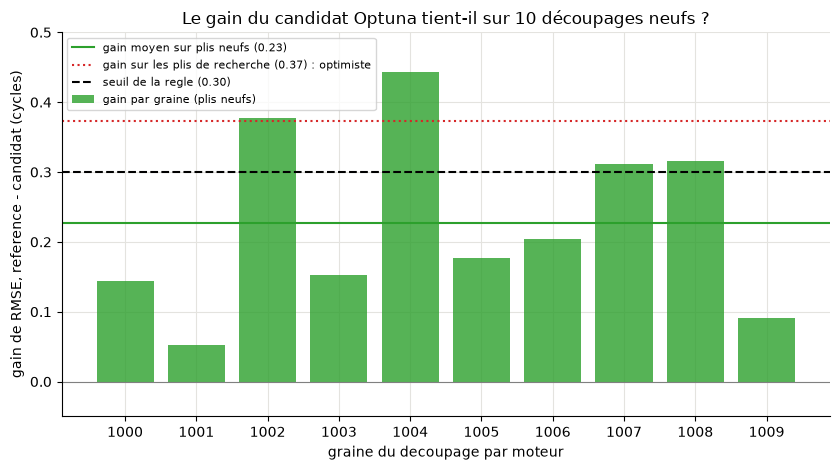

In [74]:
# Figure : gain de RMSE du candidat sur chaque decoupage neuf, compare au seuil de la regle et au gain des plis de recherche
fig, ax = plt.subplots(figsize=(8.5, 4.8))
positions = np.arange(len(GRAINES_CONFIRMATION))
ax.bar(positions, gains, color="tab:green", alpha=0.8, label="gain par graine (plis neufs)")
ax.axhline(gains.mean(), color="tab:green", linestyle="-", label=f"gain moyen sur plis neufs ({gains.mean():.2f})")
ax.axhline(ref_rmse - candidat["rmse"], color="tab:red", linestyle=":", label=f"gain sur les plis de recherche ({ref_rmse - candidat['rmse']:.2f}) : optimiste")
ax.axhline(0.3, color="black", linestyle="--", label="seuil de la regle (0.30)")
ax.axhline(0.0, color="grey", linewidth=0.8)
etiquettes = []
for graine in GRAINES_CONFIRMATION:
    etiquettes.append(str(graine))
ax.set_xticks(positions)
ax.set_xticklabels(etiquettes)
ax.set_xlabel("graine du decoupage par moteur")
ax.set_ylabel("gain de RMSE, reference - candidat (cycles)")
ax.set_title("Le gain du candidat Optuna tient-il sur 10 découpages neufs ?")
ax.set_ylim(-0.05, 0.5)
ax.legend(loc="upper left", fontsize=8)
plt.tight_layout()
# (figure publiee dans docs/figures/04d_confirmation_plis_neufs.png : on ne l'ecrase pas)
plt.show()

### Conclusion du 04d : on ne change pas les réglages (46 variables)

**Décision** : les réglages `n_estimators=200, max_depth=5, learning_rate=0.05` sont conservés.

**Pourquoi**
- La recherche (3 méthodes, 60 essais chacune, plis par moteur) trouve des réglages au RMSE plus bas : 16,50 contre 16,86 sur les plis de recherche (gain 0,36). Les trois méthodes arrivent à moins de 0,02 l'une de l'autre ; Optuna converge le plus vite (≈ 20 essais, contre ≈ 40 pour le random search) *(comparaison retirée de ce notebook, voir l'en-tête de la section 8)*.
- Ce gain est en partie un **biais d'optimisme** : sur 10 découpages par moteur jamais utilisés pour choisir (graines 1000 à 1009), le gain n'est plus que de **0,226 cycle** (10 graines sur 10 favorables ; test t apparié p = 0,0003 ; Wilcoxon p = 0,002). Environ 0,13 du gain apparent venait du choix du meilleur de 180 essais sur les mêmes plis.
- La différence est donc **réelle et significative, mais plus petite que le seuil de 0,3 cycle fixé avant les résultats** (≈ 1,3 % du RMSE, contre un écart-type de 1,25 entre plis). La règle (condition 1) s'applique : on ne remplace pas un modèle validé pour un gain pratiquement négligeable (règle 9 d'`AGENTS.md`).
- Aucun compromis RMSE / score NASA à arbitrer : les deux baissent ensemble (corrélation 0,87 sur 180 essais). Le score NASA moyen du candidat est 7 % plus bas sur les plis neufs, les surestimations de plus de 20 cycles restent stables (11,4 % contre 11,5 %).

**Ce que ça apprend**
- Le plancher d'environ 16,5 de RMSE de validation n'est pas un problème de réglage : une recherche sur 7 hyperparamètres avec trois méthodes différentes ne descend pas dessous. Pour l'abaisser, il faut d'autres features ou d'autres modèles (sections 5 et 7 du protocole), pas d'autres hyperparamètres.
- Hyperparamètre le plus influent : `learning_rate` (importance fANOVA 0,41), puis `max_depth` (0,16), `reg_lambda` (0,14), `n_estimators` (0,12). *Cette exécution donne un autre ordre (`n_estimators` 0,29, `learning_rate` 0,26, `max_depth` et `reg_lambda` 0,13 ; figure 2 de la section 8) : l'importance fANOVA est estimée par une forêt aléatoire sans graine fixée dans le 04d, elle change d'une exécution à l'autre. Le meilleur essai et la confirmation, eux, sont retrouvés (gain +0,227 contre 0,226).*

**Limites**
- Les 10 graines de confirmation réutilisent les mêmes 100 moteurs : la p-value reste un peu optimiste, et le gain ne se transfère pas forcément à d'autres moteurs. Une validation croisée imbriquée serait le niveau au-dessus.
- Espace de recherche limité à 7 hyperparamètres XGBoost ; budget de 60 essais par méthode ; la grille n'en explore que 3.
- Une seule exécution de chaque recherche (graine 42) : le classement entre méthodes (écarts de 0,02) n'est pas significatif.
- Le test officiel (100 moteurs, un point par moteur) n'a servi qu'au modèle retenu ; le candidat n'y a pas été évalué (ce test est retiré de ce notebook, plan 8.2).

*Chiffres de cette exécution : voir les sorties des cellules ci-dessus (la décision est calculée par le code, `DECISION_CHANGER`).*

### 9.2 Les réglages finaux du XGBoost : Optuna refait sur les 31 variables (04f)

*Repris du notebook `04f_modele_final` (cellules 1 et 2 ; ses cellules 3 et 4, test officiel et comparaison 46 contre 31 variables, sont dans `resultats/` et `evolution`).*

- **Features** (section 6) : 31 features, dont l'écart à l'état initial du moteur (calculé sur ses 20 premiers cycles).
- **Hyperparamètres** (section 8) : recherche Optuna refaite sur ces 31 features. Règle écrite avant tout résultat : on change les réglages si le gain de RMSE sur 10 découpages neufs est ≥ 0,3 cycle, avec t apparié et Wilcoxon p < 0,05 et un score NASA non dégradé. *Exception assumée, décidée après coup par l'équipe : le gain est sous 0,3 mais significatif sur 10 graines sur 10, on adopte quand même le candidat.*

Ce sont ces réglages qui sont recopiés dans `src/config_modele.py` (`CONFIG_XGBOOST_FINAL`) et utilisés par la démo ; la fin de la cellule de recherche vérifie si la recherche relancée ici les retrouve (contrôle ajouté par la réorganisation, résultat commenté juste après).

In [75]:
# --- train : capteurs constants retires, min-max, lissage, RUL plafonnee, puis ecart a l'etat initial ---
# Les fonctions ecart_etat_initial et features_31 du 04f sont ecrites une seule fois dans src/features.py
# (ajouter_ecart_etat_initial, construire_liste_features_ecart_initial), et appelees par preparer_train.
from src.features import ajouter_ecart_etat_initial

FENETRE = 5         # fenetre de lissage (Phase 1)
PLAFOND_RUL = 125   # plafond de la RUL (Phase 2)
K_INIT = 20         # cycles servant a definir l'etat initial d'un moteur (04e)
GRAINE = 42
REGLAGES_PHASE3 = {"n_estimators": 200, "max_depth": 5, "learning_rate": 0.05}

contexte_31 = preparer_train(fenetre=FENETRE, plafond=PLAFOND_RUL, ecart_initial=K_INIT)
X31 = contexte_31["X"]  # 15 capteurs lisses, time_cycles, 15 ecarts a l'etat initial (meme ordre que le 04e / 04f)
y = contexte_31["y"]
groups = contexte_31["groups"]
assert X31.shape[1] == 31
plis = list(GroupKFold(n_splits=5, shuffle=True, random_state=GRAINE).split(X31, y, groups=groups))  # 5 plis par moteur

# causalite : la feature d'un cycle ne change pas si on supprime les cycles suivants du moteur
train31 = contexte_31["train"]
capteurs31 = contexte_31["sensor_cols_restants"]
complet, colonnes_ecart = ajouter_ecart_etat_initial(train31, capteurs31, K_INIT)
for cycle_coupe in [10, 25, 60, 100]:
    morceau = train31[(train31["unit_number"] == 1) & (train31["time_cycles"] <= cycle_coupe)]
    derniere_ligne = morceau.index[-1]
    morceau_ecart, _ = ajouter_ecart_etat_initial(morceau, capteurs31, K_INIT)
    assert np.allclose(morceau_ecart.loc[derniere_ligne, colonnes_ecart].values.astype(float),
                       complet.loc[derniere_ligne, colonnes_ecart].values.astype(float)), \
        f"la feature du cycle {cycle_coupe} depend du futur"
print(f"{X31.shape[1]} features (04e) ; causalite verifiee ; 5 plis par moteur.")

31 features (04e) ; causalite verifiee ; 5 plis par moteur.


In [76]:
# --- Hyperparametres : Optuna sur les 31 features, puis confirmation sur 10 decoupages par moteur neufs ---
def nasa_moyen(y_true, y_pred):
    """Score NASA moyen par prediction (score_nasa de src/evaluation.py divise par le nombre de predictions)."""
    return float(score_nasa(y_true, y_pred) / len(y_true))


def evaluer_reglage(params, plis_a_utiliser):
    """
    RMSE et score NASA moyen par pli (31 features) pour un jeu d'hyperparametres XGBoost.

    Parameters
    ----------
    params : dict
        Hyperparametres de XGBRegressor.
    plis_a_utiliser : list de (idx_train, idx_val)
        Plis par moteur.

    Returns
    -------
    dict
        Listes par pli : "rmse" et "nasa_moyen".
    """
    rmse_plis = []
    nasa_plis = []
    for idx_train, idx_val in plis_a_utiliser:
        modele = XGBRegressor(random_state=GRAINE, n_jobs=NB_COEURS, **params)  # modele neuf a chaque pli
        modele.fit(X31.iloc[idx_train], y.iloc[idx_train])
        y_val = y.iloc[idx_val].values
        y_pred = modele.predict(X31.iloc[idx_val])
        rmse_plis.append(np.sqrt(np.mean((y_val - y_pred) ** 2)))
        nasa_plis.append(nasa_moyen(y_val, y_pred))
    return {"rmse": rmse_plis, "nasa_moyen": nasa_plis}


def objectif(essai):
    """Fonction objectif d'Optuna : propose des hyperparametres, renvoie le RMSE moyen de validation."""
    params = {
        "max_depth": essai.suggest_int("max_depth", 2, 8),
        "learning_rate": essai.suggest_float("learning_rate", 0.01, 0.3, log=True),
        "n_estimators": essai.suggest_int("n_estimators", 50, 600),
        "subsample": essai.suggest_float("subsample", 0.5, 1.0),
        "colsample_bytree": essai.suggest_float("colsample_bytree", 0.3, 1.0),
        "min_child_weight": essai.suggest_float("min_child_weight", 1, 30, log=True),
        "reg_lambda": essai.suggest_float("reg_lambda", 0.1, 30, log=True),
    }
    return float(np.mean(evaluer_reglage(params, plis)["rmse"]))


ref = evaluer_reglage(REGLAGES_PHASE3, plis)
optuna.logging.set_verbosity(optuna.logging.WARNING)
debut = time.time()
etude = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=GRAINE))
etude.optimize(objectif, n_trials=60)  # 60 essais = 300 entrainements
REGLAGES_FINAUX = dict(etude.best_trial.params)
print(f"Optuna : 60 essais en {(time.time() - debut) / 60:.1f} min. RMSE plis de recherche : "
      f"{np.mean(ref['rmse']):.3f} (Phase 3) -> {etude.best_value:.3f} (candidat)")

rmse_ref, rmse_cand, nasa_ref, nasa_cand = [], [], [], []
for graine in range(1000, 1010):  # 10 graines jamais utilisees dans la recherche
    plis_neufs = list(GroupKFold(n_splits=5, shuffle=True, random_state=graine).split(X31, y, groups=groups))
    resultat_ref = evaluer_reglage(REGLAGES_PHASE3, plis_neufs)
    resultat_cand = evaluer_reglage(REGLAGES_FINAUX, plis_neufs)  # memes plis pour les deux : comparaison appariee
    rmse_ref.append(np.mean(resultat_ref["rmse"]))
    rmse_cand.append(np.mean(resultat_cand["rmse"]))
    nasa_ref.append(np.mean(resultat_ref["nasa_moyen"]))
    nasa_cand.append(np.mean(resultat_cand["nasa_moyen"]))
gains = np.array(rmse_ref) - np.array(rmse_cand)  # positif = le candidat est meilleur
p_t = stats.ttest_rel(rmse_ref, rmse_cand).pvalue
p_w = stats.wilcoxon(rmse_ref, rmse_cand).pvalue
print(f"Plis neufs : gain moyen {gains.mean():+.3f} cycle ({int(np.sum(gains > 0))}/10 graines), t apparie p={p_t:.4f}, "
      f"Wilcoxon p={p_w:.4f}, NASA moyen {np.mean(nasa_ref):.2f} -> {np.mean(nasa_cand):.2f}")
regle = gains.mean() >= 0.3 and p_t < 0.05 and p_w < 0.05 and np.mean(nasa_cand) <= 1.05 * np.mean(nasa_ref)
verdict = "GARDER"
if regle:
    verdict = "CHANGER"
print(f"Regle ecrite : {verdict} les reglages. Decision de l'equipe : on adopte le candidat.")
reglages_arrondis = {}  # reglages trouves, arrondis a 4 decimales pour l'affichage
for nom in REGLAGES_FINAUX:
    valeur = REGLAGES_FINAUX[nom]
    if isinstance(valeur, float):
        valeur = round(valeur, 4)
    reglages_arrondis[nom] = valeur
print(reglages_arrondis)

# controle (ajoute) : la recherche relancee ici retrouve-t-elle les reglages recopies dans src/config_modele.py ?
identiques = True
for nom_hp in REGLAGES_FINAUX:
    valeur_config = CONFIG_XGBOOST_FINAL["hyperparametres"][nom_hp]  # valeur recopiee (4 decimales)
    valeur_trouvee = REGLAGES_FINAUX[nom_hp]
    if isinstance(valeur_trouvee, float):
        valeur_trouvee = round(valeur_trouvee, 4)
    if valeur_trouvee != valeur_config:
        identiques = False
        print(f"  ecart sur {nom_hp} : recherche {valeur_trouvee}, src/config_modele.py {valeur_config}")
print(f"Reglages trouves identiques a CONFIG_XGBOOST_FINAL (4 decimales) : {identiques}")

Optuna : 60 essais en 1.8 min. RMSE plis de recherche : 9.359 (Phase 3) -> 9.101 (candidat)


Plis neufs : gain moyen +0.205 cycle (10/10 graines), t apparie p=0.0000, Wilcoxon p=0.0020, NASA moyen 1.46 -> 1.40
Regle ecrite : GARDER les reglages. Decision de l'equipe : on adopte le candidat.
{'max_depth': 4, 'learning_rate': 0.0422, 'n_estimators': 369, 'subsample': 0.599, 'colsample_bytree': 0.7435, 'min_child_weight': 1.9312, 'reg_lambda': 10.28}
  ecart sur learning_rate : recherche 0.0422, src/config_modele.py 0.0633
  ecart sur n_estimators : recherche 369, src/config_modele.py 422
  ecart sur subsample : recherche 0.599, src/config_modele.py 0.5789
  ecart sur colsample_bytree : recherche 0.7435, src/config_modele.py 0.8676
  ecart sur min_child_weight : recherche 1.9312, src/config_modele.py 1.3287
  ecart sur reg_lambda : recherche 10.28, src/config_modele.py 29.1205
Reglages trouves identiques a CONFIG_XGBOOST_FINAL (4 decimales) : False


**Contrôle complémentaire (ajouté par la réorganisation).** La cellule précédente compare les réglages trouvés par la recherche relancée ici à ceux recopiés dans `src/config_modele.py` (`CONFIG_XGBOOST_FINAL`, qu'utilise la démo). La cellule suivante évalue `CONFIG_XGBOOST_FINAL` sur **les mêmes 10 découpages neufs**, pour savoir si les réglages de la démo passent la même confirmation, quels que soient ceux que retrouve la recherche.

**Résultat de cette exécution (2026-11-07, 4 cœurs)** : la recherche relancée ici **ne retrouve pas** les réglages de `CONFIG_XGBOOST_FINAL` (6 hyperparamètres sur 7 diffèrent ; seul `max_depth = 4` est identique). Explication probable, **non vérifiée** : avec `subsample` < 1, XGBoost ne construit pas exactement les mêmes arbres selon la machine et le nombre de cœurs (`docs/STATUS.md`, entrée du 2026-11-05 : RMSE test 12,70 / 12,73 / 12,78 selon 16, 1 ou 4 cœurs sur la machine de Matisse), et les versions des bibliothèques peuvent différer (optuna 5.0.0 ici) ; dès qu'un essai diffère, Optuna (TPE) suit un autre chemin. Ce qui compte pour la décision : sur les mêmes 10 découpages neufs, `CONFIG_XGBOOST_FINAL` gagne **+0,229 cycle** sur les réglages de la Phase 3 (10/10 graines, Wilcoxon p = 0,002), autant que le candidat de cette exécution (+0,205) ; l'écart entre les deux (0,024 cycle) est négligeable. La décision de garder `CONFIG_XGBOOST_FINAL` tient, avec la même exception assumée à la règle des 0,3 cycle.

In [77]:
# controle complementaire : les reglages de CONFIG_XGBOOST_FINAL (ceux de la demo), sur les memes 10 decoupages neufs
reglages_config = {}
for nom_hp in REGLAGES_FINAUX:  # memes 7 hyperparametres que la recherche ; random_state est ajoute par evaluer_reglage
    reglages_config[nom_hp] = CONFIG_XGBOOST_FINAL["hyperparametres"][nom_hp]

rmse_config = []
for graine in range(1000, 1010):  # les memes 10 graines que la confirmation ci-dessus
    plis_neufs = list(GroupKFold(n_splits=5, shuffle=True, random_state=graine).split(X31, y, groups=groups))
    rmse_config.append(np.mean(evaluer_reglage(reglages_config, plis_neufs)["rmse"]))

gains_config = np.array(rmse_ref) - np.array(rmse_config)  # positif = CONFIG_XGBOOST_FINAL meilleur que la Phase 3
p_t_config = stats.ttest_rel(rmse_ref, rmse_config).pvalue
p_w_config = stats.wilcoxon(rmse_ref, rmse_config).pvalue
ecarts_config_candidat = np.array(rmse_config) - np.array(rmse_cand)  # positif = le candidat de cette execution est meilleur
print(f"RMSE moyen sur les 10 decoupages neufs : reglages Phase 3 {np.mean(rmse_ref):.3f} | candidat de cette execution "
      f"{np.mean(rmse_cand):.3f} | CONFIG_XGBOOST_FINAL {np.mean(rmse_config):.3f}")
print(f"CONFIG_XGBOOST_FINAL contre Phase 3 : gain {gains_config.mean():+.3f} cycle ({int(np.sum(gains_config > 0))}/10 graines), "
      f"t apparie p={p_t_config:.4f}, Wilcoxon p={p_w_config:.4f}")
print(f"CONFIG_XGBOOST_FINAL contre le candidat de cette execution : ecart moyen {ecarts_config_candidat.mean():+.3f} cycle "
      f"(candidat meilleur sur {int(np.sum(ecarts_config_candidat > 0))}/10 graines)")

RMSE moyen sur les 10 decoupages neufs : reglages Phase 3 9.278 | candidat de cette execution 9.073 | CONFIG_XGBOOST_FINAL 9.049
CONFIG_XGBOOST_FINAL contre Phase 3 : gain +0.229 cycle (10/10 graines), t apparie p=0.0000, Wilcoxon p=0.0020
CONFIG_XGBOOST_FINAL contre le candidat de cette execution : ecart moyen -0.024 cycle (candidat meilleur sur 2/10 graines)


### 9.3 LightGBM et Random Forest : réglés de la même façon, comparés à XGBoost (04g)

*Repris du notebook `04g_comparaison_modeles` (partie validation ; le test officiel des 3 modèles finaux est dans `resultats/FD001.ipynb`, section 4, et dans `evolution`, étape 5 ; la figure « RUL prédite cycle après cycle » sur 4 moteurs test est dans `evolution`, section 5.3 bis).*

Comparaison simple, sur les **mêmes 31 features** que le 04f et les mêmes plis par moteur. Chaque modèle a ses hyperparamètres réglés par Optuna (60 essais pour XGBoost au 04f, 40 pour les deux autres, réglés sur les mêmes plis de recherche). Les réglages sont lus dans `src/config_modele.py` (`CONFIG_*_FINAL`, recopiés à l'identique du 04g). **Limite** : le code des deux recherches de 40 essais (LightGBM, Random Forest) n'est pas dans le 04g ; seuls leurs résultats y sont recopiés. Elles ne peuvent donc pas être relancées depuis ce notebook.

Résultat du 04g : LightGBM fait jeu égal avec XGBoost, Random Forest est nettement moins bon. Aucun ne justifie de changer le modèle final du 04f.

In [78]:
# --- Comparaison : validation sur 5 decoupages par moteur neufs (memes 31 features, X31 et y de la section 9.2) ---
# hyperparametres issus des recherches Optuna (XGBoost : 04f ; LightGBM et Random Forest : 40 essais, TPE graine 42,
# plis du 04f), lus dans src/config_modele.py au lieu d'etre recopies ici ; 4 coeurs au plus (section 1)
MODELES = {
    "XGBoost": construire_fabrique_depuis_config(config_sur_n_coeurs(CONFIG_XGBOOST_FINAL)),
    "LightGBM": construire_fabrique_depuis_config(config_sur_n_coeurs(CONFIG_LIGHTGBM_FINAL)),
    "Random Forest": construire_fabrique_depuis_config(config_sur_n_coeurs(CONFIG_RANDOM_FOREST_FINAL)),
}

# --- validation : memes plis pour les 3 modeles, 5 graines jamais utilisees pour la recherche ---
rmse_val = {}  # nom du modele -> RMSE de validation de chaque decoupage neuf
nasa_val = {}  # nom du modele -> score NASA moyen de chaque decoupage neuf
for nom in MODELES:
    rmse_val[nom] = []
    nasa_val[nom] = []
for graine in range(1000, 1005):
    plis_neufs = list(GroupKFold(n_splits=5, shuffle=True, random_state=graine).split(X31, y, groups=groups))
    for nom, fabrique in MODELES.items():
        erreurs_carre, nasas = [], []
        for idx_train, idx_val in plis_neufs:
            pred = fabrique().fit(X31.iloc[idx_train], y.iloc[idx_train]).predict(X31.iloc[idx_val])
            y_val = y.iloc[idx_val].values
            erreurs_carre.append(np.mean((y_val - pred) ** 2))
            nasas.append(nasa_moyen(y_val, pred))
        rmse_val[nom].append(np.sqrt(np.mean(erreurs_carre)))
        nasa_val[nom].append(np.mean(nasas))

lignes = []
for nom in MODELES:
    ecart_rmse = np.array(rmse_val[nom]) - np.array(rmse_val["XGBoost"])
    lignes.append({
        "modele": nom, "RMSE val": np.mean(rmse_val[nom]), "NASA moy val": np.mean(nasa_val[nom]),
        "ecart RMSE vs XGBoost": ecart_rmse.mean(), "plus bas que XGBoost": f"{int((ecart_rmse < 0).sum())}/5",
    })
pd.set_option("display.width", 250)
print(pd.DataFrame(lignes).round(3).to_string(index=False))

       modele  RMSE val  NASA moy val  ecart RMSE vs XGBoost plus bas que XGBoost
      XGBoost     9.084         1.389                  0.000                  0/5
     LightGBM     9.037         1.386                 -0.047                  5/5
Random Forest     9.853         1.627                  0.768                  0/5


### Décision des sections 8 et 9

1. **Méthode** : Optuna (TPE, graine 42, 60 essais), règle écrite avant les résultats, confirmation sur 10 découpages neufs (section 8).
2. **46 variables (04d)** : on ne change pas les réglages, gain confirmé +0,227 cycle sous le seuil de 0,3 (cellule 9.1).
3. **31 variables (04f)** : réglages Optuna **adoptés** (`CONFIG_XGBOOST_FINAL`) par exception assumée de l'équipe : sur 10 découpages neufs, `CONFIG_XGBOOST_FINAL` gagne +0,229 cycle sur les réglages de la Phase 3, 10/10, Wilcoxon p = 0,002 (contrôle 9.2) ; le seuil de 0,3 n'est pas atteint, et c'est dit. La recherche relancée ici trouve d'autres réglages, de gain équivalent (+0,205) : la recherche du 04f n'est pas reproductible à l'identique sur cette machine.
4. **Modèle à arbres de référence : XGBoost** ; LightGBM fait jeu égal (écart moyen −0,047 cycle, plus bas que XGBoost sur 5/5 découpages neufs, très en dessous du seuil de 0,3 qui justifierait un changement), Random Forest est moins bon (+0,77 cycle) (cellule 9.3). Les trois restent dans la démo, avec leurs réglages finaux.

## 10. Hyperparamètres des réseaux : Optuna sur le LSTM et le CNN 1D, FD001 et FD002

*Repris du notebook `04h_optuna_reseaux` (sections 1 à 6, 10 et 11 ; ses sections 7 et 8, test officiel et évolution, sont dans `evolution`, étape 6 ; sa section 9, littérature, est dans `resultats/FD00X`, section 4.4), avec la section F.4 du 03b (robustesse à la graine).*

**Question.** Le LSTM et le CNN 1D du notebook 03b avaient des réglages fixés à l'avance (2 × 64 unités, fenêtre de 30 cycles, pas de 1e-3…), jamais optimisés. Avec la même méthode que pour les arbres (Optuna au 04d et au 04f, confirmation sur des découpages neufs), peut-on faire mieux, et sur chaque sous-jeu séparément ?

**Réponse courte.**

- **FD001** : oui, nettement. En validation (3 découpages par moteur jamais utilisés pour choisir), le LSTM passe de 9,34 à 7,85 et le CNN 1D de 9,60 à 8,30. Le modèle retenu est la moyenne de **5 LSTM** (5 graines) : test officiel **11,16** contre la RUL brute (10,09 contre la RUL plafonnée à 125), contre 12,29 pour le LSTM du 03b et 12,73 pour le XGBoost final.
- **FD002** : oui pour le LSTM (10,28 → 9,90 en validation), non pour le CNN 1D (gain non confirmé, il garde les réglages du 03b). Modèle retenu : 5 LSTM, test 22,38 brut, 10,62 plafonné.
- **FD003 et FD004** (nuit du 2026-11-07 au 08, même code et mêmes règles) : sur FD003, les deux candidats Optuna passent la confirmation ; sur FD004, aucun (les deux réseaux gardent les réglages du 03b). Sur les deux, le modèle retenu est l'ensemble de 5 LSTM. Chiffres : `evolution`, étape 6, et `resultats/FD003`, `resultats/FD004`.

**Cette section ne relance aucun calcul.** Il relit les résultats du calcul de nuit du 2026-11-07 (`bash scripts/nuit_04h.sh`, environ 12 h sur tout le processeur), copiés et versionnés dans `docs/resultats/04h/`. Le code qui les a produits : `src/optimisation_reseaux.py` et `scripts/optimiser_reseaux.py`. Les réglages retenus sont recopiés dans `src/optimisation_reseaux.py` (`CONFIGS_RESEAUX_RETENUES`), pour réentraîner sans relancer Optuna.

Plan : 10.1 le protocole ; 10.2 la recherche Optuna ; 10.3 quels réglages comptent ; 10.4 la confirmation sur des découpages neufs ; 10.5 l'ablation des entrées ; 10.6 la robustesse à la graine et les ensembles ; 10.7 où sont les réglages ; 10.8 les limites. **Les tableaux et figures de cette section portent sur FD001 et FD002**, la décision telle qu'elle a été prise le 2026-11-07. FD003 et FD004 ont été traités la nuit suivante, avec le même code et les mêmes règles : leur verdict est relu dans la cellule de contrôle de 10.7. *Mise à jour du 2026-11-08 : ce paragraphe disait avant « En v2, FD003 et FD004 n'ont pas de réseau (journal du plan, 2026-11-07) », et la puce FD003 / FD004 ci-dessus décrivait la v1 (« pas de recherche propre ; ils gardent les réglages de FD001 du 03b »).*

In [79]:
import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd

# src.config_modele charge xgboost avant torch (ordre voulu, voir src/deep_learning.py)
from src.config_modele import CONFIG_XGBOOST_FINAL
from src import optimisation_reseaux as opt

DOSSIER = os.path.join("..", "docs", "resultats", "04h")  # copie versionnee des resultats de la nuit
# sous-jeux montres dans les tableaux et figures de la section 10 : ceux de la decision du 2026-11-07
PREFIXES = {"FD001": "04h_", "FD002": "04h_fd002_"}  # debut des noms de fichiers de chaque sous-jeu
# les 4 sous-jeux (FD003 et FD004 : nuit du 2026-11-07 au 08), pour relire leurs fichiers en 10.7
PREFIXES_TOUS = {"FD001": "04h_", "FD002": "04h_fd002_", "FD003": "04h_fd003_", "FD004": "04h_fd004_"}
RESEAUX = {"lstm": "LSTM", "cnn1d": "CNN 1D"}  # nom de code -> nom affiche
DECOUPAGES_NEUFS = ["1000", "1001", "1002"]  # graines des 3 decoupages jamais utilises pour choisir
COULEURS = {"lstm": "#0072B2", "cnn1d": "#E69F00", "reference": "#999999"}

optuna.logging.set_verbosity(optuna.logging.WARNING)


def lire_json(sous_jeu, nom):
    """Relit un fichier de resultats d'un sous-jeu (ex. lire_json("FD001", "confirmation_lstm"))."""
    chemin = os.path.join(DOSSIER, PREFIXES_TOUS[sous_jeu] + nom + ".json")  # FD001 a FD004
    with open(chemin, encoding="utf-8") as fichier:
        return json.load(fichier)


def moyenne_neufs(resume_cv):
    """RMSE de validation moyen sur les 3 decoupages neufs (resume_cv : graine -> {"rmse_cv_moyen", ...})."""
    valeurs = []
    for graine in DECOUPAGES_NEUFS:
        valeurs.append(resume_cv[graine]["rmse_cv_moyen"])
    return float(np.mean(valeurs))


print("fichiers relus depuis docs/resultats/04h :", len(os.listdir(DOSSIER)), "fichiers")  # chemin relatif au depot

fichiers relus depuis docs/resultats/04h : 46 fichiers


### 10.1 Le protocole, écrit avant les calculs

Les règles sont écrites dans le code (`scripts/optimiser_reseaux.py`, `TEXTE_REGLE_*`) **avant** de lancer la recherche, puis recopiées dans chaque fichier de résultats. On les relit ici telles qu'elles ont servi. L'idée, en trois temps :

1. **Chercher** : Optuna essaie des réglages et note chacun par le RMSE moyen de validation croisée (5 plis par moteur, graine 42 : les plis des arbres et du 03b). Un essai clairement mauvais après un pli est abandonné (« élagué ») pour gagner du temps.
2. **Confirmer** : le meilleur essai a été choisi sur ces mêmes plis, donc son score est **optimiste** (il a « gagné » parmi plus de 100 essais, en partie par chance). On le compare donc à la référence du 03b sur **3 découpages neufs**, avec un seuil fixé à l'avance.
3. **Tester une seule fois** : le jeu de test officiel n'intervient dans aucun choix ; il est lu une fois, à la fin, pour les modèles retenus.

In [80]:
# Les regles, telles qu'elles sont enregistrees dans les fichiers de resultats
print("RECHERCHE :", lire_json("FD001", "optuna_lstm")["regle"], "\n")
print("CONFIRMATION :", lire_json("FD001", "confirmation_lstm")["regle"], "\n")
print("ENSEMBLES :", lire_json("FD001", "ensemble")["regle"], "\n")

# FD002 : la regle du changement (chaque sous-jeu a sa propre recherche), enregistree dans l'etude Optuna
stockage = "sqlite:///" + os.path.abspath(os.path.join(DOSSIER, "04h_optuna.db")).replace("\\", "/")
etude_fd002 = optuna.load_study(study_name="04h_fd002_lstm", storage=stockage)
print("SOUS-JEUX :", etude_fd002.user_attrs["regle_sous_jeux"])

RECHERCHE : Recherche : Optuna, echantillonneur TPE (multivarie, graine 42, 12 essais aleatoires d'abord, 'constant liar' pour les travailleurs paralleles), objectif = RMSE moyen de validation sur les 5 plis par moteur du sous-jeu traite (graine 42, les plis des arbres et du 03b), cible plafonnee a 125, toutes les lignes de validation. Elagage : MedianPruner (8 essais complets avant d'elaguer, a partir du 2e pli), compare le RMSE moyen des plis deja faits a la mediane des essais precedents au meme pli. Essai n° 0 = configuration de reference du 03b quand elle est dans l'espace (controle sur FD001 : on doit retrouver 8,94 pour le LSTM). Le meilleur essai n'est PAS retenu directement : choisi sur les memes plis que ceux qui le notent, son RMSE est optimiste ; il passe d'abord l'etape 'confirmer'. Le jeu de test n'intervient pas. 

CONFIRMATION : Le candidat (meilleur essai Optuna, ou meilleure variante d'une etape) remplace la reference si, sur 3 decoupages par moteur NEUFS (graines 1000

SOUS-JEUX : Ecrit le 2026-11-06, avant tout calcul sur FD002 a FD004 : jusqu'ici, les reglages des reseaux choisis sur FD001 etaient appliques tels quels aux autres sous-jeux. Desormais chaque sous-jeu a sa propre etude Optuna, sur ses propres plis par moteur, avec les memes regles (Optuna, confirmation, ablation, ensemble) que FD001. La reference de chaque sous-jeu est la configuration du 03b (celle retenue sur FD001, appliquee telle quelle). Seule difference : k de l'ecart a l'etat initial reste strictement plus petit que le plus court moteur test du sous-jeu (FD002 : 21 cycles, donc k = 20 seulement).


### 10.2 La recherche Optuna

Quatre études : LSTM et CNN 1D, sur FD001 et sur FD002. Espace de recherche (`src/optimisation_reseaux.py`, `config_depuis_essai`) :

- LSTM : taille cachée (32 à 192 unités), 1 à 3 couches, dropout de 0 à 0,5 ;
- CNN 1D : 2 à 4 blocs, 16 à 128 filtres, noyau de 3 à 9 cycles, dropout ;
- pour les deux : pas d'Adam (3e-4 à 5e-3), taille des lots (128, 256, 512), longueur de fenêtre (20 à 50 cycles), et k de l'écart à l'état initial (20, 25 ou 30 sur FD001 ; 20 seulement sur FD002, dont le plus court moteur test n'a que 21 cycles).

Sur FD001, l'essai n° 0 du LSTM est la référence du 03b : on doit y retrouver son RMSE de validation (8,94), ce qui contrôle que le protocole est bien le même.

In [81]:
# Une ligne par etude : nombre d'essais, meilleur RMSE de validation (plis 42), essai qui l'a donne
lignes = []
for sous_jeu in PREFIXES:
    for reseau in RESEAUX:
        resume = lire_json(sous_jeu, "optuna_" + reseau)
        lignes.append({
            "sous-jeu": sous_jeu, "reseau": RESEAUX[reseau],
            "essais lances": resume["nb_essais"], "complets": resume["nb_complets"], "elagues": resume["nb_elagues"],
            "meilleur essai": resume["meilleur_numero"], "meilleur RMSE (plis 42)": round(resume["meilleur_rmse_cv"], 3),
        })
tableau_etudes = pd.DataFrame(lignes)

# controle : l'essai n° 0 du LSTM FD001 est la reference du 03b
essais_lstm_fd001 = pd.read_csv(os.path.join(DOSSIER, "04h_optuna_lstm.csv"))
print("essai n° 0 du LSTM FD001 (reference du 03b) :", round(float(essais_lstm_fd001.loc[0, "value"]), 4), "(03b : 8,9421)")
tableau_etudes

essai n° 0 du LSTM FD001 (reference du 03b) : 8.9421 (03b : 8,9421)


,sous-jeu,reseau,essais lances,complets,elagues,meilleur essai,meilleur RMSE (plis 42)
0,FD001,LSTM,133,107,4,50,7.478
1,FD001,CNN 1D,90,65,17,77,8.075
2,FD002,LSTM,111,40,71,74,9.669
3,FD002,CNN 1D,82,35,47,47,10.288


Les essais « lancés » comprennent aussi des essais interrompus (`FAIL`) : la première nuit, la machine s'est mise en veille, et plusieurs arrêts du calcul en journée ont laissé des essais inachevés. Ils sont exclus de tout : seuls les essais complets ou élagués comptent.

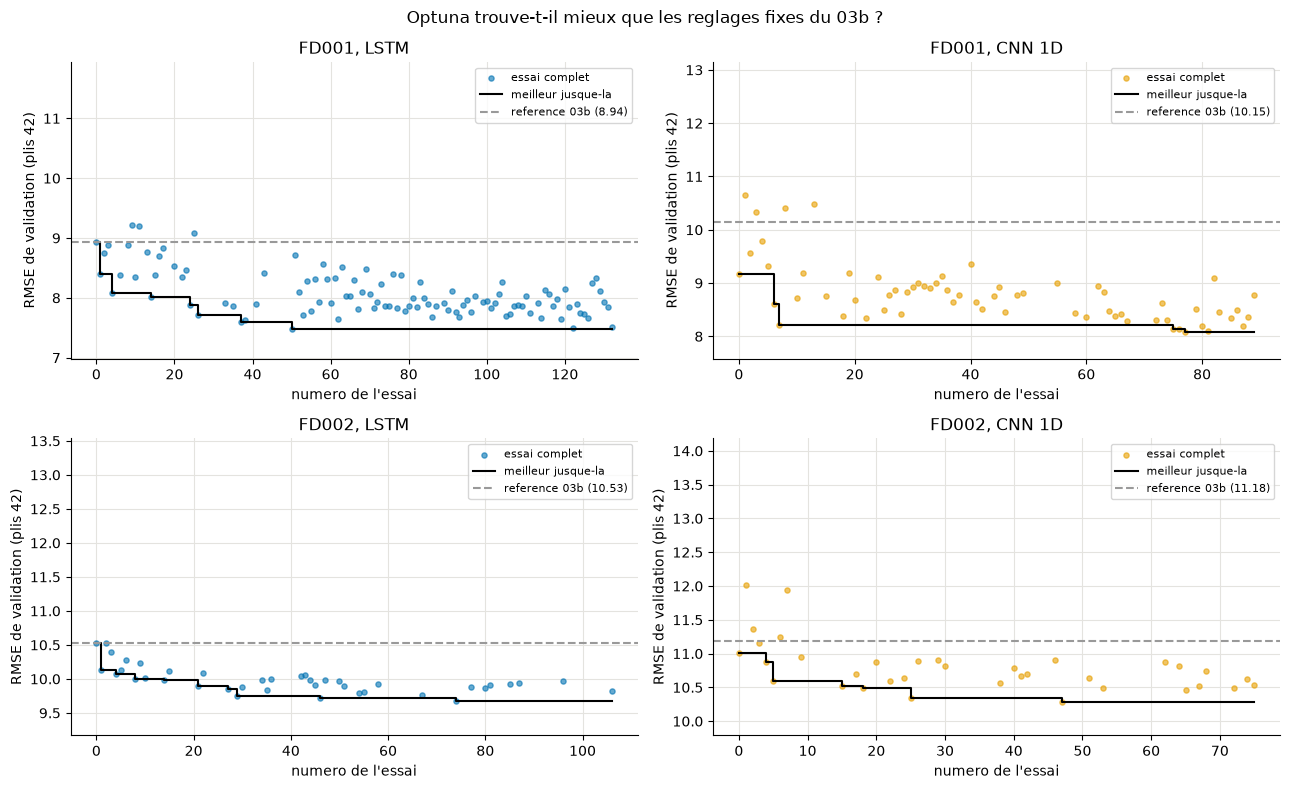

In [82]:
# --- Figure : historique de chaque recherche ---
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for i, sous_jeu in enumerate(PREFIXES):
    for j, reseau in enumerate(RESEAUX):
        ax = axes[i, j]
        essais = pd.read_csv(os.path.join(DOSSIER, PREFIXES[sous_jeu] + "optuna_" + reseau + ".csv"))
        complets = essais[essais["state"] == "COMPLETE"].sort_values("number")
        ax.scatter(complets["number"], complets["value"], s=14, color=COULEURS[reseau], alpha=0.6, label="essai complet")
        meilleur_jusque_la = complets["value"].cummin()  # meilleur RMSE vu jusqu'a cet essai
        ax.step(complets["number"], meilleur_jusque_la, where="post", color="black", label="meilleur jusque-la")
        confirmation = lire_json(sous_jeu, "confirmation_" + reseau)
        reference_42 = confirmation["cv_reference"]["42"]["rmse_cv_moyen"]  # reference du 03b, memes plis
        ax.axhline(reference_42, color=COULEURS["reference"], linestyle="--", label=f"reference 03b ({reference_42:.2f})")
        ax.set_ylim(meilleur_jusque_la.min() - 0.5, reference_42 + 3)
        ax.set_title(f"{sous_jeu}, {RESEAUX[reseau]}")
        ax.set_xlabel("numero de l'essai")
        ax.set_ylabel("RMSE de validation (plis 42)")
        ax.legend(fontsize=8)
fig.suptitle("Optuna trouve-t-il mieux que les reglages fixes du 03b ?")
plt.tight_layout()
plt.show()

**Lecture.** Dans les quatre études, Optuna descend nettement sous la référence du 03b (ligne pointillée). Pour trois d'entre elles, le meilleur score ne s'améliore plus pendant de nombreux essais (dernier record : essai 50 sur 132 pour le LSTM de FD001, 74 sur 110 pour le LSTM de FD002, 47 sur 81 pour le CNN de FD002) : des essais en plus n'apporteraient probablement pas grand-chose. **Le CNN de FD001 fait exception** : son dernier record est à l'essai 77 sur 89, la recherche n'était peut-être pas finie (voir les limites, 10.8). Sur FD002, beaucoup d'essais sont élagués (71 sur 111 pour le LSTM) : l'élagage a abandonné tôt les essais sans espoir, ce qui a rendu la recherche faisable en une nuit. Ces scores sont mesurés sur les plis mêmes qui ont servi à choisir : ils sont optimistes, d'où la section 10.4.

### 10.3 Quels réglages comptent le plus ?

Optuna estime l'importance de chaque réglage (méthode fANOVA : quelle part des écarts de RMSE entre essais s'explique par ce réglage). C'est une indication, pas une preuve : elle dépend des essais qu'Optuna a choisi de faire. Un réglage qui n'a qu'une seule valeur possible (k sur FD002) est exclu.

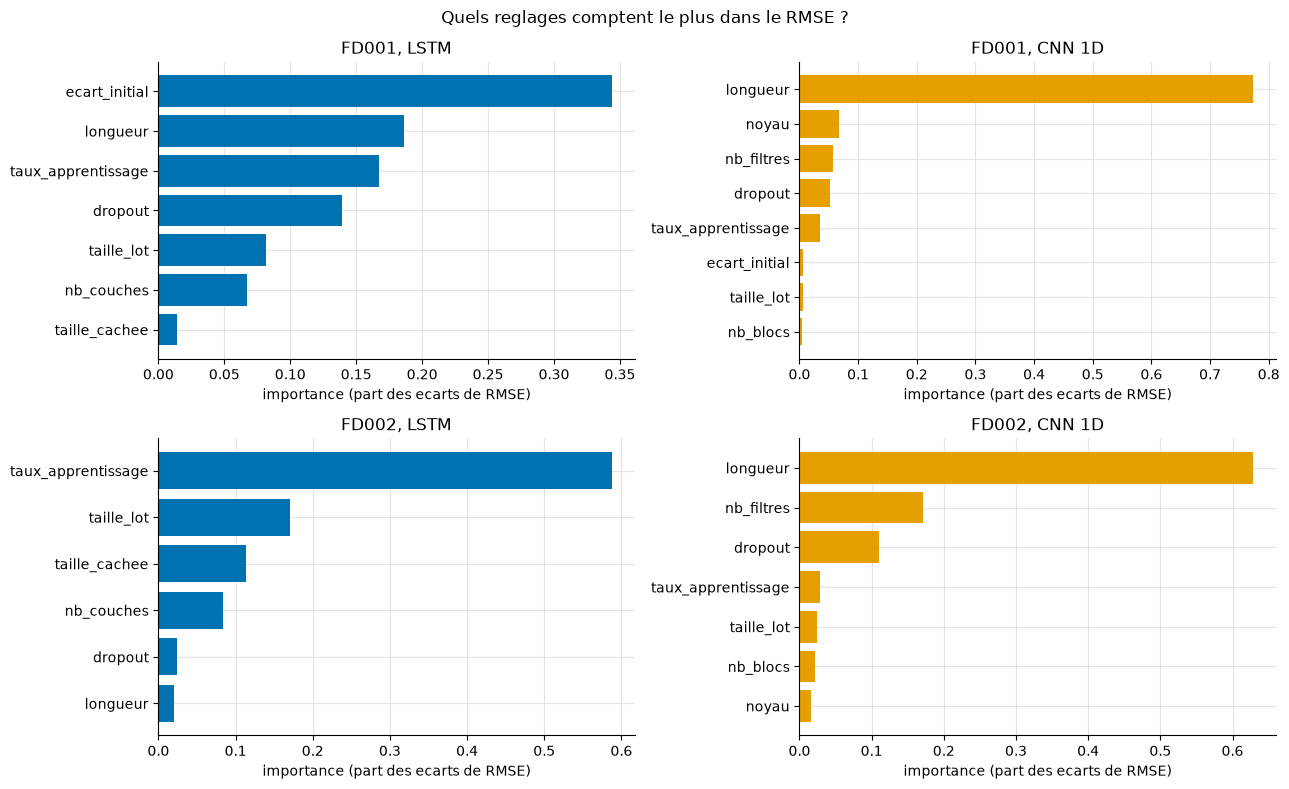

In [83]:
# --- Figure : importance de chaque reglage, pour chaque etude ---
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for i, sous_jeu in enumerate(PREFIXES):
    for j, reseau in enumerate(RESEAUX):
        etude = optuna.load_study(study_name=PREFIXES[sous_jeu] + reseau, storage=stockage)
        complets = etude.trials_dataframe(attrs=("params", "state"))
        complets = complets[complets["state"] == "COMPLETE"]
        reglages = []  # seulement les reglages qui ont pris plusieurs valeurs
        for colonne in complets.columns:
            if colonne.startswith("params_") and complets[colonne].nunique() > 1:
                reglages.append(colonne.replace("params_", ""))
        evaluateur = optuna.importance.FanovaImportanceEvaluator(seed=42)  # graine fixee : resultat reproductible
        importances = optuna.importance.get_param_importances(etude, evaluator=evaluateur, params=reglages)
        noms = list(importances.keys())[::-1]  # le plus important en haut
        valeurs = list(importances.values())[::-1]
        axes[i, j].barh(noms, valeurs, color=COULEURS[reseau])
        axes[i, j].set_title(f"{sous_jeu}, {RESEAUX[reseau]}")
        axes[i, j].set_xlabel("importance (part des ecarts de RMSE)")
fig.suptitle("Quels reglages comptent le plus dans le RMSE ?")
plt.tight_layout()
plt.show()

In [84]:
# Les 5 meilleurs essais de chaque etude : les tendances communes se lisent ici
for sous_jeu in PREFIXES:
    for reseau in RESEAUX:
        essais = pd.read_csv(os.path.join(DOSSIER, PREFIXES[sous_jeu] + "optuna_" + reseau + ".csv"))
        complets = essais[essais["state"] == "COMPLETE"].sort_values("value").head(5)
        colonnes = ["number", "value"]
        for colonne in complets.columns:
            if colonne.startswith("params_"):
                colonnes.append(colonne)
        print(f"--- {sous_jeu}, {RESEAUX[reseau]} : 5 meilleurs essais")
        print(complets[colonnes].round(4).to_string(index=False), "\n")

--- FD001, LSTM : 5 meilleurs essais
 number  value  params_dropout  params_ecart_initial  params_longueur  params_nb_couches  params_taille_cachee  params_taille_lot  params_taux_apprentissage
     50 7.4784          0.1271                    30               20                  2                    32                128                     0.0024
    122 7.4914          0.1456                    30               20                  2                    32                128                     0.0049
    132 7.5182          0.0006                    30               20                  2                    32                128                     0.0006
     37 7.5992          0.0037                    30               20                  3                    32                128                     0.0041
     38 7.6365          0.1451                    30               20                  2                    32                128                     0.0014 

--- FD001, CNN 1D :

**Lecture.**

- **Ce qui compte le plus** : la **longueur de fenêtre** pour le CNN (77 % de l'importance sur FD001, 63 % sur FD002) ; pour le LSTM de FD001, k de l'écart à l'état initial (34 %), puis la longueur (19 %) et le pas d'Adam (17 %) ; pour le LSTM de FD002, le **pas d'Adam** (59 %).
- **Tendances communes aux meilleurs essais** : **fenêtres courtes** (20 cycles au lieu de 30, dans presque tous les 5 meilleurs essais des quatre études) et **réseaux petits** (32 unités ou 32 filtres dans la grande majorité). Pour le LSTM : lots de 128 fenêtres et pas d'Adam de 2 à 5e-3, plus grand que la valeur par défaut (1e-3) ; sur FD001, k = 30 dans les 5 meilleurs essais ; sur FD002, 3 couches dans les 5 meilleurs. Pour le CNN, les lots de 256 dominent.
- Autrement dit, le 03b avait des réseaux plus gros, et des fenêtres plus longues, que nécessaire pour 100 à 260 moteurs d'entraînement.

### 10.4 Le gain tient-il sur des découpages jamais vus ?

Chaque meilleur essai est comparé à la référence du 03b (même réseau, réglages du 03b) sur 3 découpages par moteur **neufs** (graines 1000, 1001, 1002). Il est retenu seulement si les trois critères écrits avant le calcul sont remplis : (a) gain moyen d'au moins 0,3 cycle, (b) meilleur sur les 3 découpages, (c) test de Wilcoxon apparié sur le RMSE par moteur, p < 0,05.

In [85]:
lignes = []
for sous_jeu in PREFIXES:
    for reseau in RESEAUX:
        confirmation = lire_json(sous_jeu, "confirmation_" + reseau)
        comparaison = confirmation["comparaison"]
        gains = []
        for gain in comparaison["gains_par_decoupage"]:
            gains.append(round(gain, 2))
        lignes.append({
            "sous-jeu": sous_jeu, "reseau": RESEAUX[reseau], "essai Optuna": confirmation["essai_optuna"],
            "plis 42 (choix)": round(confirmation["cv_candidat"]["42"]["rmse_cv_moyen"], 3),
            "reference 03b (neufs)": round(moyenne_neufs(confirmation["cv_reference"]), 3),
            "candidat (neufs)": round(moyenne_neufs(confirmation["cv_candidat"]), 3),
            "gains par decoupage": gains, "gain moyen": round(comparaison["gain_moyen"], 3),
            "p Wilcoxon": f"{comparaison['p_wilcoxon']:.1e}",
            "a": comparaison["critere_a"], "b": comparaison["critere_b"], "c": comparaison["critere_c"],
            "RETENU": comparaison["retenu"],
        })
tableau_confirmation = pd.DataFrame(lignes)
tableau_confirmation

,sous-jeu,reseau,essai Optuna,plis 42 (choix),reference 03b (neufs),candidat (neufs),gains par decoupage,gain moyen,p Wilcoxon,a,b,c,RETENU
0,FD001,LSTM,50,7.478,9.335,7.848,"[1.54, 1.28, 1.65]",1.487,9.4e-07,True,True,True,True
1,FD001,CNN 1D,77,8.075,9.600,8.295,"[1.82, 0.96, 1.14]",1.305,1.0e-05,True,True,True,True
2,FD002,LSTM,74,9.669,10.278,9.895,"[0.32, 0.5, 0.32]",0.383,1.6e-03,True,True,True,True
3,FD002,CNN 1D,47,10.288,11.051,10.672,"[0.46, 0.48, 0.19]",0.379,2.5e-01,True,True,False,False


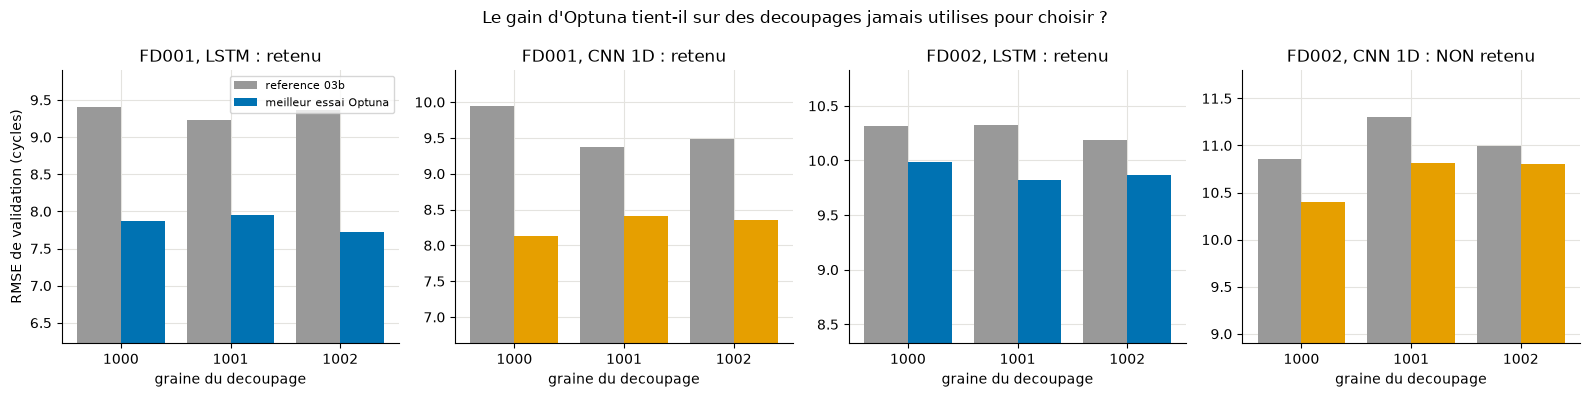

In [86]:
# --- Figure : RMSE de validation sur chaque decoupage neuf, reference contre candidat ---
fig, axes = plt.subplots(1, 4, figsize=(16, 4), sharey=False)
numero = 0
for sous_jeu in PREFIXES:
    for reseau in RESEAUX:
        confirmation = lire_json(sous_jeu, "confirmation_" + reseau)
        reference = []
        candidat = []
        for graine in DECOUPAGES_NEUFS:
            reference.append(confirmation["cv_reference"][graine]["rmse_cv_moyen"])
            candidat.append(confirmation["cv_candidat"][graine]["rmse_cv_moyen"])
        positions = np.arange(len(DECOUPAGES_NEUFS))
        ax = axes[numero]
        ax.bar(positions - 0.2, reference, width=0.4, color=COULEURS["reference"], label="reference 03b")
        ax.bar(positions + 0.2, candidat, width=0.4, color=COULEURS[reseau], label="meilleur essai Optuna")
        ax.set_xticks(positions)
        ax.set_xticklabels(DECOUPAGES_NEUFS)
        ax.set_xlabel("graine du decoupage")
        ax.set_ylim(min(candidat) - 1.5, max(reference) + 0.5)
        statut = "retenu" if confirmation["comparaison"]["retenu"] else "NON retenu"
        ax.set_title(f"{sous_jeu}, {RESEAUX[reseau]} : {statut}")
        numero = numero + 1
axes[0].set_ylabel("RMSE de validation (cycles)")
axes[0].legend(fontsize=8)
fig.suptitle("Le gain d'Optuna tient-il sur des decoupages jamais utilises pour choisir ?")
plt.tight_layout()
plt.show()

**Lecture.**

- Le score des plis 42 (celui qui a servi à choisir) est plus bas que celui des découpages neufs : sur FD001, 7,48 au moment du choix contre 7,85 ensuite pour le LSTM. C'est l'**optimisme** attendu d'un « meilleur parmi 100 essais », et c'est pourquoi on ne garde que les chiffres des découpages neufs.
- **FD001** : les deux réseaux passent largement (gains de 1,3 à 1,5 cycle, meilleurs sur les 3 découpages).
- **FD002, LSTM** : gain plus petit (0,38) mais régulier (0,32 à 0,50) et significatif (p = 0,002) : retenu.
- **FD002, CNN 1D** : même gain moyen (0,38), meilleur sur les 3 découpages mais faiblement sur le troisième (0,19), et surtout le test de Wilcoxon par moteur donne p = 0,25 (critère c non rempli) : **non retenu**, le CNN de FD002 garde les réglages du 03b. La règle ne regarde pas seulement la moyenne : elle demande que le gain soit régulier d'un moteur à l'autre, et pas dû au hasard.

### 10.5 Ablation des entrées (méthode du 04e, section 6)

Sur le LSTM retenu, on change **une famille d'entrées à la fois** et on applique la même règle, sur les mêmes 3 découpages neufs :

- `pente_30`, `pente_50` : on ajoute la pente glissante de chaque capteur sur 30 ou 50 cycles (famille F2, deuxième meilleure famille au 04e) ;
- `sans_capteurs` : on retire les capteurs lissés, il ne reste que les écarts à l'état initial et `time_cycles` (version plus simple : à garder si elle fait aussi bien).

In [87]:
lignes = []
for sous_jeu in PREFIXES:
    ablation = lire_json(sous_jeu, "ablation_lstm")
    base = moyenne_neufs(ablation["cv_base"])
    for nom in ablation["variantes"]:
        variante = ablation["variantes"][nom]
        lignes.append({
            "sous-jeu": sous_jeu, "variante": nom, "LSTM retenu": round(base, 3),
            "variante (neufs)": round(moyenne_neufs(variante["cv"]), 3),
            "gain": round(variante["comparaison"]["gain_moyen"], 3),
            "p Wilcoxon": f"{variante['comparaison']['p_wilcoxon']:.1e}",
            "RETENU": variante["comparaison"]["retenu"],
        })
pd.DataFrame(lignes)

,sous-jeu,variante,LSTM retenu,variante (neufs),gain,p Wilcoxon,RETENU
0,FD001,pente_30,7.848,8.240,-0.393,7.1e-02,False
1,FD001,pente_50,7.848,8.213,-0.365,1.6e-01,False
2,FD001,sans_capteurs,7.848,9.481,-1.633,5.6e-09,False
3,FD002,pente_30,9.895,9.869,0.026,3.6e-01,False
4,FD002,pente_50,9.895,9.759,0.136,3.8e-02,False
5,FD002,sans_capteurs,9.895,11.223,-1.328,1.8e-10,False


**Lecture.** Aucune variante n'est retenue. Ajouter la pente dégrade FD001 (−0,4 cycle) et n'apporte presque rien sur FD002 (+0,03 et +0,14, sous le seuil de 0,3). Retirer les capteurs dégrade nettement les deux sous-jeux (−1,6 et −1,3) : les capteurs lissés apportent une information que l'écart à l'état initial seul ne donne pas. Les entrées du 03b (capteurs lissés + écarts à l'état initial + `time_cycles`) restent donc les bonnes ; seule la valeur de k change (30 sur FD001).

### 10.6 Un réseau dépend-il de sa graine ? (03b, F.4)

Un bon chiffre peut venir d'une graine chanceuse. Pour un réseau, la graine change les poids de départ, l'ordre
des lots et le dropout : on s'attend à une vraie variabilité. XGBoost Phase 3 n'utilise, lui, aucun
tirage aléatoire (ni sous-échantillonnage des lignes, ni des colonnes) : il est évalué une seule fois. Moyenne ± écart-type sur les graines 42, 43 et 44.

**Ce qui a fondé la décision (ancien modèle)** : réseaux du 03b, mesurés au test officiel FD001 sur 3 graines (le test ne sert ici à aucun choix : la décision d'utiliser un ensemble est prise en validation, cellules suivantes). La robustesse des réseaux du 04h (5 graines) est dans `resultats/FD001`.

In [88]:
# resultats du test officiel FD001 des reseaux du 03b, 3 graines (ecrits par scripts/entrainer_deep_learning.py)
test_reseaux = pd.read_csv(os.path.join(DOSSIER_03B, "03b_test_fd001.csv"))

colonnes_graines = ["rmse", "rmse_contre_rul_plafonnee", "mae", "score_nasa", "nb_surestimes", "alertes_manquees", "fausses_alertes"]
resume_graines = test_reseaux.groupby("modele")[colonnes_graines].agg(["mean", "std"])
print(resume_graines.round(2).to_string())
print()
print(f"Pour comparaison : XGBoost Phase 3 RMSE test {resultats_test_xgb['XGBoost Phase 3']['rmse']:.2f}, "
      f"score NASA {resultats_test_xgb['XGBoost Phase 3']['score_nasa']:.1f} (section 5.1).")

         rmse       rmse_contre_rul_plafonnee         mae       score_nasa        nb_surestimes       alertes_manquees       fausses_alertes      
         mean   std                      mean   std  mean   std       mean    std          mean   std             mean   std            mean   std
modele                                                                                                                                            
cnn1d   12.64  0.68                     11.73  0.76  9.12  0.72     256.11  81.57          4.67  5.51             1.33  2.31            1.67  1.15
lstm    12.28  0.25                     11.26  0.43  8.38  0.14     236.31  15.21          3.67  1.53             1.00  0.00            0.67  0.58

Pour comparaison : XGBoost Phase 3 RMSE test 19.70, score NASA 852.9 (section 5.1).


#### Ensembles : faut-il moyenner plusieurs réseaux ? (04h, section 6)

Un réseau dépend de sa graine (poids initiaux, ordre des lots). Moyenner les prédictions de plusieurs réseaux entraînés avec des graines différentes réduit cette part de hasard. Deux ensembles, moyenne simple à poids égaux (rien n'est ajusté), comparés au LSTM retenu seul (graine 42) sur les mêmes 3 découpages neufs :

- `lstm_5_graines` : 5 LSTM, graines 42 à 46 ;
- `lstm_cnn_10` : ces 5 LSTM et 5 CNN 1D.

In [89]:
lignes = []
for sous_jeu in PREFIXES:
    ensembles = lire_json(sous_jeu, "ensemble")
    seul = moyenne_neufs(ensembles["membres"]["lstm_g42"])
    for nom in ensembles["ensembles"]:
        resultat = ensembles["ensembles"][nom]
        lignes.append({
            "sous-jeu": sous_jeu, "ensemble": nom, "LSTM seul (g42)": round(seul, 3),
            "ensemble (neufs)": round(float(np.mean(resultat["rmse_cv_par_decoupage"])), 3),
            "gain": round(resultat["comparaison"]["gain_moyen"], 3),
            "p Wilcoxon": f"{resultat['comparaison']['p_wilcoxon']:.1e}",
            "RETENU contre un seul LSTM": resultat["comparaison"]["retenu"],
        })
tableau_ensembles = pd.DataFrame(lignes)
tableau_ensembles

,sous-jeu,ensemble,LSTM seul (g42),ensemble (neufs),gain,p Wilcoxon,RETENU contre un seul LSTM
0,FD001,lstm_5_graines,7.848,7.375,0.473,3.0e-06,True
1,FD001,lstm_cnn_10,7.848,7.351,0.497,3.3e-06,True
2,FD002,lstm_5_graines,9.895,9.502,0.393,2.6e-13,True
3,FD002,lstm_cnn_10,9.895,9.721,0.175,1.2e-04,False


**Lecture et choix.**

- **FD002** : seul l'ensemble de 5 LSTM passe la règle ; ajouter le CNN (non optimisé sur FD002) le dégrade. Retenu : **5 LSTM**.
- **FD001** : les deux ensembles passent la règle contre un seul LSTM. Entre eux, l'écart de validation est de 0,02 cycle (7,38 contre 7,35), très loin du seuil de 0,3 : rien ne justifie la version à 10 réseaux, plus lourde. On garde la plus simple : **5 LSTM**. Ce choix est fait ici, sur la validation, **avant** de regarder le test (section 7 du 04h, dans `resultats/`), où l'ensemble à 10 réseaux se trouve être un peu meilleur : le choisir pour cette raison reviendrait à choisir sur le test.

### 10.7 Où sont les réglages retenus, et comment réentraîner sans Optuna

Les réglages retenus sont recopiés, sans arrondi et commentés, dans `src/optimisation_reseaux.py` : `CONFIGS_RESEAUX_RETENUES` (par sous-jeu et par réseau, avec le nombre d'époques du modèle final) et `ENSEMBLES_RETENUS`. La cellule suivante vérifie qu'ils sont identiques à ceux que le calcul de nuit a réellement utilisés.

Réentraîner un modèle final prend quelques minutes, sans relancer Optuna :

```python
from src import optimisation_reseaux as opt
config = opt.CONFIGS_RESEAUX_RETENUES["FD001"]["lstm"]
predictions = []
for graine in opt.ENSEMBLES_RETENUS["FD001"]["graines"]:
    modele = opt.entrainer_modele_final(config, config["nb_epoques_final"], graine=graine, sous_jeu="FD001")
    predictions.append(opt.predictions_test_dernier_cycle(modele, config, sous_jeu="FD001"))
moyenne = np.mean(np.vstack(predictions), axis=0)  # l'ensemble de 5 LSTM
```

Les poids des réseaux ne sont pas sauvegardés : la démo (`sorties/predictions/`, `models/`) n'utilise pas encore ces réglages. *Mise à jour (2026-11-07) : depuis, les poids des 10 LSTM et des 10 CNN 1D du 04h sont dans `models/04h/` (`scripts/sauvegarder_poids_04h.py`) et la démo utilise ces réseaux (`src/inference.py`, `docs/resultats/04h/README.md`).*

In [90]:
for sous_jeu in opt.CONFIGS_RESEAUX_RETENUES:
    utilisees = lire_json(sous_jeu, "test")["configurations"]  # configurations du calcul de nuit (etape final)
    for reseau in opt.CONFIGS_RESEAUX_RETENUES[sous_jeu]:
        figee = dict(opt.CONFIGS_RESEAUX_RETENUES[sous_jeu][reseau])
        nb_epoques = figee.pop("nb_epoques_final")
        identique = json.loads(json.dumps(figee)) == utilisees[reseau]
        print(f"{sous_jeu}, {RESEAUX[reseau]} : identique au calcul de nuit = {identique}, {nb_epoques} epoques, "
              f"{figee['hyperparametres']}, entrees {figee['entrees']}")
print("ensembles retenus :", opt.ENSEMBLES_RETENUS)

# verdict de la regle de confirmation et validation de l'ensemble, pour les 4 sous-jeux (fichiers du 04h)
validation_ensembles = {}  # sous-jeu -> (LSTM du 03b, ensemble de 5 LSTM), moyennes des 3 decoupages neufs
for sous_jeu in PREFIXES_TOUS:
    verdicts = []
    for reseau in RESEAUX:
        comparaison = lire_json(sous_jeu, "confirmation_" + reseau)["comparaison"]
        if comparaison["retenu"]:
            verdicts.append(f"{RESEAUX[reseau]} Optuna confirme")
        else:
            verdicts.append(f"{RESEAUX[reseau]} : reglages du 03b gardes (gain {comparaison['gain_moyen']:.2f}, "
                            f"p = {comparaison['p_wilcoxon']:.2f})")
    reference = moyenne_neufs(lire_json(sous_jeu, "confirmation_lstm")["cv_reference"])
    ensemble = float(np.mean(lire_json(sous_jeu, "ensemble")["ensembles"]["lstm_5_graines"]["rmse_cv_par_decoupage"]))
    validation_ensembles[sous_jeu] = (reference, ensemble)
    print(f"{sous_jeu} : " + " ; ".join(verdicts) + f" ; validation LSTM du 03b {reference:.2f} -> ensemble de 5 LSTM {ensemble:.2f}")
# controle des chiffres cites dans le tableau de decision (section 14)
assert round(validation_ensembles["FD003"][0], 2) == 8.54 and round(validation_ensembles["FD003"][1], 2) == 7.59
assert round(validation_ensembles["FD004"][0], 2) == 11.11 and round(validation_ensembles["FD004"][1], 2) == 10.74

FD001, LSTM : identique au calcul de nuit = True, 24 epoques, {'taille_cachee': 32, 'nb_couches': 2, 'dropout': 0.1270900300839567}, entrees {'longueur': 20, 'ecart_initial': 30, 'capteurs': True, 'pente': None}
FD001, CNN 1D : identique au calcul de nuit = True, 7 epoques, {'canaux': [32, 32, 32], 'noyaux': [9, 9, 9], 'dropout': 0.053267563809498854}, entrees {'longueur': 20, 'ecart_initial': 30, 'capteurs': True, 'pente': None}
FD002, LSTM : identique au calcul de nuit = True, 14 epoques, {'taille_cachee': 32, 'nb_couches': 3, 'dropout': 0.1514893855830374}, entrees {'longueur': 20, 'ecart_initial': 20, 'capteurs': True, 'pente': None}
FD002, CNN 1D : identique au calcul de nuit = True, 2 epoques, {'canaux': [32, 64, 64], 'noyaux': [5, 5, 3], 'dropout': 0.2}, entrees {'longueur': 30, 'ecart_initial': 20, 'capteurs': True, 'pente': None}
FD003, LSTM : identique au calcul de nuit = True, 14 epoques, {'taille_cachee': 96, 'nb_couches': 2, 'dropout': 0.18087260512166423}, entrees {'longu

### 10.8 Limites

1. **FD003 et FD004 n'ont pas de recherche propre** : en v1, leurs réseaux gardaient les réglages du 03b, choisis sur FD001 ; en v2, ils n'ont pas de réseau (journal du plan, 2026-11-07). C'est une limite à dire au jury ; la méthode et le code (`--sous-jeu FD003`) sont prêts, il manque environ 5 h de calcul pour FD003 et 12 h pour FD004. *Mise à jour (2026-11-08) : levée. La recherche a été faite la nuit du 2026-11-07 au 08 (16 h 12 pour les deux sous-jeux, `docs/resultats/04h/README.md`) : sur FD003, les deux réseaux Optuna sont confirmés ; sur FD004, aucun (réglages du 03b gardés) ; ensemble de 5 LSTM sur les deux (cellule de contrôle de 10.7).*
2. **Une seule recherche par étude.** Optuna lui-même a une part de hasard ; une autre graine de l'échantillonneur aurait pu trouver un autre optimum. La confirmation sur des découpages neufs protège contre un faux gain, pas contre un optimum manqué.
3. **Le test FD001 compte 100 moteurs** : un écart de quelques dixièmes au test (par exemple 11,16 contre 10,97 pour l'ensemble à 10 réseaux) n'est pas significatif. La décision repose sur la validation.
4. **Le RMSE brut de FD002 est dominé par le plafond de 125** (section 7 du 04h) ; améliorer ce chiffre demanderait de changer la cible, pas les réglages des réseaux.
5. **La recherche du CNN de FD001 n'était peut-être pas finie** (dernier record à l'essai 77 sur 89, 10.2) ; quelques dizaines d'essais de plus auraient pu l'améliorer encore.
6. **Le gain au test est plus petit que le gain en validation** (section 8 du 04h) : il faut annoncer le chiffre du test.
7. **Architectures de la littérature** : le code contient un CNN suivi d'un LSTM et un LSTM avec attention (`src/optimisation_reseaux.py`), mais ils n'ont pas été recherchés par Optuna, faute de temps de calcul.
8. **Les poids ne sont pas sauvegardés** et la démo n'utilise pas encore ces réglages (10.7). *Mise à jour : levée depuis, voir 10.7.*

### Décision de la section 10

**Décision : sur FD001 et FD002, le réseau retenu est un ensemble de 5 LSTM** (graines 42 à 46) aux réglages Optuna de `CONFIGS_RESEAUX_RETENUES` (fenêtre de 20 cycles, réseaux de 32 unités). **Chiffres** (validation, 3 découpages neufs, `docs/resultats/04h/`) : FD001, LSTM du 03b 9,34 → LSTM Optuna 7,85 → ensemble 7,38 ; FD002, 10,28 → 9,90 → 9,50 (tableaux 10.4 et 10.6, règle : gain ≥ 0,3, meilleur sur les 3 découpages, Wilcoxon p < 0,05). Le CNN 1D de FD002 n'est pas confirmé (p = 0,25) et garde les réglages du 03b ; l'ensemble LSTM + CNN n'est pas retenu (0,02 cycle de mieux sur FD001, sous le seuil). **FD003 et FD004 : pas de réseau en v2.** *Mise à jour (2026-11-08) : FD003 et FD004 ont maintenant leurs réseaux du 04h, choisis par les mêmes règles : ensemble de 5 LSTM sur les deux ; réglages Optuna confirmés pour les deux réseaux de FD003, pour aucun de FD004 (réglages du 03b gardés). Validation (3 découpages neufs) : FD003, LSTM du 03b 8,54 → ensemble 7,59 ; FD004, 11,11 → 10,74 (contrôle en 10.7).*

## 11. Biais / variance : le modèle sur-apprend-il ou sous-apprend-il ?

*Repris du notebook `03_modelisation`, section 12 (mesure 1). Les courbes de validation `max_depth` et `n_estimators` (mesures 2 et 3) sont dans `evolution`, étape 5 (« avant » Optuna).*

**Ce qui a fondé la décision (ancien modèle)** : XGBoost Phase 3, 46 variables. Le même diagnostic (RMSE train contre validation) pour les modèles retenus est dans `resultats/FD00X`.

Le RMSE de validation (16.86) dit **combien** le modèle se trompe sur des moteurs jamais vus, pas
**pourquoi**. Pour le savoir, on le compare à l'erreur sur les moteurs que le modèle a appris (RMSE train) :

| RMSE train | RMSE validation | Diagnostic | Remède habituel |
|---|---|---|---|
| bas | nettement plus haut | **variance** (sur-apprentissage : appris par cœur) | modèle plus simple, plus de données, régularisation |
| haut | proche du train | **biais** (sous-apprentissage : modèle trop simple) | modèle plus riche, meilleures features |
| bas | proche du train | équilibre | — |

Exemple concret : un élève qui a 19/20 aux exercices déjà corrigés en classe mais 10/20 à l'examen a
appris les corrigés par cœur (variance). Un élève qui a 10/20 aux deux n'a pas compris le cours (biais).

Trois mesures, toutes en validation croisée (le jeu de test officiel n'est **pas** utilisé) :
1. RMSE train vs validation pour chaque pli, aux réglages actuels (calculé en section 3.6) ;
2. une **courbe de validation** : RMSE train et validation quand on fait varier la profondeur des arbres
   (`max_depth`), le réglage qui contrôle le plus directement la complexité du modèle ;
3. la même chose en fonction du nombre d'arbres (`n_estimators`).

(Mesures 2 et 3 : `evolution`, étape 5.)

Ces mesures servent à **diagnostiquer**, pas à changer les réglages ici : l'optimisation des
hyperparamètres est prévue en Phase 4.

Pli | RMSE train | RMSE val | ecart (val - train)
 1  |    11.17   |   15.17  |  +3.99
 2  |    10.56   |   18.79  |  +8.23
 3  |    11.03   |   17.29  |  +6.26
 4  |    11.00   |   15.90  |  +4.90
 5  |    10.95   |   17.19  |  +6.24

Moyenne : train=10.94, val=16.87, ecart=+5.93


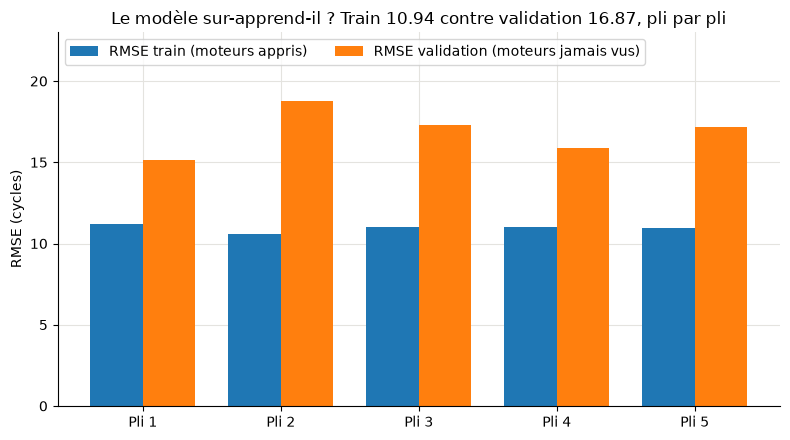

In [91]:
# 1) Ecart train / validation pli par pli, avec les reglages actuels (valeurs calculees en section 3.6)
print("Pli | RMSE train | RMSE val | ecart (val - train)")
for i in range(len(rmse_par_fold)):  # un pli a la fois
    ecart = rmse_par_fold[i] - rmse_train_par_fold[i]  # positif = le modele fait moins bien sur l'inconnu
    print(f" {i + 1}  |   {rmse_train_par_fold[i]:6.2f}   |  {rmse_par_fold[i]:6.2f}  |  {ecart:+.2f}")

rmse_train_moyen = np.mean(rmse_train_par_fold)  # erreur moyenne sur les moteurs appris
rmse_val_moyen = np.mean(rmse_par_fold)          # erreur moyenne sur les moteurs jamais vus
print(f"\nMoyenne : train={rmse_train_moyen:.2f}, val={rmse_val_moyen:.2f}, ecart={rmse_val_moyen - rmse_train_moyen:+.2f}")

# sanity check : un modele evalue sur ses propres donnees d'apprentissage doit faire au moins aussi bien
# que sur des moteurs inconnus. Si ce n'etait pas le cas, il y aurait un bug (mauvais index, mauvaise colonne).
for i in range(len(rmse_par_fold)):
    assert rmse_train_par_fold[i] < rmse_par_fold[i], f"pli {i + 1} : RMSE train >= RMSE val, a verifier"

# visualisation : deux barres par pli (train / validation), pour voir l'ecart d'un coup d'oeil
fig, ax = plt.subplots(figsize=(8, 4.5))
positions = np.arange(len(rmse_par_fold))  # 0, 1, 2, 3, 4 : une position par pli
largeur = 0.38                              # largeur de chaque barre

ax.bar(positions - largeur / 2, rmse_train_par_fold, width=largeur, label="RMSE train (moteurs appris)")
ax.bar(positions + largeur / 2, rmse_par_fold, width=largeur, label="RMSE validation (moteurs jamais vus)")

etiquettes = []
for i in range(len(rmse_par_fold)):
    etiquettes.append(f"Pli {i + 1}")
ax.set_xticks(positions)
ax.set_xticklabels(etiquettes)
ax.set_ylabel("RMSE (cycles)")
ax.set_title(f"Le modèle sur-apprend-il ? Train {rmse_train_moyen:.2f} contre validation {rmse_val_moyen:.2f}, pli par pli")
ax.set_ylim(0, 23)  # marge en haut pour que la legende ne cache aucune barre
ax.legend(loc="upper left", ncol=2)

plt.tight_layout()
# (figure publiee dans docs/figures/03_biais_variance_train_vs_val_par_pli.png, citee par docs/03_modelisation.md : on ne l'ecrase pas)
plt.show()

### Lecture des résultats (03, section 12 ; les courbes citées sont dans `evolution`, étape 5)

**Aux réglages actuels, le modèle sur-apprend un peu** : RMSE train 10.94 contre 16.86 en validation,
soit un écart de 5.9 cycles, présent sur les 5 plis (de +4.0 à +8.2). Les deux courbes de validation le
confirment : quand on augmente la complexité (arbres plus profonds, plus d'arbres), l'erreur train continue
de baisser (jusqu'à 1.84 avec `max_depth=10`) alors que l'erreur de validation remonte légèrement. Le
modèle actuel est donc du côté « variance » du point optimal, pas du côté « biais ».

**Mais ce sur-apprentissage coûte peu en pratique** :
- le meilleur réglage trouvé (`max_depth=3` : 16.55 ; ou 90 arbres : 16.72) ne gagne que 0.1 à 0.3 cycle
  de RMSE de validation, bien moins que le bruit d'un pli à l'autre (écart-type ≈ 1.2) ;
- la courbe de validation est presque plate entre `max_depth=2` et `max_depth=10` (16.55 à 17.32).

**Ce qui limite vraiment le modèle, c'est un plancher autour de 16.5 en validation**, que la complexité
ne fait pas baisser : même le meilleur réglage reste là. Ce plancher vient de ce que les features ne
contiennent pas (biais lié aux features) ou du bruit propre aux données (deux moteurs aux capteurs
semblables peuvent avoir des RUL différentes) — pas d'un modèle trop complexe. Les pistes pour le
dépasser sont donc des features ou des modèles différents (séquences complètes pour un LSTM/CNN 1D), pas
seulement un réglage plus prudent.

**Décision** : les réglages ne sont **pas** modifiés dans ce notebook (gain non significatif, et les
chiffres de la Phase 3 sont déjà validés). Un modèle plus simple (`max_depth=3`, ou moins d'arbres) est
noté comme piste pour l'optimisation des hyperparamètres de la Phase 4, à départager avec un vrai test
statistique.

### Décision de la section 11

**Diagnostic : variance modérée, pas de biais de complexité.** RMSE train 10,94 contre 16,87 en validation (écart +5,93), sur les 5 plis (figure ci-dessus). Le meilleur réglage de complexité ne gagnait que 0,1 à 0,3 cycle (courbes, `evolution`), sous le bruit entre plis (≈ 1,2). **Décision** : chercher le gain dans les variables (section 6 : 16,9 → 9,3) et dans d'autres modèles (sections 5 et 10), puis régler les hyperparamètres avec une règle (sections 8 et 9), plutôt que de rendre le modèle plus prudent à la main.

## 12. Plus de données aideraient-elles ?

*Repris du notebook `04c_diagnostic_apprentissage` (en entier), puis de la section D.5 du 03b (courbes d'apprentissage des réseaux, époque par époque).*

**Ce qui a fondé la décision (anciens modèles)** : XGBoost Phase 3 (46 variables) pour la courbe selon le nombre de moteurs ; réseaux du 03b pour les courbes par époque.

### 12.0 Diagnostic d'apprentissage du XGBoost (FD001)

Application de la **section 5** de [`docs/protocole_evaluation.md`](../docs/protocole_evaluation.md) au modèle XGBoost de la Phase 3
(46 features, `n_estimators=200, max_depth=5, learning_rate=0.05, random_state=42`, plis `GroupKFold(n_splits=5, shuffle=True, random_state=42)`).

**Déjà fait en Phase 3 et non refait ici** (`notebooks/03_modelisation.ipynb` §12-13, `docs/03_modelisation.md` §6-7) :
écart RMSE train / validation (10.94 vs 16.86) et courbes de validation sur `max_depth` et `n_estimators`.
Ici (section 11 de ce notebook pour l'écart train / validation), on retrouve seulement les 10.94 / 16.86 comme contrôle (sanity check), au point « 80 moteurs » de la courbe.

**Une seule question : plus de moteurs d'entraînement aideraient-ils ?**
On y répond par une **courbe d'apprentissage** : l'erreur selon le nombre de moteurs d'entraînement (10, 20, 40, 60, 80), validation toujours sur des moteurs tenus à part, plusieurs tirages par taille.
Elle sert à décider s'il vaut la peine d'ajouter FD003, et donne une procédure réutilisable pour un futur LSTM.

**Règles respectées** : le jeu de test officiel n'est jamais lu dans cette section ; aucun fichier `src/` modifié ; le chargement, les features et le score NASA viennent de `src/` (le 04c les recopiait).

### 12.1 Pourquoi une courbe d'apprentissage ici (rappel court)

Les courbes de validation (Phase 3) font varier la **complexité du modèle** à données fixes. La courbe d'apprentissage fait varier la **quantité de données** à modèle fixe.
Seule elle peut répondre à « plus de moteurs aideraient-ils ? » (FD001 n'a que 100 moteurs ; FD003 en apporte 100 de plus).

| Ce qu'on observe | Lecture |
|---|---|
| l'erreur de validation baisse encore à 80 moteurs | plus de données aideraient |
| l'erreur de validation est déjà plate | la limite vient des features ou du modèle, pas du volume |
| l'écart train / validation reste grand quelle que soit la taille | sur-apprentissage persistant : régulariser |

In [92]:
import sklearn
import xgboost
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import GroupKFold
from xgboost import XGBRegressor

FENETRE = 5         # fenetre glissante, identique au notebook 03
PLAFOND_RUL = 125   # plafond de la RUL, identique au notebook 03

# versions des bibliotheques, a noter dans le rapport (protocole section 1, point 6)
print(f"numpy {np.__version__}, pandas {pd.__version__}, scikit-learn {sklearn.__version__}, xgboost {xgboost.__version__}")

numpy 2.5.3, pandas 3.0.6, scikit-learn 1.9.1, xgboost 3.4.1


### 12.2 Chargement et features (identiques au notebook 03)

On reproduit exactement le pipeline de `03_modelisation.ipynb` (cellules de chargement et de features), avec `preparer_train` de `src/features.py` : mêmes 15 capteurs lissés, mêmes moyennes et écarts-types glissants sur 5 cycles, `time_cycles`, soit **46 features**.
Seul le fichier `train_FD001.txt` est chargé.

In [93]:
# pipeline du notebook 03 (src/features.py) : 15 capteurs lisses, moyennes et ecarts-types glissants sur 5 cycles,
# time_cycles = 46 features. Seul le fichier train_FD001.txt est charge.
contexte_04c = preparer_train(fenetre=FENETRE, plafond=PLAFOND_RUL)

feature_cols = contexte_04c["feature_cols"]
X = contexte_04c["X"]          # 46 features
y = contexte_04c["y"]          # cible plafonnee a 125
groups = contexte_04c["groups"]  # identifiant du moteur, sert uniquement a grouper

assert len(feature_cols) == 46, f"attendu 46 features, trouve {len(feature_cols)}"
assert X.isna().sum().sum() == 0, "il reste des NaN dans les features"
print(f"X : {X.shape}, y : {y.shape}, moteurs : {groups.nunique()}")

X : (20631, 46), y : (20631,), moteurs : 100


### 12.3 Outils de mesure

Quatre métriques, calculées sur le **même jeu** que celui qu'on évalue (train ou validation) :
- **MAE** : erreur absolue moyenne, en cycles ;
- **RMSE** : racine de l'erreur quadratique moyenne, en cycles (standard C-MAPSS) ;
- **R²** : part de la variance de la RUL expliquée (0 = aussi bon que prédire la moyenne) ;
- **score NASA moyen par prédiction** : le score NASA est une *somme* qui dépend du nombre de lignes ; on le divise par ce nombre pour pouvoir comparer des jeux de tailles différentes (protocole §1, point 5). C'est essentiel ici : en courbe d'apprentissage, le nombre de lignes d'entraînement change.

In [94]:
# score_nasa vient de src/evaluation.py (section 3.5) : SOMME des penalites individuelles ; metriques_regression
# (meme module) calcule toutes les metriques du protocole en un appel
from src.evaluation import metriques_regression

def calculer_metriques(y_true, y_pred):
    """
    Calcule les 4 metriques du diagnostic sur un jeu de prediction.

    Parameters
    ----------
    y_true : array-like
        Vraies RUL (plafonnees).
    y_pred : array-like
        RUL predites.

    Returns
    -------
    dict
        Cles "MAE", "RMSE", "R2", "NASA_moyen" (score NASA divise par le nombre de lignes).
    """
    # toutes les metriques du protocole en un appel (src/evaluation.py), au lieu du calcul recopie du 04c
    toutes = metriques_regression(y_true, y_pred)
    resultat = {}
    resultat["MAE"] = toutes["mae"]  # erreur absolue moyenne
    resultat["RMSE"] = toutes["rmse"]  # racine de l'erreur quadratique moyenne
    resultat["R2"] = toutes["r2"]  # coefficient de determination
    resultat["NASA_moyen"] = toutes["nasa_moyen"]  # score NASA divise par le nombre de predictions
    return resultat


# sanity check : cas simple ou le calcul a la main est connu
metriques_test = calculer_metriques([100, 100], [120, 80])  # une surestimation et une sous-estimation de 20
assert abs(metriques_test["MAE"] - 20.0) < 1e-9
assert abs(metriques_test["RMSE"] - 20.0) < 1e-9
nasa_attendu = ((np.exp(2) - 1) + (np.exp(20 / 13) - 1)) / 2
assert abs(metriques_test["NASA_moyen"] - nasa_attendu) < 1e-6
metriques_arrondies = {}  # pour l'affichage seulement
for nom_metrique in metriques_test:
    metriques_arrondies[nom_metrique] = round(float(metriques_test[nom_metrique]), 3)
print("metriques verifiees sur un cas a la main :", metriques_arrondies)


noms_metriques = ["MAE", "RMSE", "R2", "NASA_moyen"]  # ordre des metriques dans les tableaux


def creer_modele():
    """Cree un XGBoost avec les reglages de la Phase 3 (modele tout neuf a chaque appel), sur 4 coeurs au plus."""
    return XGBRegressor(n_estimators=200, max_depth=5, learning_rate=0.05, random_state=42, n_jobs=NB_COEURS)

metriques verifiees sur un cas a la main : {'MAE': 20.0, 'RMSE': 20.0, 'R2': 0.0, 'NASA_moyen': 5.023}


### 12.4 Plis par moteur (fixés une fois)

Mêmes plis que partout (`GroupKFold(5, shuffle=True, random_state=42)`), calculés une fois. Vérification qu'aucun moteur n'est des deux côtés d'un pli.

In [95]:
plis = list(GroupKFold(n_splits=5, shuffle=True, random_state=42).split(X, y, groups=groups))

for i, (idx_train, idx_val) in enumerate(plis):  # un pli a la fois
    moteurs_train = set(groups.iloc[idx_train])
    moteurs_val = set(groups.iloc[idx_val])
    assert len(moteurs_train & moteurs_val) == 0, f"pli {i + 1} : un moteur est des deux cotes"
    assert len(moteurs_train) == 80 and len(moteurs_val) == 20, f"pli {i + 1} : tailles inattendues"
    print(f"Pli {i + 1} : {len(moteurs_train)} moteurs train, {len(moteurs_val)} moteurs validation, {len(idx_val)} lignes de validation")

Pli 1 : 80 moteurs train, 20 moteurs validation, 4070 lignes de validation
Pli 2 : 80 moteurs train, 20 moteurs validation, 4291 lignes de validation
Pli 3 : 80 moteurs train, 20 moteurs validation, 3909 lignes de validation
Pli 4 : 80 moteurs train, 20 moteurs validation, 4070 lignes de validation
Pli 5 : 80 moteurs train, 20 moteurs validation, 4291 lignes de validation


### 12.5 Courbes d'apprentissage par nombre de moteurs d'entraînement

**Protocole** :
- pour chacun des 5 plis, les 20 moteurs de validation sont **tenus à part** et ne sont jamais tirés dans l'entraînement ; le « réservoir » d'entraînement est formé des 80 autres moteurs ;
- tailles testées : 10, 20, 40, 60, 80 moteurs ;
- pour chaque (pli, taille) < 80 : **5 tirages aléatoires** de moteurs dans le réservoir (graine déterministe) ; pour 80, un seul « tirage » (tout le réservoir) ;
- à chaque fois : modèle tout neuf, métriques sur le sous-ensemble d'entraînement (**train**) et sur les 20 moteurs de validation ;
- courbe : moyenne ± écart-type, d'abord par pli (moyenne des tirages d'un même pli), puis sur les 5 plis. L'écart-type est donc celui **entre plis**, comparable à celui du protocole §8.

**Attention à la lecture** : la validation porte toujours sur les mêmes 20 moteurs *pour un pli donné*, donc les tailles sont comparables **pli par pli** (test apparié possible).
Le point à 80 (tout le réservoir) doit redonner les chiffres de la Phase 3 (10.94 / 16.86) : c'est le contrôle de cohérence.

In [96]:
TAILLES = [10, 20, 40, 60, 80]  # nombre de moteurs d'entrainement
NB_TIRAGES = 5                  # tirages aleatoires par (pli, taille) ; 1 seul pour la taille 80 (tout le reservoir)

resultats_lc = []  # une ligne par (pli, taille, tirage)

for i, (idx_train, idx_val) in enumerate(plis):  # un pli a la fois
    moteurs_reservoir = np.array(sorted(set(groups.iloc[idx_train])))  # les 80 moteurs disponibles pour l'entrainement
    X_val_pli = X.iloc[idx_val]
    y_val_pli = y.iloc[idx_val].values

    for j, taille in enumerate(TAILLES):  # une taille a la fois
        if taille == len(moteurs_reservoir):
            nb_tirages_ici = 1  # tout le reservoir : il n'y a rien a tirer
        else:
            nb_tirages_ici = NB_TIRAGES

        for tirage in range(nb_tirages_ici):  # un tirage a la fois
            generateur = np.random.RandomState(1000 * (i + 1) + 10 * j + tirage)  # graine deterministe par cas
            moteurs_tires = generateur.choice(moteurs_reservoir, size=taille, replace=False)  # sans remise

            masque_lignes = groups.iloc[idx_train].isin(moteurs_tires).values  # lignes des moteurs tires, dans le pli
            idx_sous_train = idx_train[masque_lignes]

            # garde-fous : seuls les moteurs tires sont utilises, jamais un moteur de validation
            moteurs_utilises = set(groups.iloc[idx_sous_train])
            assert len(moteurs_utilises) == taille, "mauvais nombre de moteurs d'entrainement"
            assert len(moteurs_utilises & set(groups.iloc[idx_val])) == 0, "un moteur de validation fuit dans l'entrainement"

            modele = creer_modele()  # modele tout neuf
            modele.fit(X.iloc[idx_sous_train], y.iloc[idx_sous_train])

            metriques_train = calculer_metriques(y.iloc[idx_sous_train].values, modele.predict(X.iloc[idx_sous_train]))
            metriques_val = calculer_metriques(y_val_pli, modele.predict(X_val_pli))

            ligne = {"pli": i + 1, "taille": taille, "tirage": tirage, "nb_lignes_train": len(idx_sous_train)}
            for nom_metrique in noms_metriques:
                ligne["train_" + nom_metrique] = metriques_train[nom_metrique]
                ligne["val_" + nom_metrique] = metriques_val[nom_metrique]
            resultats_lc.append(ligne)

    print(f"Pli {i + 1} termine")

lc = pd.DataFrame(resultats_lc)
print(f"{len(lc)} entrainements au total")
assert len(lc) == 5 * (4 * NB_TIRAGES + 1), "nombre d'entrainements inattendu"

# sanity check : a 80 moteurs (tout le reservoir), on doit retrouver les chiffres de la Phase 3
lc_80 = lc[lc["taille"] == 80]
assert abs(lc_80["val_RMSE"].mean() - 16.86) < 0.05, f"RMSE val moyen a 80 moteurs {lc_80['val_RMSE'].mean():.2f} != 16.86"
assert abs(lc_80["train_RMSE"].mean() - 10.94) < 0.05, f"RMSE train moyen a 80 moteurs {lc_80['train_RMSE'].mean():.2f} != 10.94"
print("taille 80 = chiffres de la Phase 3 (10.94 / 16.86) : OK")

Pli 1 termine


Pli 2 termine


Pli 3 termine


Pli 4 termine


Pli 5 termine
105 entrainements au total
taille 80 = chiffres de la Phase 3 (10.94 / 16.86) : OK


In [97]:
# agregation : (1) moyenne des tirages dans chaque pli, (2) moyenne et ecart-type ENTRE plis
par_pli_et_taille = lc.groupby(["taille", "pli"]).mean(numeric_only=True).reset_index()  # moyenne des tirages d'un pli

tableau_lc = []
for taille in TAILLES:
    sous_tableau = par_pli_et_taille[par_pli_et_taille["taille"] == taille]
    ligne = {"nb_moteurs": taille}
    for nom_metrique in noms_metriques:
        ligne["train_" + nom_metrique + "_moy"] = sous_tableau["train_" + nom_metrique].mean()
        ligne["train_" + nom_metrique + "_std"] = sous_tableau["train_" + nom_metrique].std(ddof=0)
        ligne["val_" + nom_metrique + "_moy"] = sous_tableau["val_" + nom_metrique].mean()
        ligne["val_" + nom_metrique + "_std"] = sous_tableau["val_" + nom_metrique].std(ddof=0)
    # variabilite due au tirage des moteurs, a pli fixe (0 pour la taille 80, un seul tirage)
    ecarts_tirage = []
    for pli_numero in range(1, 6):
        valeurs_pli = lc[(lc["taille"] == taille) & (lc["pli"] == pli_numero)]["val_RMSE"]
        ecarts_tirage.append(valeurs_pli.std(ddof=0))
    ligne["val_RMSE_std_tirages"] = np.mean(ecarts_tirage)
    tableau_lc.append(ligne)
tableau_lc = pd.DataFrame(tableau_lc)

# affichage lisible : RMSE, MAE, R2, NASA moyen en "moyenne +/- ecart-type entre plis"
print(f"{'moteurs':>7s} | {'RMSE train':>14s} | {'RMSE val':>14s} | {'MAE val':>14s} | {'R2 val':>14s} | {'NASA moy val':>16s} | std tirages (RMSE val)")
for i in range(len(tableau_lc)):
    r = tableau_lc.iloc[i]
    print(f"{int(r['nb_moteurs']):7d} | "
          f"{r['train_RMSE_moy']:6.2f} +/- {r['train_RMSE_std']:4.2f} | "
          f"{r['val_RMSE_moy']:6.2f} +/- {r['val_RMSE_std']:4.2f} | "
          f"{r['val_MAE_moy']:6.2f} +/- {r['val_MAE_std']:4.2f} | "
          f"{r['val_R2_moy']:6.3f} +/- {r['val_R2_std']:5.3f} | "
          f"{r['val_NASA_moyen_moy']:7.2f} +/- {r['val_NASA_moyen_std']:5.2f} | "
          f"{r['val_RMSE_std_tirages']:.2f}")

moteurs |     RMSE train |       RMSE val |        MAE val |         R2 val |     NASA moy val | std tirages (RMSE val)
     10 |   1.99 +/- 0.47 |  21.16 +/- 2.17 |  14.56 +/- 1.89 |  0.738 +/- 0.057 |   16.64 +/-  3.09 | 1.56
     20 |   4.74 +/- 0.52 |  19.71 +/- 2.38 |  13.51 +/- 1.67 |  0.772 +/- 0.058 |   11.56 +/-  2.78 | 1.18
     40 |   8.27 +/- 0.31 |  17.86 +/- 1.75 |  12.34 +/- 1.32 |  0.814 +/- 0.038 |    8.15 +/-  1.60 | 0.53
     60 |   9.87 +/- 0.27 |  17.19 +/- 1.29 |  11.76 +/- 1.01 |  0.828 +/- 0.026 |    8.05 +/-  2.46 | 0.46
     80 |  10.94 +/- 0.21 |  16.87 +/- 1.25 |  11.50 +/- 0.98 |  0.835 +/- 0.025 |    7.25 +/-  1.94 | 0.00


RMSE de la baseline moyenne : 41.69


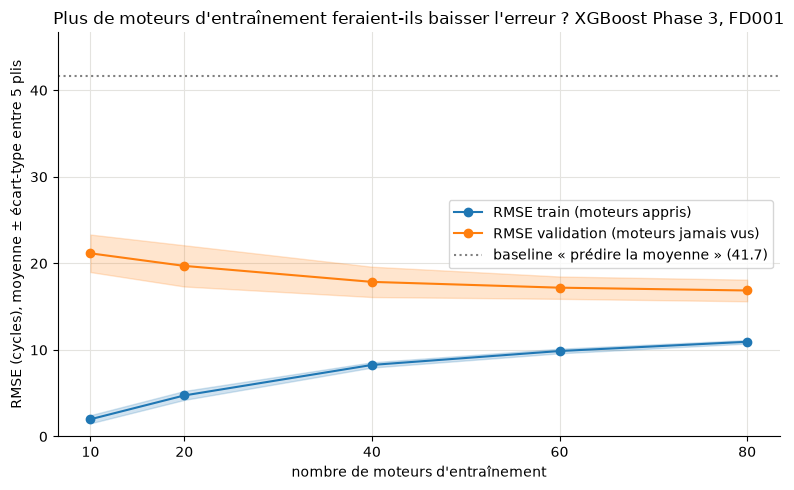

In [98]:
# reference d'echelle : RMSE du modele "bete" qui predit la moyenne du train (meme calcul que notebook 03 section 13)
rmse_baseline_plis = []
for idx_train, idx_val in plis:
    moyenne_train = y.iloc[idx_train].mean()  # moyenne du train du pli, jamais celle de la validation
    rmse_baseline_plis.append(np.sqrt(np.mean((y.iloc[idx_val].values - moyenne_train) ** 2)))
rmse_baseline = np.mean(rmse_baseline_plis)
print(f"RMSE de la baseline moyenne : {rmse_baseline:.2f}")

# figure : courbe d'apprentissage RMSE, moyenne +/- ecart-type entre plis
tailles_x = np.array(tableau_lc["nb_moteurs"])
train_moy = np.array(tableau_lc["train_RMSE_moy"])
train_std = np.array(tableau_lc["train_RMSE_std"])
val_moy = np.array(tableau_lc["val_RMSE_moy"])
val_std = np.array(tableau_lc["val_RMSE_std"])

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(tailles_x, train_moy, marker="o", color="tab:blue", label="RMSE train (moteurs appris)")
ax.fill_between(tailles_x, train_moy - train_std, train_moy + train_std, color="tab:blue", alpha=0.2)
ax.plot(tailles_x, val_moy, marker="o", color="tab:orange", label="RMSE validation (moteurs jamais vus)")
ax.fill_between(tailles_x, val_moy - val_std, val_moy + val_std, color="tab:orange", alpha=0.2)
ax.axhline(rmse_baseline, linestyle=":", color="grey", label=f"baseline « prédire la moyenne » ({rmse_baseline:.1f})")

ax.set_xlabel("nombre de moteurs d'entraînement")
ax.set_ylabel("RMSE (cycles), moyenne ± écart-type entre 5 plis")
ax.set_xticks(TAILLES)
ax.set_ylim(0, rmse_baseline + 5)
ax.set_title("Plus de moteurs d'entraînement feraient-ils baisser l'erreur ? XGBoost Phase 3, FD001")
ax.legend(loc="center right")

plt.tight_layout()
# (figure publiee dans docs/figures/04c_courbe_apprentissage_rmse.png : on ne l'ecrase pas)
plt.show()

### 12.6 Quantifier : la courbe baisse-t-elle encore ?

On compare le **gain de RMSE de validation entre tailles successives** au **bruit entre plis** (écart-type).
Pour le dernier palier (60 → 80), on regarde aussi si le gain va dans le même sens sur les 5 plis : un pli garde les mêmes 20 moteurs de validation à toutes les tailles, donc la comparaison pli par pli est légitime.

Pas de test statistique ni d'extrapolation à 100 / 200 moteurs : avec 5 plis et 5 points de courbe, ils seraient trop fragiles pour peser dans la décision.

In [99]:
# 1) gains entre tailles successives
print("Gain de RMSE validation entre tailles successives (positif = amelioration), a comparer au bruit entre plis :")
for k in range(1, len(TAILLES)):
    gain = val_moy[k - 1] - val_moy[k]
    print(f"  {TAILLES[k - 1]:2d} -> {TAILLES[k]:2d} moteurs : {gain:+.2f}   (ecart-type entre plis a {TAILLES[k]} : {val_std[k]:.2f})")

# 2) dernier palier, pli par pli : le gain va-t-il dans le meme sens partout ?
def rmse_val_par_pli(taille):
    '''RMSE de validation de chaque pli (moyenne des tirages) pour une taille donnee, tries par pli.'''
    sous = par_pli_et_taille[par_pli_et_taille["taille"] == taille].sort_values("pli")
    return sous["val_RMSE"].values

gains_par_pli = rmse_val_par_pli(60) - rmse_val_par_pli(80)  # positif = 80 moteurs font mieux que 60 sur ce pli
nb_plis_en_gain = 0
for gain in gains_par_pli:  # un pli a la fois
    if gain > 0:
        nb_plis_en_gain += 1
print(f"\n60 -> 80 moteurs, gain par pli : {np.round(gains_par_pli, 2)} ({nb_plis_en_gain}/5 plis en amelioration)")

Gain de RMSE validation entre tailles successives (positif = amelioration), a comparer au bruit entre plis :
  10 -> 20 moteurs : +1.45   (ecart-type entre plis a 20 : 2.38)
  20 -> 40 moteurs : +1.85   (ecart-type entre plis a 40 : 1.75)
  40 -> 60 moteurs : +0.67   (ecart-type entre plis a 60 : 1.29)
  60 -> 80 moteurs : +0.32   (ecart-type entre plis a 80 : 1.25)

60 -> 80 moteurs, gain par pli : [0.18 0.3  0.38 0.35 0.41] (5/5 plis en amelioration)


### 12.7 Conclusion chiffrée (04c)

**Ce que montre la courbe** (figure et tableau de la section 12.5) :

| Moteurs d'entraînement | RMSE train | RMSE validation (± écart-type entre plis) | Écart train/val | Gain de validation vs taille précédente |
|---|---|---|---|---|
| 10 | 1.99 | 21.16 (±2.17) | 19.17 | — |
| 20 | 4.74 | 19.71 (±2.38) | 14.97 | +1.45 |
| 40 | 8.27 | 17.86 (±1.75) | 9.59 | +1.85 |
| 60 | 9.87 | 17.19 (±1.29) | 7.32 | +0.67 |
| 80 | 10.94 | 16.86 (±1.25) | 5.92 | +0.33 |

1. **L'erreur de validation baisse encore à 80 moteurs, mais de moins en moins** : −1.85 de 20 à 40 moteurs, −0.67 de 40 à 60, −0.33 de 60 à 80, soit environ 0.017 cycle de RMSE par moteur ajouté sur le dernier palier. Les autres métriques de validation vont dans le même sens (MAE 14.56 → 11.49, R² 0.738 → 0.835).
2. **Ce dernier gain de 0.33 est petit devant le bruit** (écart-type entre plis 1.25), **mais il est de même signe sur les 5 plis** (de +0.18 à +0.45). C'est une indication que la courbe n'est pas tout à fait plate, pas une mesure de ce qu'apporteraient 20 ou 100 moteurs de plus.
3. **L'écart train/validation se réduit** (19.2 → 5.9) parce que le train *monte* (le modèle ne peut plus mémoriser autant de moteurs) et que la validation *descend*. Il reste de **5.9 cycles à 80 moteurs** : un sur-apprentissage résiduel subsiste, qu'une régularisation ou des arbres moins profonds pourraient réduire (piste déjà notée en Phase 3). L'erreur train ne tombe pas à 0 pour autant (RMSE 10.94 sur des moteurs déjà vus) : une part de l'erreur vient d'information absente des features (bruit capteur, variations de fabrication), pas du sur-apprentissage.
**Réponse à « ajouter FD003 aiderait-il ? » : probablement un peu, pas beaucoup.** Le modèle est déjà à 17.86 avec 40 moteurs (la baseline est à 41.69) et la baisse restante se compte en dixièmes de cycle par vingt moteurs, sous le bruit entre plis. **Le plancher d'environ 16.5 observé en Phase 3 vient donc surtout des features et du modèle, pas du volume de données** : c'est là qu'il faut travailler en priorité (features, modèle de séquence, hyperparamètres) plutôt que de chercher plus de moteurs du même type.

**Mais FD003 n'est pas « plus de FD001 »** : d'après `data/readme.txt`, FD003 a la même condition de vol (une seule) mais **deux modes de panne** (dégradation du compresseur haute pression *et* du ventilateur) contre un seul pour FD001. Cette courbe mesure l'effet de plus de moteurs *du même type*. Elle ne dit rien de l'effet de moteurs à autre loi de dégradation sur l'erreur en FD001 (qui pourrait aider, être neutre ou gêner). Cette question demande une expérience dédiée (entraîner sur FD001 + FD003, valider sur FD001), que ce notebook ne fait pas.

**Pour un futur LSTM / CNN 1D** : cette courbe ne prouve pas que 100 moteurs suffisent. Elle montre seulement qu'un modèle à arbres atteint presque son plancher dès 40-60 moteurs. Un réseau a beaucoup plus de paramètres et est généralement plus gourmand en données : sa courbe peut être bien plus pentue. La procédure de la section 12.5 est réutilisable telle quelle (remplacer `creer_modele()`) ; refaire cette courbe avec le réseau est la bonne façon de répondre. Si un LSTM plafonne comme XGBoost, cela pointerait vers un problème d'information (features, bruit) plus que de quantité de données. Chaque moteur étant une séquence, la taille effective du jeu d'entraînement se compte en moteurs (100), pas en lignes (20 631), car les cycles d'un même moteur sont fortement corrélés.

### 12.8 Limites et problèmes de méthode relevés (règle 11 d'`AGENTS.md`)

1. **Taille maximale 80, pas 100** : les 20 moteurs de validation sont retirés du réservoir. Ce qui se passerait à 100 ou 200 moteurs n'est pas mesuré ici.
2. **Peu de plis** : 5 plis donnent un écart-type fragile. Un résultat plus robuste répéterait la validation avec plusieurs graines de plis (protocole §8), non fait ici. Le bruit dû au tirage des moteurs (écart-type à pli fixe : 1.56 à 10 moteurs, 1.18 à 20, 0.53 à 40, 0.45 à 60) est du même ordre que le gain 60 → 80 (0.33) ; 5 tirages par taille réduisent ce bruit sans l'éliminer.
3. **Hyperparamètres fixés** (200 arbres, profondeur 5) à toutes les tailles. La complexité optimale dépend du nombre de données : les petites tailles préfèrent sans doute un modèle plus simple, les grandes un plus complexe. La courbe est donc pessimiste à petite taille, et ne dit pas ce qu'un modèle *réglé* ferait avec plus de données. À croiser avec la session d'optimisation des hyperparamètres.
4. **Validation sur tous les cycles, cible plafonnée à 125** : ce n'est pas la mesure du test officiel (un point par moteur, dernier cycle, RUL non plafonnée). Les conclusions sur le volume de données ne se transfèrent pas forcément à l'identique. Le jeu de test officiel n'est pas utilisé ici.
5. **Normalisation ajustée sur les 100 moteurs avant la validation croisée** (`normalize_minmax` appelé une fois sur tout le train, hérité de la Phase 3), alors que le protocole §1, point 3, demande de refaire le `fit` dans chaque pli. **Sans effet pour XGBoost** (un arbre ne dépend que de l'ordre des valeurs, que min-max conserve), mais **à corriger avant tout Ridge, LSTM ou CNN 1D**, sinon les résultats seraient légèrement optimistes. Ce notebook ne touche pas à `src/` : à traiter ailleurs.
6. **Une seule famille de features** (les 46 de la Phase 3) : la courbe ne dit pas si d'autres features abaisseraient le plancher (objet de la session features).
7. **Un seul run** par configuration. Les chiffres à 80 moteurs reproduisent ceux de la Phase 3 (10.94 / 16.86, vérifiés par `assert`), mais XGBoost peut varier légèrement d'une machine à l'autre (note de reproductibilité de `docs/03_modelisation.md`).
8. **Points du protocole non couverts ici** (hors périmètre de cette tâche, listés pour mémoire) : baselines du §2 autres que la moyenne, métriques de classification (§4), autres métriques de régression du §3 (médiane, max, biais, tranches de RUL), test de significativité entre modèles (§8).

### 12.9 Courbes d'apprentissage des réseaux, époque par époque (03b, D.5)

Pour chaque pli : l'erreur sur les moteurs d'**arrêt précoce** après chaque époque (trait plein, RMSE en cycles)
et l'erreur d'**entraînement** (pointillés, √perte × 125 : RMSE équivalent en cycles, calculé pendant l'époque
avec le dropout actif, donc un peu pessimiste). Le point marque l'époque gardée. Lecture attendue : les deux
courbes descendent vite, puis la courbe d'arrêt précoce se stabilise (ou remonte) pendant que celle
d'entraînement continue de baisser : c'est là que l'arrêt précoce intervient.

Ce n'est pas la même courbe que la section 12.5 : ici, la quantité de données est fixe (64 moteurs d'apprentissage par pli) et c'est la durée d'apprentissage qui varie. Elle montre où l'arrêt précoce coupe, c'est-à-dire où le réseau commencerait à sur-apprendre.

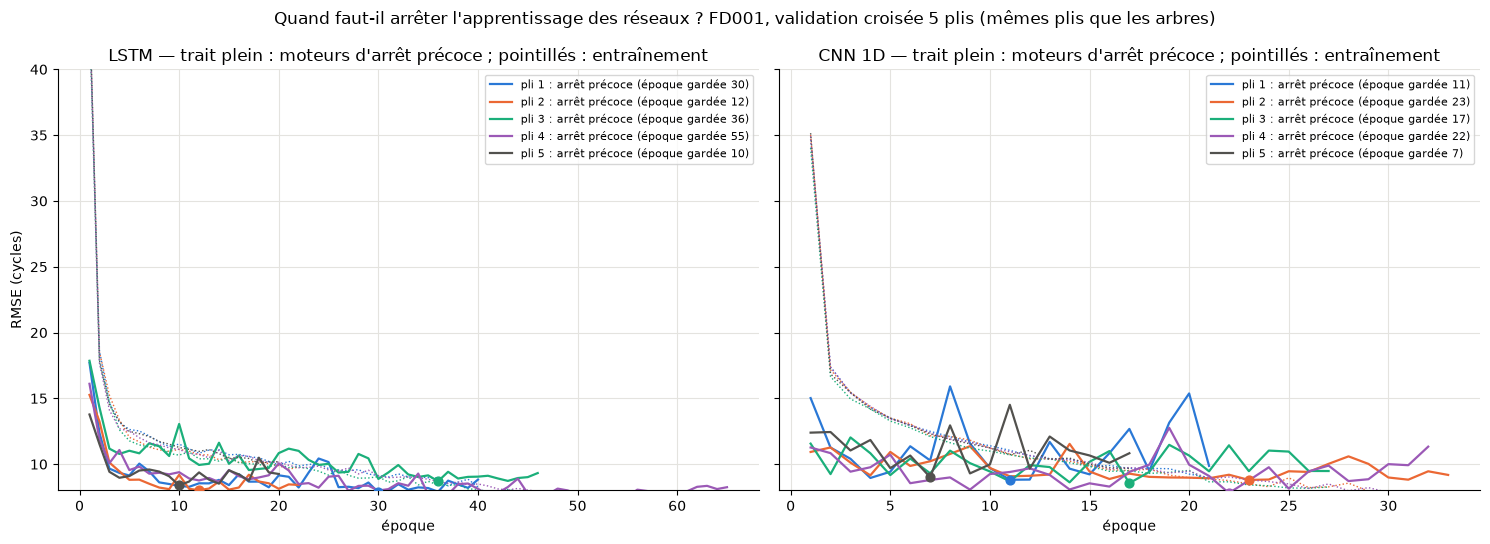

In [100]:
with open(os.path.join(DOSSIER_03B, "03b_historiques_fd001.json"), encoding="utf-8") as fichier:
    historiques = json.load(fichier)

couleurs_plis = ["#2a78d6", "#eb6834", "#1baf7a", "#9b59b6", "#52514e"]  # une couleur par pli
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), sharey=True)
for ax, nom_reseau in zip(axes, ["lstm", "cnn1d"]):
    plis_historique = historiques[nom_reseau]["plis"]
    for numero in range(len(plis_historique)):
        historique = plis_historique[numero]
        epoques = np.arange(1, len(historique["rmse_validation"]) + 1)
        rmse_entrainement = np.sqrt(np.array(historique["perte_entrainement"])) * ECHELLE_CIBLE
        ax.plot(epoques, historique["rmse_validation"], color=couleurs_plis[numero], linewidth=1.6,
                label=f"pli {numero + 1} : arrêt précoce (époque gardée {historique['meilleure_epoque']})")
        ax.plot(epoques, rmse_entrainement, color=couleurs_plis[numero], linewidth=1, linestyle=":")
        meilleure = historique["meilleure_epoque"]
        ax.scatter([meilleure], [historique["rmse_validation"][meilleure - 1]], color=couleurs_plis[numero], s=40, zorder=3)
    ax.set_title(f"{NOMS_AFFICHES[nom_reseau]} — trait plein : moteurs d'arrêt précoce ; pointillés : entraînement")
    ax.set_xlabel("époque")
    ax.set_ylim(8, 40)
    ax.legend(fontsize=8)
axes[0].set_ylabel("RMSE (cycles)")
fig.suptitle("Quand faut-il arrêter l'apprentissage des réseaux ? FD001, validation croisée 5 plis (mêmes plis que les arbres)")
plt.tight_layout()
plt.show()

### Décision de la section 12

**Décision : ne pas chercher d'abord plus de moteurs du même type.** **Chiffre** : de 60 à 80 moteurs, le RMSE de validation de XGBoost Phase 3 ne baisse que de 0,32 cycle (même sens sur 5/5 plis), sous le bruit entre plis (écart-type 1,25) ; le modèle est déjà à 17,86 avec 40 moteurs (cellule 12.6). Le plancher vient surtout des variables et du modèle, ce que la section 6 a confirmé (16,9 → 9,3 avec `ecartinit_20`). Pour les réseaux, l'arrêt précoce coupe entre les époques 7 et 55 selon le pli et le réseau (figure 12.9). **Limite** : FD003 n'est pas « plus de FD001 » (deux modes de panne) ; l'effet d'un mélange FD001 + FD003 n'est pas mesuré.

## 13. L'alerte « panne dans les N prochains cycles » : régression ou classifieur dédié ?

*Repris du notebook `04b_metriques_classification` : résumé de l'approche 2 et de la section 11 (ce qui justifie le choix de la régression), puis la section 8 (« combien de cycles d'avance »), avec les cellules du 04b dont elle a besoin. La présentation complète de l'alerte (approche 1, choix du seuil, matrices de confusion, ROC et précision-rappel) est dans `resultats/FD00X`, section 5.*

**Ce qui a fondé la décision (ancien modèle)** : XGBoost Phase 3, 46 variables.

### 13.1 Résumé : pourquoi l'alerte est dérivée de la régression (04b, approche 2 et section 11)

- **Deux approches comparées sur les mêmes plis** (`StratifiedGroupKFold`, un jeu de plis par N = 15, 30, 50) : (1) alerte dérivée de la régression, « RUL prédite ≤ seuil », score `-RUL prédite` ; (2) classifieurs dédiés entraînés sur l'étiquette « RUL vraie ≤ N » : `LogisticRegression` (avec `StandardScaler` réappris dans chaque pli) et `XGBClassifier` (mêmes réglages que le régresseur), contre une baseline aléatoire (AUC ≈ 0,5).
- **L'AUC ROC ne départage pas les approches** : 0,977 à 0,996 pour les trois (écarts de 0,000 à 0,002). La courbe précision-rappel est plus informative (ligne du hasard = proportion de positifs : 0,078 / 0,150 / 0,247).
- **Test apparié sur 5 plis (section 11 du 04b)** : aucune différence détectable à N = 15 et N = 50 (p de 0,31 à 0,95 pour la précision moyenne). **À N = 30, la `LogisticRegression` fait mieux que la régression sur les 5 plis** : précision moyenne 0,961 contre 0,951 (p du test t = 0,003 ; AUC 0,9914 contre 0,9887). Le Wilcoxon plafonne à 0,062 avec 5 plis et ne peut pas conclure. Question possible du jury.
- **Choix retenu : la régression**, pour sa simplicité : un seul modèle pour tous les N, un seuil lisible en cycles (« alerte si RUL prédite ≤ s »), choisi sur la validation avec un rappel minimal de 0,99 (décision du 2026-11-04). Ce n'est plus « les trois se valent » à N = 30 : c'est dit.

Code et sorties complètes : notebook 04b au tag `v1-avant-reorganisation`.

### 13.2 Ce dont la section 8 du 04b a besoin : étiquettes, plis, prédictions hors-pli, seuil

In [101]:
from sklearn.metrics import precision_recall_curve
from sklearn.model_selection import StratifiedGroupKFold
from xgboost import XGBRegressor

FENETRE = 5         # fenetre glissante (Phase 1/3)
PLAFOND_RUL = 125   # plafond de la RUL (Phase 2)
VALEURS_N = [15, 30, 50]  # les trois horizons testes, N n'etant pas encore choisi par l'equipe
GRAINE = 42

# --- Train : meme chaine que le notebook 03 (src/features.py : capteurs constants, min-max, lissage, RUL cappee, features) ---
contexte_04b = preparer_train(fenetre=FENETRE, plafond=PLAFOND_RUL)
train = contexte_04b["train"]      # le train enrichi (garde la RUL brute, colonne "RUL")
X = contexte_04b["X"]              # 46 features
y_rul = contexte_04b["y"]          # RUL plafonnee a 125 (cible de la regression)
groups = contexte_04b["groups"]    # un identifiant de moteur par ligne, pour ne jamais separer un moteur
assert X.shape[1] == 46, f"attendu 46 features, trouve {X.shape[1]}"
print(f"X : {X.shape}, {groups.nunique()} moteurs")

# RUL vraie du test officiel (RUL_FD001.txt), lue seulement pour COMPTER les positifs dans le tableau suivant
# (04b, cellule 4) : aucun modele n'est evalue sur le test dans cette section
from src.features import charger_rul_test
y_test_rul = charger_rul_test()
assert len(y_test_rul) == 100

X : (20631, 46), 100 moteurs


In [102]:
def fabriquer_etiquettes(rul, n):
    """
    Transforme une RUL (en cycles) en etiquette binaire : 1 si RUL <= n (moteur a retirer), 0 sinon.

    N est un SEUIL CHOISI, pas une valeur deduite des donnees. Analogie : le "batterie faible" d'un
    telephone se declenche a 20 % parce que quelqu'un l'a decide. Ici, N = "de combien de cycles
    veut-on etre prevenu avant la panne". Plus N est grand, plus l'alerte arrive tot (plus de
    positifs, dont plus de fausses alertes). L'equipe n'a pas choisi : on teste 15, 30 et 50.

    Pourquoi n + 1 positifs par moteur : la RUL descend de 1 par cycle, donc un moteur passe une fois
    par chaque valeur 0, 1, ..., n, soit n + 1 lignes. Exemple n = 10 : 100 moteurs x 11 = 1 100
    lignes positives (sur 20 631), le reste vaut 0.

    Parameters
    ----------
    rul : array-like
        Les valeurs de RUL (vraies).
    n : int
        L'horizon d'alerte, en cycles.

    Returns
    -------
    numpy.ndarray
        Tableau d'entiers 0/1, de meme longueur que `rul`.
    """
    etiquettes = []  # une etiquette par valeur de RUL
    for valeur in rul:
        if valeur <= n:  # panne dans les n prochains cycles (borne incluse : RUL = n est positif)
            etiquettes.append(1)
        else:
            etiquettes.append(0)
    return np.array(etiquettes)

# sanity check sur des valeurs ou la reponse est evidente
assert list(fabriquer_etiquettes([0, 15, 16, 125], 15)) == [1, 1, 0, 0]

# Comptage des positifs pour chaque N : train = 100 moteurs x (n + 1) lignes (16, 31, 51 -> 1600, 3100, 5100).
# Le test n'a qu'une ligne par moteur (dernier cycle observe), d'ou une proportion de positifs plus elevee.
print("N    | train/validation (20631 lignes) | test officiel (100 moteurs)")
for n in VALEURS_N:
    etiq_train = fabriquer_etiquettes(y_rul.values, n)  # etiquettes sur les 20 631 lignes
    etiq_test = fabriquer_etiquettes(y_test_rul, n)     # etiquettes sur les 100 moteurs du test
    print(f"{n:<4d} | {etiq_train.sum():6d} positifs = {100 * etiq_train.mean():5.1f} %      | {etiq_test.sum():4d} positifs = {100 * etiq_test.mean():5.1f} %")

N    | train/validation (20631 lignes) | test officiel (100 moteurs)
15   |   1600 positifs =   7.8 %      |   10 positifs =  10.0 %
30   |   3100 positifs =  15.0 %      |   25 positifs =  25.0 %
50   |   5100 positifs =  24.7 %      |   33 positifs =  33.0 %


In [103]:
etiquettes_par_n = {}  # n -> tableau 0/1 de la validation
plis_par_n = {}        # n -> liste de 5 couples (indices_train, indices_val)

for n in VALEURS_N:
    etiquettes = fabriquer_etiquettes(y_rul.values, n)
    etiquettes_par_n[n] = etiquettes

    # Group : un moteur reste entier dans un pli ; Stratified : les positifs sont repartis equitablement entre plis
    sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=GRAINE)
    plis = list(sgkf.split(X, etiquettes, groups=groups))  # calcule UNE fois, reutilise partout
    plis_par_n[n] = plis

    parts_positifs = []  # part de positifs de chaque pli de validation
    for i, (idx_train, idx_val) in enumerate(plis):
        # garde-fou anti-fuite : aucun moteur des deux cotes du pli
        moteurs_train = set(groups.iloc[idx_train])
        moteurs_val = set(groups.iloc[idx_val])
        assert len(moteurs_train & moteurs_val) == 0, "un moteur est present des deux cotes !"
        parts_positifs.append(100 * etiquettes[idx_val].mean())
    print(f"N={n} : 5 plis de 20 moteurs, part de positifs par pli de {min(parts_positifs):.1f} % a {max(parts_positifs):.1f} % (global {100 * etiquettes.mean():.1f} %)")

N=15 : 5 plis de 20 moteurs, part de positifs par pli de 7.7 % a 7.8 % (global 7.8 %)
N=30 : 5 plis de 20 moteurs, part de positifs par pli de 15.0 % a 15.0 % (global 15.0 %)
N=50 : 5 plis de 20 moteurs, part de positifs par pli de 24.7 % a 24.8 % (global 24.7 %)


In [104]:
# Predictions hors-pli de la regression, pour chaque N (modele tout neuf a chaque pli)
rul_predite_par_n = {}  # n -> RUL predite pour chaque ligne de validation (hors-pli)
pli_de_chaque_ligne_par_n = {}  # n -> numero du pli de validation de chaque ligne

for n in VALEURS_N:
    predictions = np.zeros(len(X))  # une prediction par ligne, remplie pli par pli
    numero_pli = np.zeros(len(X), dtype=int)

    for i, (idx_train, idx_val) in enumerate(plis_par_n[n]):
        modele = XGBRegressor(n_estimators=200, max_depth=5, learning_rate=0.05, random_state=GRAINE, n_jobs=NB_COEURS)
        modele.fit(X.iloc[idx_train], y_rul.iloc[idx_train])  # apprend sur les moteurs d'entrainement du pli
        predictions[idx_val] = modele.predict(X.iloc[idx_val])  # predit des moteurs jamais vus
        numero_pli[idx_val] = i

    rul_predite_par_n[n] = predictions
    pli_de_chaque_ligne_par_n[n] = numero_pli

    # sanity check : RMSE hors-pli, a comparer au ~16.9 de la Phase 3 (autres plis, donc pas identique)
    rmse_hors_pli = np.sqrt(np.mean((y_rul.values - predictions) ** 2))  # (renomme : ne pas masquer la fonction rmse de src/)
    print(f"N={n} : RMSE hors-pli de la regression = {rmse_hors_pli:.2f} (Phase 3 : 16.86 sur d'autres plis)")
    assert 14 < rmse_hors_pli < 20, "RMSE hors-pli incoherent avec la Phase 3, a verifier"

N=15 : RMSE hors-pli de la regression = 16.84 (Phase 3 : 16.86 sur d'autres plis)


N=30 : RMSE hors-pli de la regression = 16.45 (Phase 3 : 16.86 sur d'autres plis)


N=50 : RMSE hors-pli de la regression = 16.61 (Phase 3 : 16.86 sur d'autres plis)


Choix du seuil de décision, **règle écrite avant de regarder les résultats** (04b, section 5) : on fixe un **rappel minimal** (0,99 : un moteur proche de la panne laissé en vol est le cas grave) ; parmi tous les seuils qui l'atteignent, on retient celui qui **maximise la précision** ; à précision égale, le plus sévère (le moins d'alertes). La fonction du 04b est gardée telle quelle : `choisir_seuil_alerte` de `src/evaluation.py` applique la même règle, mais départage les égalités de précision par le plus grand rappel ; garder celle du 04b redonne exactement ses chiffres.

**À trancher** : les notebooks `resultats/FD00X` (section 5) choisissent leur seuil avec la règle du notebook 05 (G.5), rappel minimal 0,95 (`RAPPEL_MINIMUM`, `src/evaluation_sous_jeu.py`), et non 0,99. Les deux règles coexistent dans la v2 ; la décision revient à l'équipe.

In [105]:
def choisir_seuil(y_vrai, score, rappel_min):
    """
    Choisit le seuil de decision : parmi les seuils dont le rappel est >= rappel_min,
    celui qui maximise la precision ; a precision egale, le plus severe (le plus haut).

    Parameters
    ----------
    y_vrai : array-like de 0/1
        Les vraies etiquettes (du jeu sur lequel on choisit, jamais le test).
    score : array-like de float
        Score continu (plus il est haut, plus le moteur est urgent).
    rappel_min : float
        Rappel minimal exige (entre 0 et 1).

    Returns
    -------
    float
        Le seuil retenu : alerte si score >= seuil.
    """
    precisions, rappels, seuils = precision_recall_curve(y_vrai, score)
    # precision_recall_curve renvoie une precision et un rappel de plus que de seuils
    # (le point "aucune alerte") : on ne regarde que les points qui correspondent a un seuil
    meilleur_seuil = None
    meilleure_precision = -1.0
    for i in range(len(seuils)):  # un candidat de seuil a la fois
        if rappels[i] >= rappel_min:  # le seuil respecte la contrainte de securite
            if precisions[i] > meilleure_precision or (precisions[i] == meilleure_precision and seuils[i] > meilleur_seuil):
                meilleure_precision = precisions[i]
                meilleur_seuil = seuils[i]
    return meilleur_seuil

# sanity check sur un exemple jouet ou la reponse se calcule a la main :
# scores 0.9, 0.8, 0.4, 0.3 avec vraies etiquettes 1, 1, 0, 1 -> pour un rappel >= 1, il faut descendre jusqu'a 0.3
assert choisir_seuil([1, 1, 0, 1], [0.9, 0.8, 0.4, 0.3], 1.0) == 0.3
assert choisir_seuil([1, 1, 0, 1], [0.9, 0.8, 0.4, 0.3], 0.6) == 0.8  # 2 positifs sur 3 detectes, precision 1

In [106]:
# regle retenue : approche regression, rappel minimal 0,99, seuil choisi sur toute la validation hors-pli
NOM_RETENU = "Regression XGBoost (-RUL predite)"
scores_par_n = {}  # n -> {approche : score continu hors-pli} ; ici seulement l'approche retenue (score = -RUL predite)
seuil_retenu_par_n = {}  # n -> seuil sur le score (= -RUL predite) ; alerte si score >= seuil
for n in VALEURS_N:
    scores_par_n[n] = {}
    scores_par_n[n][NOM_RETENU] = -rul_predite_par_n[n]  # plus la RUL predite est basse, plus le moteur est urgent
    seuil_retenu_par_n[n] = choisir_seuil(etiquettes_par_n[n], scores_par_n[n][NOM_RETENU], 0.99)
    print(f"N={n} : alerte si RUL predite <= {-seuil_retenu_par_n[n]:.1f} cycles")

N=15 : alerte si RUL predite <= 26.6 cycles
N=30 : alerte si RUL predite <= 63.9 cycles
N=50 : alerte si RUL predite <= 91.0 cycles


### 13.3 Lecture par moteur (validation) : combien de cycles d'avance avant la panne ? (04b, section 8)

Hors protocole, ajouté pour parler le langage de la maintenance. Avec la règle retenue, on cherche pour chaque moteur le **premier cycle où l'alerte se déclenche** et on note sa vraie RUL (non plafonnée) : c'est l'**avance** en cycles. Une alerte à RUL > N est jugée « précoce » (avant la fenêtre visée).

**À décider (Matisse)** : le plan (8.2) note que rien ne réutilise cette section, mais qu'elle est parlante pour un jury. Elle est **gardée** ici en attendant la décision (principe 0 : en cas de doute, on garde).

In [107]:
rul_brute = train["RUL"].values  # RUL vraie non plafonnee (le plafond a 125 ne sert qu'a l'entrainement)
print(f"{'N':>3s} | {'moteurs jamais alertes':>22s} | {'1re alerte dans la fenetre (RUL<=N)':>36s} | {'1re alerte precoce (RUL>N)':>26s} | {'avance mediane':>14s} | {'avance min':>10s}")
for n in VALEURS_N:
    alerte = scores_par_n[n][NOM_RETENU] >= seuil_retenu_par_n[n]  # alerte ligne par ligne
    avances = []  # avance (RUL vraie) au premier cycle d'alerte, pour les moteurs alertes
    nb_jamais = 0
    nb_dans_fenetre = 0
    nb_precoce = 0
    for moteur_id in groups.unique():  # un moteur a la fois
        positions = np.where(groups.values == moteur_id)[0]  # lignes du moteur, dans l'ordre des cycles
        premiere_alerte = None
        for position in positions:  # on cherche le premier cycle en alerte
            if alerte[position]:
                premiere_alerte = position
                break
        if premiere_alerte is None:
            nb_jamais += 1
        else:
            avance = rul_brute[premiere_alerte]
            avances.append(avance)
            if avance <= n:
                nb_dans_fenetre += 1
            else:
                nb_precoce += 1
    print(f"{n:3d} | {nb_jamais:22d} | {nb_dans_fenetre:36d} | {nb_precoce:26d} | {np.median(avances):14.0f} | {np.min(avances):10.0f}")

  N | moteurs jamais alertes |  1re alerte dans la fenetre (RUL<=N) | 1re alerte precoce (RUL>N) | avance mediane | avance min
 15 |                      0 |                                   10 |                         90 |             24 |         12
 30 |                      0 |                                    4 |                         96 |             59 |         26
 50 |                      0 |                                    6 |                         94 |             87 |         40


### Décision de la section 13

**Décision : l'alerte est dérivée de la régression** (« RUL prédite ≤ seuil », seuil choisi sur la validation au rappel minimal de 0,99), pour sa simplicité et son seuil lisible en cycles. **Chiffres** : l'AUC des trois approches va de 0,977 à 0,996 (indiscernables) ; seule exception, la `LogisticRegression` à N = 30 (précision moyenne 0,961 contre 0,951, p = 0,003, 5 plis). Seuils de cette exécution (validation, XGBoost Phase 3) : alerte si RUL prédite ≤ 26,6 / 63,9 / 91,0 cycles pour N = 15 / 30 / 50 (cellule 13.2). Les seuils des modèles retenus sont choisis de la même façon dans `resultats/FD00X`, section 5. **À décider (Matisse)** : garder ou non la lecture « combien de cycles d'avance » (13.3).

## 14. Décision finale : les réglages retenus des 6 modèles

Tableau récapitulatif, lu dans le code (jamais recopié à la main) : `src/config_modele.py` pour les arbres et la baseline, `src/optimisation_reseaux.py` pour les réseaux (`CONFIGS_RESEAUX_RETENUES`, `ENSEMBLES_RETENUS`). Les chiffres de test cités par `src/config_modele.py` sont ceux de FD001 ; ceux de tous les sous-jeux sont dans `resultats/FD00X`.

In [108]:
from src import optimisation_reseaux as opt  # reglages des reseaux retenus (04h)

# --- les 4 modeles a arbres et la baseline : une ligne par configuration de src/config_modele.py ---
configs_finales = {}
configs_finales["reference_naive"] = CONFIG_REFERENCE_NAIVE
configs_finales["random_forest"] = CONFIG_RANDOM_FOREST_FINAL
configs_finales["lightgbm"] = CONFIG_LIGHTGBM_FINAL
configs_finales["xgboost"] = CONFIG_XGBOOST_FINAL

lignes = []
for cle in configs_finales:
    config = configs_finales[cle]
    ligne = {}
    ligne["modele"] = cle
    ligne["description"] = decrire_config(config)
    ligne["entrees"] = "aucune (moyenne de y)"
    if cle != "reference_naive":
        ligne["entrees"] = "31 variables : capteurs lisses, time_cycles, ecartinit_20"
    ligne["reglages"] = json.dumps(config["hyperparametres"])
    ligne["regle de choix"] = config.get("regle_de_choix", "baseline (protocole, section 2)")
    ligne["test FD001 cite (RMSE)"] = config.get("metriques_test", {}).get("rmse", "-")
    lignes.append(ligne)

# --- les reseaux : un LSTM et un CNN 1D par sous-jeu (FD001 a FD004, notebook 04h) ---
for sous_jeu in opt.CONFIGS_RESEAUX_RETENUES:
    for reseau in opt.CONFIGS_RESEAUX_RETENUES[sous_jeu]:
        config = opt.CONFIGS_RESEAUX_RETENUES[sous_jeu][reseau]
        ligne = {}
        ligne["modele"] = f"{reseau} ({sous_jeu})"
        ligne["description"] = f"{config['type']}, {config['nb_epoques_final']} epoques (modele final)"
        ligne["entrees"] = (f"fenetre {config['entrees']['longueur']} cycles, ecartinit_{config['entrees']['ecart_initial']}, "
                            f"capteurs lisses, time_cycles / 100")
        ligne["reglages"] = json.dumps(config["hyperparametres"])
        ensemble = opt.ENSEMBLES_RETENUS[sous_jeu]
        # le meilleur essai Optuna a-t-il passe la regle de confirmation ? (lu dans le fichier du 04h)
        if lire_json(sous_jeu, "confirmation_" + reseau)["comparaison"]["retenu"]:
            origine = "Optuna + confirmation (04h)"
        else:
            origine = "reglages du 03b (candidat Optuna non confirme, 04h)"
        if ensemble["reseau"] == reseau:
            ligne["regle de choix"] = f"{origine} ; ensemble de {len(ensemble['graines'])} graines {ensemble['graines']}"
        else:
            ligne["regle de choix"] = f"{origine} ; non retenu dans l'ensemble"
        ligne["test FD001 cite (RMSE)"] = "-"
        lignes.append(ligne)

tableau_decision = pd.DataFrame(lignes).set_index("modele")
print("Sous-jeux avec reseaux (04h) :", list(opt.CONFIGS_RESEAUX_RETENUES.keys()))
tableau_decision

Sous-jeux avec reseaux (04h) : ['FD001', 'FD002', 'FD003', 'FD004']


,description,entrees,reglages,regle de choix,test FD001 cite (RMSE)
modele,,,,,
reference_naive,"Reference naive (moyenne) (reference_naive, pe...",aucune (moyenne de y),{},"baseline (protocole, section 2)",-
random_forest,Random Forest (reglages finaux 04g) (random_fo...,"31 variables : capteurs lisses, time_cycles, e...","{""n_estimators"": 391, ""max_depth"": 18, ""min_sa...",Optuna 40 essais (notebook 04g),13.14
lightgbm,"LightGBM (reglages finaux 04g) (lightgbm, pert...","31 variables : capteurs lisses, time_cycles, e...","{""n_estimators"": 549, ""learning_rate"": 0.02744...",Optuna 40 essais (notebook 04g),12.76
xgboost,"XGBoost (reglages finaux 04f) (xgboost, perte ...","31 variables : capteurs lisses, time_cycles, e...","{""max_depth"": 4, ""learning_rate"": 0.0633, ""n_e...",Optuna 60 essais + confirmation sur 10 decoupa...,12.73
lstm (FD001),"lstm, 24 epoques (modele final)","fenetre 20 cycles, ecartinit_30, capteurs liss...","{""taille_cachee"": 32, ""nb_couches"": 2, ""dropou...",Optuna + confirmation (04h) ; ensemble de 5 gr...,-
cnn1d (FD001),"cnn1d, 7 epoques (modele final)","fenetre 20 cycles, ecartinit_30, capteurs liss...","{""canaux"": [32, 32, 32], ""noyaux"": [9, 9, 9], ...",Optuna + confirmation (04h) ; non retenu dans ...,-
lstm (FD002),"lstm, 14 epoques (modele final)","fenetre 20 cycles, ecartinit_20, capteurs liss...","{""taille_cachee"": 32, ""nb_couches"": 3, ""dropou...",Optuna + confirmation (04h) ; ensemble de 5 gr...,-
cnn1d (FD002),"cnn1d, 2 epoques (modele final)","fenetre 30 cycles, ecartinit_20, capteurs liss...","{""canaux"": [32, 64, 64], ""noyaux"": [5, 5, 3], ...","reglages du 03b (candidat Optuna non confirme,...",-
lstm (FD003),"lstm, 14 epoques (modele final)","fenetre 25 cycles, ecartinit_30, capteurs liss...","{""taille_cachee"": 96, ""nb_couches"": 2, ""dropou...",Optuna + confirmation (04h) ; ensemble de 5 gr...,-


### Ce qui est décidé, en une phrase par ligne

| Décision | Chiffre qui la justifie | Section |
|---|---|---|
| Cible : RUL plafonnée à 125 | écart-type de `sensor_11` multiplié par 2,02 à 2,66 en fin de vie | 2 |
| Mêmes plis par moteur pour tous les modèles, score NASA 13 / 10 | référence XGBoost Phase 3 : RMSE CV 16,87 | 3 |
| Réseaux : fenêtre glissante, `time_cycles` / 100 en entrée | RMSE de décision 12,98 avec contre 14,99 sans | 4 |
| Garder des réseaux malgré leur coût | LSTM 8,94 contre 16,87 en validation croisée (anciens modèles) | 5 |
| 31 variables, dont `ecartinit_20` | gain apparié +7,38 contre `ref16`, 15/15 | 6 |
| `ecartinit_20` pour les 5 modèles qui apprennent | baisse de 4,76 à 7,51 cycles, p ≤ 2,2e-13 | 7 |
| Réglages XGBoost : Optuna sur 31 variables (exception assumée) | `CONFIG_XGBOOST_FINAL` : gain confirmé +0,229, 10/10 découpages neufs (seuil de 0,3 non atteint) | 9 |
| LightGBM et Random Forest : Optuna, gardés à côté de XGBoost | écart −0,047 et +0,77 cycle contre XGBoost | 9 |
| Réseaux FD001 / FD002 : ensemble de 5 LSTM Optuna | validation 9,34 → 7,38 (FD001), 10,28 → 9,50 (FD002) | 10 |
| Réseaux FD003 / FD004 : ensemble de 5 LSTM (Optuna confirmé sur FD003, réglages du 03b sur FD004) ; *mis à jour le 2026-11-08, cette ligne disait avant « pas de réseau pour FD003 et FD004 en v2 »* | validation 8,54 → 7,59 (FD003), 11,11 → 10,74 (FD004) | 10 |
| Chercher le gain dans les variables, pas dans la complexité | train 10,94 contre validation 16,87 ; plancher des features | 11 |
| Pas prioritaire : plus de moteurs du même type | gain 60 → 80 moteurs 0,32 cycle, sous le bruit | 12 |
| Alerte dérivée de la régression, rappel minimal 0,99 | AUC 0,977 à 0,996 pour les 3 approches | 13 |

**Ce qui reste ouvert** : le seuil de 0,3 cycle n'est pas atteint par le XGBoost final (exception d'équipe, section 9.2) ; les recherches Optuna de LightGBM et Random Forest ne sont pas relançables depuis le dépôt (9.3) ; les réglages des arbres sont choisis sur FD001 seulement et appliqués tels quels à FD002–FD004 ; la section 13.3 attend la décision de Matisse.

In [109]:
duree_notebook = time.perf_counter() - debut_notebook
print(f"Notebook execute en {duree_notebook / 60:.1f} minutes.")

Notebook execute en 9.5 minutes.
